# PRACTICA EVALUACIÓN FINAL - PARTE I #

Esta practica final tiene por objetivo evaluar los conocimientos que se han adquirido por parte del alumno a lo largo de los distintos temas del módulo. La práctica se divide en 2 partes: ésta primera parte que permite evaluar los temas de Data Understanding, Data Preparation, Regresión Lineal, Regresión Logística, Selección de variables, Análisis de componentes principales (PCA), Análisis Factorial y técnicas de clustering.

Supone por tanto un 75% de la calificación correspondiente a la Prática de Evaluación Final completa incluyendo ambas partes. Por tanto la parte 2, incluirá ejercicios de evaluación de los temas de series temporales y por ello supondrá un 25%.

En conjunto, toda la Práctica de Evaluación Final (ambas partes) tiene un peso del 60% de la nota final (el test de evaluación sería el 40% restante).

Es importante tener presente que, dado que se va a utilizar el mismo conjunto de datos para evaluar distintos temas del módulo, se perseguirán objetivos distintos en distintas partes de esta práctica parte I. Por ejemplo, para el modelo de regresión lineal, se tomará como variable objetivo ***Salary***, mientras que para la regresión logística, la variable objetivo será ***Gender***. Se deberá tener presente esto especialmente a la hora de llevar a cabo toda la fase de entendimiento y preparación de los datos ya que habrá transformaciones y analisis que serán comunes para ambos modelos y otras que serán específicas de cada modelo. en este sentido, el alumno deberá organizarse como mejor considere para llevar a cabo la práctica siguiendo el guión establecido pero con cierta flexibilidad para incluir todo aquello que considere oportuno en el momento que considere oportuno.

Por la misma razón, la parte de clustering no tiene variable objetivo como tal pero el analisis exploratorio y la preparación de los datos puede llevar a que haya particularidades para sus ejercicios además de las comunes.

Comenzando con esta primera parte de la práctica, en el primer bloque de código, conviene cargar las librerías que se van a utilizar a lo largo del notebook.

In [89]:
# ============================================================
# IMPORTS
# ============================================================

# Manipulación de datos
import pandas as pd
import numpy as np
import itertools

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy.stats import chi2_contingency, zscore, ttest_ind
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Preprocesamiento
from sklearn.preprocessing import StandardScaler

# Modelos
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# Evaluación y validación
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import (
    roc_curve, auc,
    confusion_matrix, classification_report,
    silhouette_score, r2_score
)

# Pipeline
from sklearn.pipeline import Pipeline

En el siguiente paso vamos a proceder a cargar el fichero Salary_MD.csv que servirá como conjunto de datos para llevar a cabo toda la evaluación de esta parte I. Se trata de un fichero en el que cada registro es un empleado y sobre él, cada campo aporta información laboral y de formación.

In [90]:
# Cargar el fichero de datos en un DataFrame
df = pd.read_csv('Salary_MD.csv')

En los siguientes bloques de código el alumno debe programar las sentencias de código que considere oportunas para hacerse una idea general de los datos y de las variables. Visualización de datos, gráficos, etc. Los bloques son orientativos, el alumno puede añadir cuantos considere y codificarlos según su criterio.

In [91]:
# Mostrar los 10 primeros registros
df.head(10)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Country,Race,Senior
0,32,Male,1.0,Software Engineer,5.0,90000,UK,White,0
1,28,Female,2.0,Data Analyst,3.0,65000,USA,NaN,0
2,45,Male,3.0,Manager,15.0,150000,Canada,White,1
3,36,Female,1.0,Sales Associate,7.0,60000,USA,Hispanic,0
4,52,Male,2.0,Director,20.0,200000,USA,Asian,0
5,29,Male,1.0,Marketing Analyst,2.0,55000,USA,Hispanic,0
6,42,Female,2.0,Product Manager,12.0,120000,USA,Asian,0
7,31,Male,1.0,Sales Manager,4.0,80000,China,Korean,0
8,26,Female,1.0,Marketing Coordinator,1.0,45000,China,Chinese,0
9,38,Male,3.0,Scientist,10.0,110000,Australia,Australian,1


### Observación: Primeros 10 registros
El dataset contiene 9 variables: 4 numéricas (`Age`, `Years of Experience`, `Salary`, 
`Senior`), 1, aparentemente, ordinal codificada numéricamente (`Education Level`) y 4 categóricas 
(`Gender`, `Job Title`, `Country`, `Race`). Ademas, ya se ve un NaN en `Race` y 
`Education Level` y  `Years of Experience` aparecen codificada como float, lo que nos podria anticipar la presencia de valores nulos, 
porque tengo entendido que así los maneja pandas y ademas no tendría sentido, en principio, decimales en estas variables.

In [92]:
# Describir el DataFrame
df.describe()

,Age,Education Level,Years of Experience,Salary,Senior
count,6684.000000,6661.000000,6684.000000,6.684000e+03,6684.000000
mean,33.147816,1.623480,8.161655,1.164338e+05,0.143477
std,8.619754,0.880016,7.356860,6.738536e+04,0.350585
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,28.000000,1.000000,3.000000,7.000000e+04,0.000000
50%,32.000000,1.000000,7.000000,1.150000e+05,0.000000
75%,38.000000,2.000000,12.000000,1.600000e+05,0.000000
max,110.000000,3.000000,200.000000,2.159320e+06,1.000000


### Observación: Estadísticas descriptivas
Se detectan valores raros en varias variables numéricas: `Age` presenta un mínimo 
de 0 y un máximo de 110 (definitivamente no esperariamos el 0, y por otro lado, el 110 es sospechoso porque es muy alto), `Years of Experience` llega hasta 200 y `Salary` tiene registros con valor 0 y un máximo de 2,159,320 muy alejado de la media (116,433). 
Estas variables requerirán un análisis de outliers en profundidad. Además, `Education Level` muestra 23 nulos al tener un count inferior al resto.

In [93]:
# Mostrar las columnas y tipos de datos
df.dtypes

Age                      int64
Gender                  object
Education Level        float64
Job Title               object
Years of Experience    float64
Salary                   int64
Country                 object
Race                    object
Senior                   int64
dtype: object

### Observación: Tipos de datos
Nuevamente como habiamos adelantado `Education Level` y `Years of Experience` parecen ser float64 por la presencia de NaN 
(pandas convierte automáticamente a float cuando hay nulos en columnas enteras). 
El resto de numéricas son int64 y las categóricas object. No hay tipos incorrectos 
evidentes aunque `Education Level` deberá tratarse como variable ordinal.

In [94]:
# Investigamos la variable `Education Level` más en detalle ya que hemos detectado un valor mínimo de 0 que no corresponde con los valores esperados (1, 2, 3).
print(df['Education Level'].value_counts(dropna=False))

Education Level
1.0    3009
2.0    1855
3.0    1365
0.0     432
NaN      23
Name: count, dtype: int64


### Observación: Education Level
La variable presenta 3 valores esperados (1.0, 2.0, 3.0) pero también contiene 
432 registros con valor 0.0 y 23 nulos. Creo que los ceros y los nulos son distintos y 
deberemos ver si requerirán tratamiento en la fase de preparación.

In [95]:
print(df['Job Title'].value_counts())
print(f"\nTotal de Job Titles únicos: {df['Job Title'].nunique()}")# ...

Job Title
Software Engineer                   804
Data Scientist                      511
Data Analyst                        387
Software Engineer Manager           376
Product Manager                     320
                                   ... 
Director of Human Capital             1
Advertising Coordinator               1
Account Executive                     1
Director of Business Development      1
Social Media Man                      1
Name: count, Length: 129, dtype: int64

Total de Job Titles únicos: 129


### Observación: Job Title
La variable contiene 129 valores únicos con una distribución muy desigual: 
`Software Engineer` tiene 804 registros mientras que muchas categorías 
tienen apenas 1 registro. Esta alta diferencia hace dificil usar la variable 
directamente y, a lo mejor, requeriría pensar en alguna estrategia de agrupación o 
recategorización si es que la queremos usar.

In [96]:
print(df['Years of Experience'].value_counts(dropna=False))
print(f"\nNulos en Years of Experience: {df['Years of Experience'].isna().sum()}")

Years of Experience
2.0      605
3.0      593
1.0      535
4.0      517
6.0      434
8.0      421
5.0      392
9.0      377
7.0      350
11.0     316
12.0     294
14.0     249
16.0     242
13.0     208
10.0     191
0.0      162
15.0     129
18.0     125
19.0     121
17.0     106
20.0      61
22.0      47
21.0      42
23.0      37
25.0      22
24.0      19
28.0      16
1.5       12
27.0      11
32.0      10
29.0       8
26.0       7
33.0       6
30.0       6
31.0       3
34.0       2
0.5        1
132.0      1
63.0       1
84.0       1
164.0      1
200.0      1
77.0       1
174.0      1
Name: count, dtype: int64

Nulos en Years of Experience: 0


### Observación: Years of Experience
La variable no tiene nulos y float64 esta bien porque hay decimales. 
Presenta además valores extremos como 174 años que son imposibles. Estos casos 
serán tratados en el análisis de outliers.

In [97]:
### Distribución de Gender
print(df['Gender'].value_counts(dropna=False))

Gender
Male      3649
Female    2964
NaN         71
Name: count, dtype: int64


### Observación: Gender
La variable tiene 71 nulos y está relativamente balanceada: 55% Male y 45% Female. 
El desbalance no es crítico pero igualmente tenemos que tener cuidado con los 71 nulos.

In [98]:
### Nulos por variable. Revisamos el total de nulos por columna antes de continuar con el EDA.
print(df.isna().sum())

Age                      0
Gender                  71
Education Level         23
Job Title               40
Years of Experience      0
Salary                   0
Country                 24
Race                   163
Senior                   0
dtype: int64


### Observación: Nulos por variable
Las variables con nulos son: `Race` (163), `Gender` (71), `Country` (24), 
`Education Level` (23) y `Job Title` (40). Las variables numéricas 
`Age`, `Years of Experience` y `Salary` no tienen nulos. 

In [99]:
### Distribución de Country y Race
print(df['Country'].value_counts(dropna=False))
print(f"\nTotal países únicos: {df['Country'].nunique()}")
print()
print(df['Race'].value_counts(dropna=False))
print(f"\nTotal razas únicas: {df['Race'].nunique()}")

Country
USA          1350
China        1339
Australia    1329
UK           1328
Canada       1314
NaN            24
Name: count, dtype: int64

Total países únicos: 5

Race
White               1902
Asian               1560
Korean               445
Australian           439
Chinese              435
Black                430
African American     345
Welsh                326
Mixed                325
Hispanic             314
NaN                  163
Name: count, dtype: int64

Total razas únicas: 10


### Observación: Country y Race
`Country` tiene solo 5 categorías muy bien balanceadas (~1,300 registros cada una) 
y 24 nulos, creo que muy manejable. `Race` tiene 10 categorías con distribución más desigual 
(White domina con 1,902) y 163 nulos. Llama la atención que hay categorías 
que no se distinguen bien como `Korean`, `Chinese` y `Asian` que podrían justificar
agruparse.

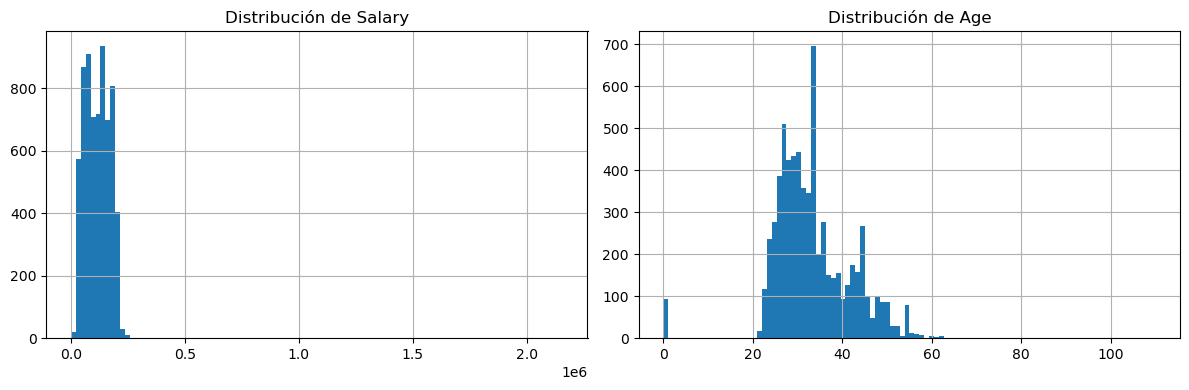

In [100]:
### Histograma de Salary
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Salary'].hist(bins=100, ax=axes[0])
axes[0].set_title('Distribución de Salary')

df['Age'].hist(bins=100, ax=axes[1])
axes[1].set_title('Distribución de Age')

plt.tight_layout()
plt.show()

### Observación: Distribución de Salary 
`Salary` presenta una distribución fuertemente sesgada a la derecha con outliers 
extremos que llegan hasta 2,159,320 muy por encima de la media (116,433). 

### Observación: Distribución de Age
La distribución presenta sesgo a la derecha con un pico concentrado entre 
28-30 años (aprox) y una cola que se extiende hasta los 60+. Se detectan además 
valores claramente anómalos en ambos extremos, con edades que van desde los 0 años y valores de 95 y 110 años que tampoco esperaríamos.

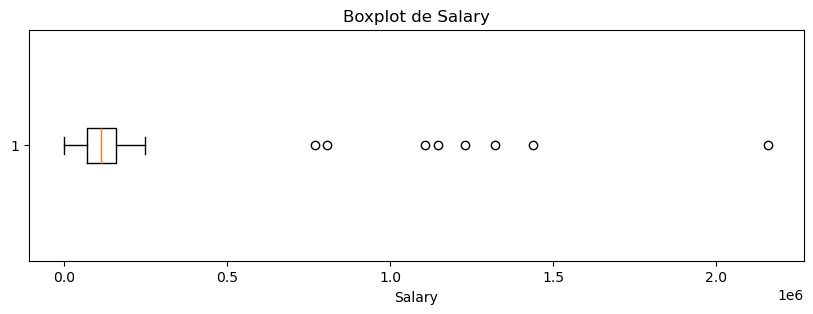

In [101]:
plt.figure(figsize=(10, 3))
plt.boxplot(df['Salary'], vert=False)
plt.title('Boxplot de Salary')
plt.xlabel('Salary')
plt.show()

### Observación: Boxplot de Salary
El boxplot confirma la presencia de outliers extremos en `Salary`. La caja 
se concentra entre 70,000 y 160,000 pero hay registros 
aislados que superan los 500,000 llegando hasta 2,159,320.

In [102]:
print(df['Age'].value_counts().sort_index())

Age
0       94
3        1
5        1
8        1
21      17
22      15
23     102
24     236
25     277
26     385
27     509
28     424
29     435
30     444
31     358
32     345
33     394
34     302
35     199
36     277
37     150
38     144
39     156
40      92
41     126
42     174
43     158
44     124
45     144
46     100
47      47
48      98
49      87
50      87
51      29
52      28
53       4
54      63
55      16
56      11
57       9
58       7
60       5
61       2
62       5
95       1
110      1
Name: count, dtype: int64


### Observación: Distribución de Age
La masa principal de datos se concentra entre 23 y 54 años. Sin embargo 
se detectan nuevamente valores raros en ambos extremos: edades bajas como 0 y valores de 95 y 110 años son 
muy raros.

In [103]:
df[df['Years of Experience'] > df['Age']]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Country,Race,Senior
31,0,Female,1.0,Accountant,4.0,55000,UK,NaN,0
243,0,Female,1.0,Marketing Analyst,6.0,70000,USA,Asian,0
377,0,Male,3.0,Data Scientist,5.0,180000,China,NaN,0
422,0,Female,1.0,Data Analyst,132.0,0,China,White,0
469,0,Male,NaN,NaN,2.0,115000,NaN,Asian,0
...,...,...,...,...,...,...,...,...,...
5713,0,Male,1.0,Product Designer,2.0,55000,Canada,Black,0
5718,0,Female,3.0,Research Scientist,12.0,170000,UK,NaN,0
5965,0,Male,1.0,Product Manager,1.0,60000,USA,African American,0
6337,0,Female,2.0,Content Marketing Manager,15.0,150000,China,Korean,0


### Observación: Years of Experience > Age
Hay 81 registros donde los años de experiencia superan a la edad, lo cual 
es lógicamente imposible. Casos extremos como 174 años de experiencia con 
edad 0 confirman que se trata de errores de introducción de datos. Estos 
registros deberian serán eliminados o corregidos en la fase de preparación.

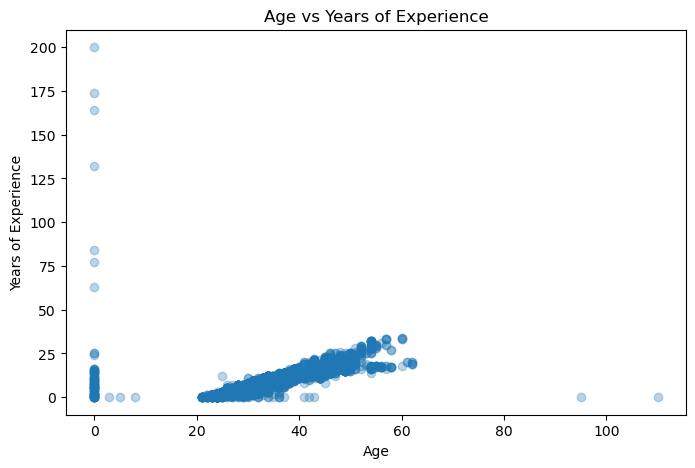

In [104]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Years of Experience'], alpha=0.3)
plt.xlabel('Age')
plt.ylabel('Years of Experience')
plt.title('Age vs Years of Experience')
plt.show()

### Observación: Age vs Years of Experience
El scatter confirma la relación lógica esperada entre ambas variables: 
a mayor edad, mayor experiencia. Sin embargo se identifican claramente 
dos grupos de errores, que ademas ya habiamos detectado antes. Registros con Age cercana a 0 pero con años de 
experiencia muy elevados (hasta 200), y registros con Age extremadamente 
alta (95, 110) pero experiencia cercana a 0. Considero que ambos grupos deberan ser atendidos  
en la fase de preparación.

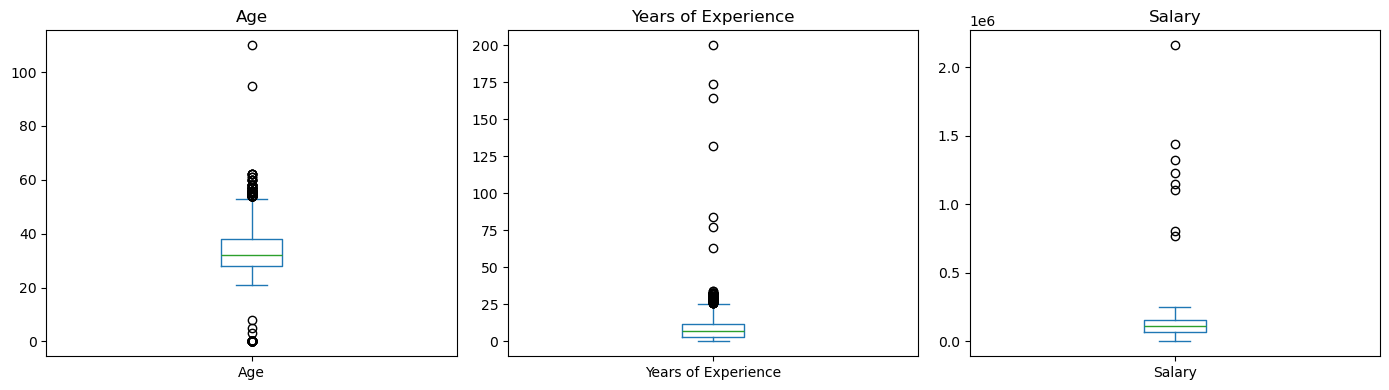

In [105]:
### Boxplots de variables numéricas. Visualizamos los outliers de todas las variables numéricas de forma comparativa.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df['Age'].plot(kind='box', ax=axes[0], title='Age')
df['Years of Experience'].plot(kind='box', ax=axes[1], title='Years of Experience')
df['Salary'].plot(kind='box', ax=axes[2], title='Salary')

plt.tight_layout()
plt.show()

### Observación: Boxplots de variables numéricas
Las tres variables presentan outliers claros. `Age` tiene outliers en ambos 
extremos (cercanos a 0 y superiores a 60). `Years of Experience` muestra 
outliers extremos superiores a 60 llegando hasta 200. Y como ya habiamos visto, `Salary` presenta 
outliers muy dispersos por encima de 500,000 llegando hasta 2,159,320. 


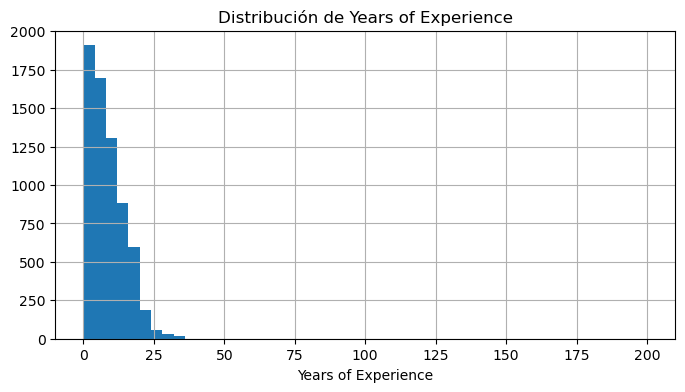

In [106]:
### Distribución de Years of Experience
plt.figure(figsize=(8, 4))
df['Years of Experience'].hist(bins=50)
plt.title('Distribución de Years of Experience')
plt.xlabel('Years of Experience')
plt.show()

### Observación: Distribución de Years of Experience
Distribución con sesgo pronunciado a la derecha. La masa principal de datos 
se concentra entre 0 y 25 años de experiencia, con una cola muy larga hacia 
valores imposibles que superan los 50 años llegando hasta 200.

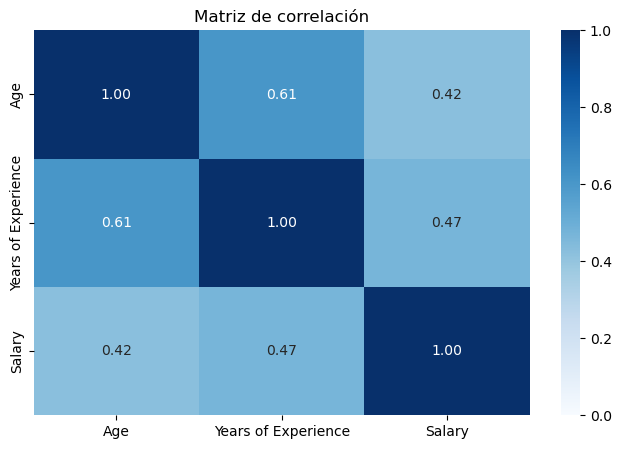

In [107]:
### Correlación entre variables numéricas

plt.figure(figsize=(8, 5))
sns.heatmap(df[['Age', 'Years of Experience', 'Salary']].corr(), 
            annot=True, cmap='Blues', fmt='.2f',
            vmin=0, vmax=1)
plt.title('Matriz de correlación')
plt.show()

### Observación: Matriz de correlación
Las tres variables numéricas muestran correlaciones positivas entre sí. 
La relación más fuerte es entre `Age` y `Years of Experience` (0.61), lo cual 
es lógicamente esperado pero además nos advierte de un posible problema de 
multicolinealidad entre ambas variables que deberemos tener en cuenta en la 
fase de modelado. `Years of Experience` tiene mayor correlación con 
`Salary` (0.47) que `Age` (0.42), sugiriendo que la experiencia es un mejor 
predictor del salario que la edad.

### Pregunta 1 ###
De este primer vistazo general, ¿qué conclusiones sacamos acerca de las variables ***Salary*** y ***Years of Experience***? ¿Qué características tiene la variable ***Job Title***?

***Respuesta:***

**Salary** presenta una distribución con mucho sesgo a la derecha con valores 
que van desde 0 hasta 2,159,320, muy por encima de la media (116,433). 
Se detectan outliers extremos que deberán 
ser tratados. La correlación con `Years of Experience` (0.47) sugiere que 
la experiencia es el predictor numérico más relevante del salario.

**Years of Experience** también presenta sesgo a la derecha con valores que creo son
imposibles que superan los 50 años llegando hasta 200, y 162 registros con 
valor 0. Existe además una inconsistencia en 81 registros donde los 
años de experiencia superan a la edad del empleado.

**Job Title** es una variable categórica con muchos posibles valores. Con 129 valores 
únicos y distribución muy desigual, `Software Engineer` gana con 804 registros 
mientras que muchas categorías tienen apenas 1 registro. Creo que estas características 
hace muy dificil su uso directo y requerirá en todo caso una estrategia para poder usar la variable.

Pasamos ahora a profundizar aún más en las variables a través de las relaciones entre ellas. El alumno debe analizar correlaciones y las relaciones entre categóricas o categoricas y númericas.

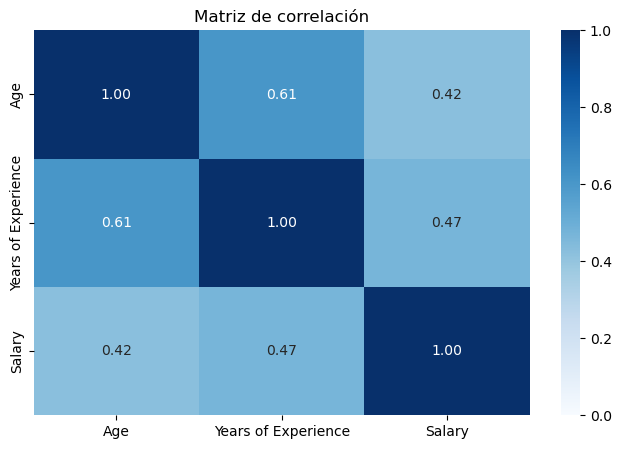

In [108]:
# Volvemos a calcular la matriz de correlación para mantener orden con las preguntas.

plt.figure(figsize=(8, 5))
sns.heatmap(df[['Age', 'Years of Experience', 'Salary']].corr(), 
            annot=True, cmap='Blues', fmt='.2f',
            vmin=0, vmax=1)
plt.title('Matriz de correlación')
plt.show()

### Observación: Matriz de correlación
Como ya dijimos, las tres variables numéricas muestran correlaciones positivas entre sí. 
La relación más fuerte es entre `Age` y `Years of Experience` (0.61), lo cual 
es lógicamente esperado pero además nos advierte de un posible problema de 
multicolinealidad entre ambas variables que deberemos tener en cuenta en la 
fase de modelado. `Years of Experience` tiene mayor correlación con 
`Salary` (0.47) que `Age` (0.42), sugiriendo que la experiencia es un mejor 
predictor del salario que la edad.

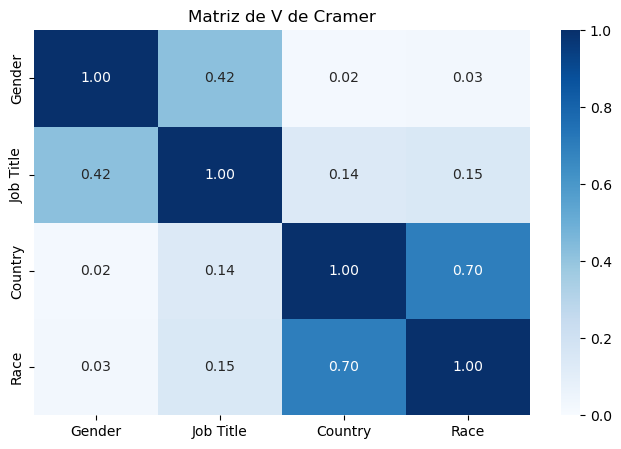

In [109]:
# Calcular la matriz de coeficientes V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(r-1, k-1))

categoricas = ['Gender', 'Job Title', 'Country', 'Race']
cramers_matrix = pd.DataFrame(index=categoricas, columns=categoricas)

for col1, col2 in itertools.combinations(categoricas, 2):
    v = cramers_v(df[col1].dropna(), df[col2].dropna())
    cramers_matrix.loc[col1, col2] = round(v, 2)
    cramers_matrix.loc[col2, col1] = round(v, 2)

for col in categoricas:
    cramers_matrix.loc[col, col] = 1.0

plt.figure(figsize=(8, 5))
sns.heatmap(cramers_matrix.astype(float), annot=True, cmap='Blues', fmt='.2f',
            vmin=0, vmax=1)
plt.title('Matriz de V de Cramer')
plt.show()

### Observación: V de Cramér entre categóricas
La relación más fuerte es entre `Country` y `Race` (0.70), lo cual es 
lógicamente esperado. La segunda relación más relevante es entre `Gender` y 
`Job Title` (0.42), sugiriendo que ciertos puestos de trabajo tienen una 
distribución de género no uniforme. El resto de relaciones son débiles.

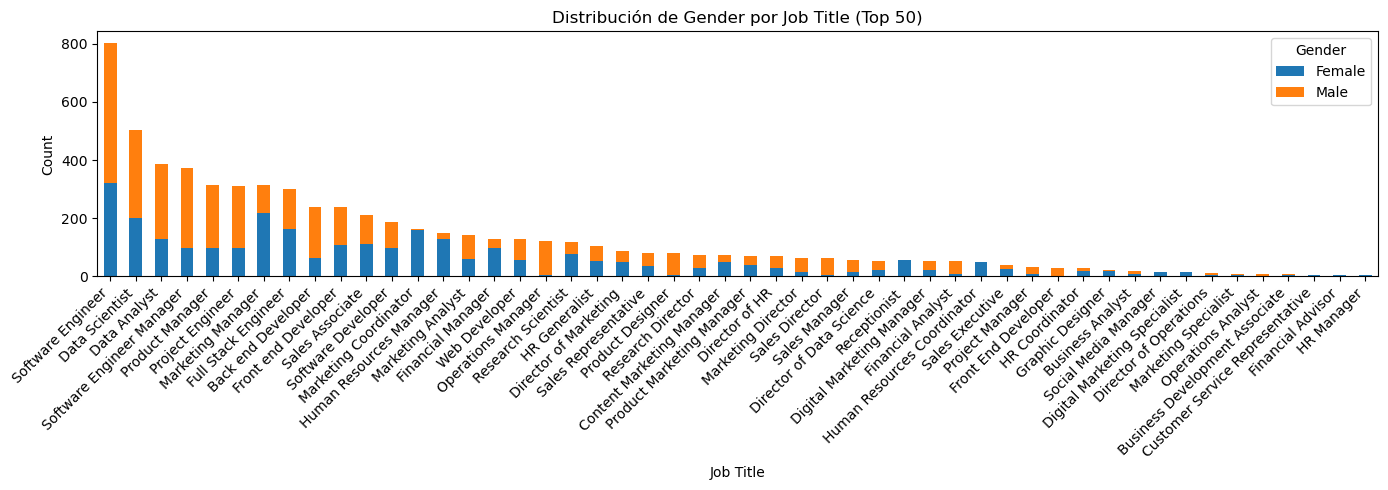

In [110]:
top20_jobs = df['Job Title'].value_counts().head(50).index

df_top20 = df[df['Job Title'].isin(top20_jobs)]

gender_job = df_top20.groupby(['Job Title', 'Gender']).size().unstack(fill_value=0)
gender_job = gender_job.loc[top20_jobs]

gender_job.plot(kind='bar', stacked=True, figsize=(14, 5))
plt.title('Distribución de Gender por Job Title (Top 50)')
plt.xlabel('Job Title')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

### Observación: Distribución de Gender por Job Title
El gráfico confirma la asociación moderada entre `Gender` y `Job Title` detectada en la V de Cramér (0.42). Se observan patrones claros. Roles 
como `Software Engineer Manager` y `Back End Developer` muestran mucha presencia de hombres, mientras que roles como `Marketing Coordinator`, `Marketing Manager` y `Human Resources Manager` muestran mayor presencia femenina. 

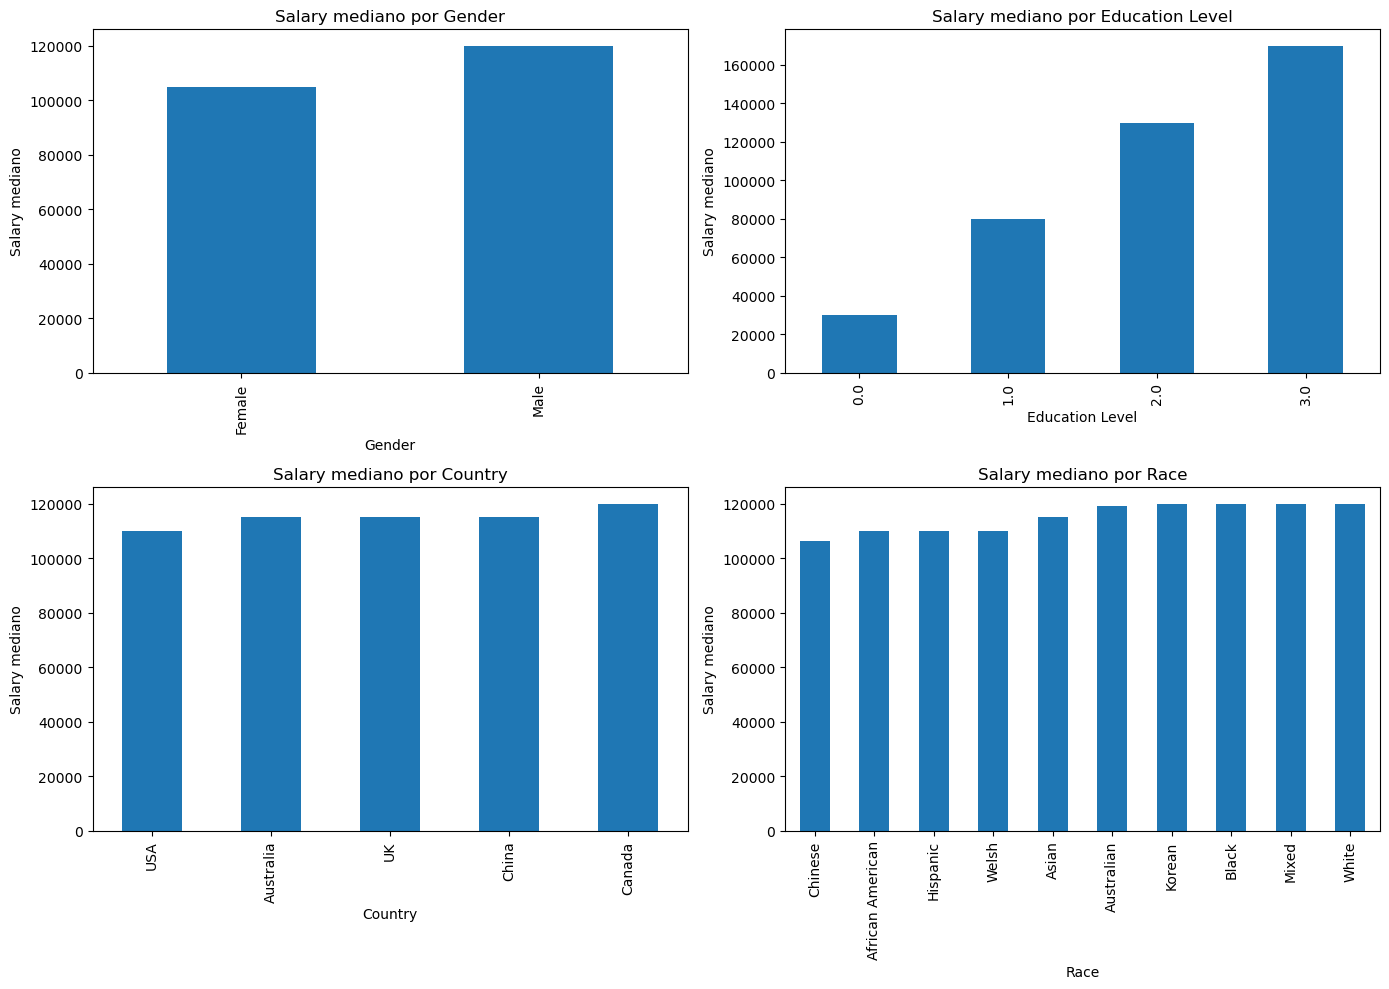

In [111]:
### Relación entre Salary y variables categóricas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), ['Gender', 'Education Level', 'Country', 'Race']):
    df.groupby(col)['Salary'].median().sort_values().plot(kind='bar', ax=ax)
    ax.set_title(f'Salary mediano por {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Salary mediano')

plt.tight_layout()
plt.show()

### Observación: Salary mediano por variable categórica
`Education Level` muestra la relación más clara con `Salary`: a mayor nivel 
educativo mayor salario mediano, lo que la convierte en una variable predictora muy 
relevante. Además el nivel 0 tiene un salario mediano de ~30,000, lo que sugiere 
que podría representar "sin estudios" y no un error de datos. `Gender` muestra 
una brecha salarial visible (~15,000 de diferencia). `Country` y `Race` muestran 
diferencias mínimas entre categorías, sugiriendo poca relevancia predictiva 
sobre `Salary`.

# Nota sobre la variable Salary
Se asume que todos los valores de `Salary` están expresados en la misma 
unidad monetaria y periodicidad (presumiblemente USD anual). Las posibles 
inconsistencias por tipo de cambio, inflación o diferencias de periodicidad 
las dejo fuera del alcance de este análisis. Pero creo que en un analisis más serio/exhaustivo, 
sería apropiado analizar esto con cuidado.

<Figure size 600x500 with 0 Axes>

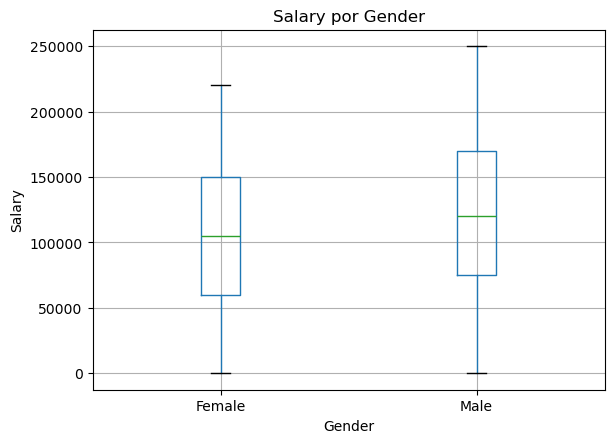

In [112]:
df_viz = df[(df['Salary'] < 400000) & (df['Age'] >= 10) & (df['Age'] < 70) & (df['Years of Experience'] < 50)]

plt.figure(figsize=(6, 5))
df_viz.boxplot(column='Salary', by='Gender')
plt.title('Salary por Gender')
plt.suptitle('')
plt.xlabel('Gender')
plt.ylabel('Salary')
plt.show()

### Observación: Salary por Gender
El boxplot confirma la brecha salarial entre géneros. Los hombres presentan una mediana salarial superior 
frente a las mujeres y un rango más elevado, sugiriendo que los salarios más altos
están más concentrados en el género masculino. Ambos géneros muestran dispersión similar en el rango inferior.

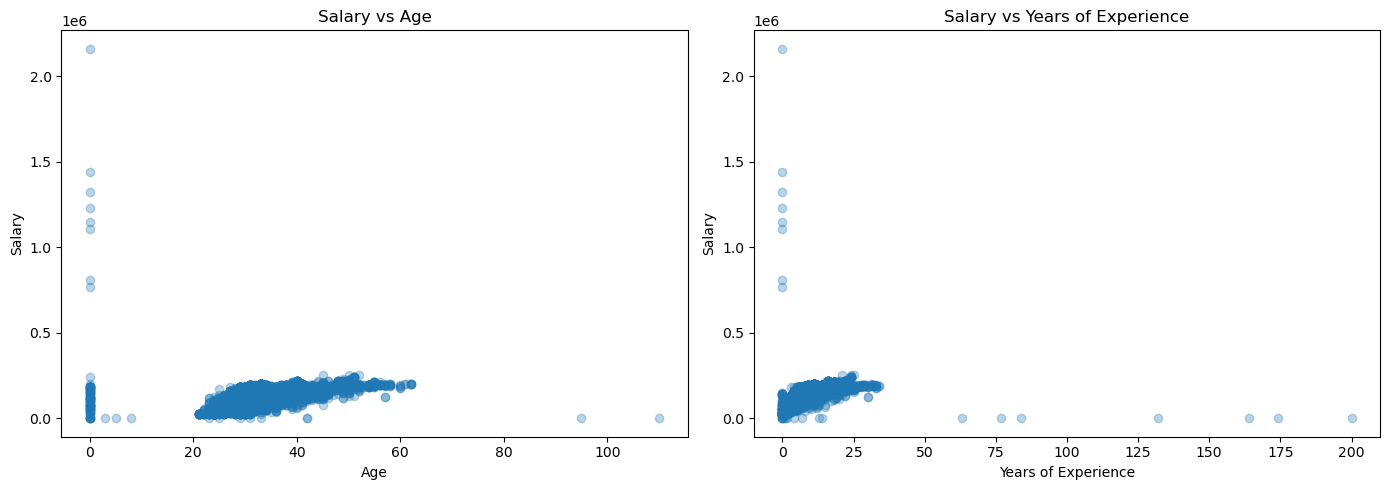

In [113]:
# Relación entre Salary y variables numéricas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['Age'], df['Salary'], alpha=0.3)
axes[0].set_title('Salary vs Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Salary')

axes[1].scatter(df['Years of Experience'], df['Salary'], alpha=0.3)
axes[1].set_title('Salary vs Years of Experience')
axes[1].set_xlabel('Years of Experience')
axes[1].set_ylabel('Salary')

plt.tight_layout()
plt.show()

### Relación entre Salary y variables numéricas
Para visualizar mejor la relación entre `Salary` y las variables numéricas, 
filtramos temporalmente los outliers extremos sin modificar el dataset original. 
Esto nos permite apreciar la tendencia real entre las variables sin que los 
valores anómalos distorsionen la escala de los gráficos.

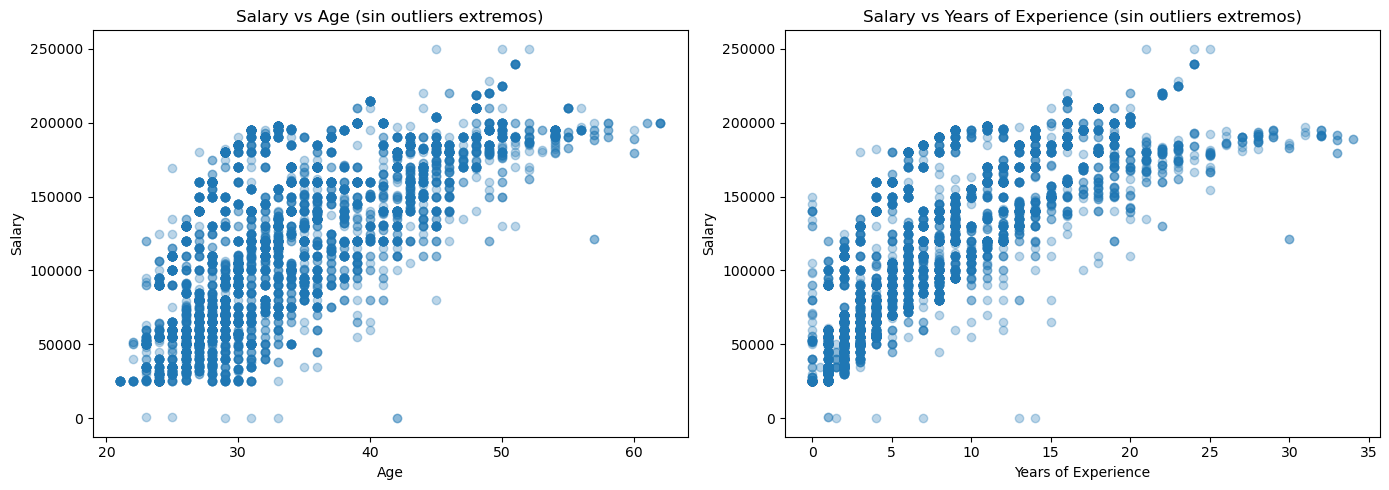

In [114]:
df_viz = df[(df['Salary'] < 400000) & (df['Age'] >= 10) & (df['Age'] < 70) & (df['Years of Experience'] < 50)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df_viz['Age'], df_viz['Salary'], alpha=0.3)
axes[0].set_title('Salary vs Age (sin outliers extremos)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Salary')

axes[1].scatter(df_viz['Years of Experience'], df_viz['Salary'], alpha=0.3)
axes[1].set_title('Salary vs Years of Experience (sin outliers extremos)')
axes[1].set_xlabel('Years of Experience')
axes[1].set_ylabel('Salary')

plt.tight_layout()
plt.show()

### Observación: Salary vs Age y Salary vs Years of Experience
Al filtrar los outliers extremos se aprecia claramente una tendencia positiva 
en ambos casos. A mayor edad y mayor experiencia, mayor salario. La relación 
con `Years of Experience` parece ligeramente más lineal y definida que con 
`Age`, lo cual es consistente con las correlaciones obtenidas (0.47 vs 0.42). 
Se observan también algunos registros con `Salary` cercano a 0 que confirman, 
otra vez, la presencia de valores anómalos que deberán tratarse.

### Pregunta 2 ###
¿Cualés son las relaciones más destacadas entre variables? Describe estas relaciones e interpretalas brevemente.

***Respuesta:***

**Entre variables numéricas:** La correlación más destacada es entre `Age` y 
`Years of Experience` (0.61), relación lógicamente esperada aunque advierte 
de posible multicolinealidad en los modelos. `Years of Experience` muestra 
mayor correlación con `Salary` (0.47) que `Age` (0.42), confirmando que la 
experiencia es un predictor más relevante del salario que la edad. Los scatter plots
confirman una tendencia positiva clara entre ambas variables y `Salary`.

**Entre variables categóricas:** La relación más fuerte es entre `Country` y 
`Race` (V de Cramér = 0.70), esperada dado que ciertas razas están 
concentradas en ciertos países. `Gender` y `Job Title` 
muestran una asociación menor pero creo que relevante (0.42), confirmada con el stacked bar chart, 
mostrando que ciertos puestos tienen una distribución de género no uniforme.

**Entre categóricas y Salary:** `Education Level` es la variable categórica 
con mayor impacto en `Salary`, mostrando una relación progresiva clara: a 
mayor nivel educativo mayor salario mediano. `Gender` muestra una diferencia 
salarial visible de aproximadamente 15,000 a favor de los hombres. 
`Country` y `Race` muestran diferencias mínimas entre categorías, 
sugiriendo poca relevancia predictiva para `Salary`.

Nos centramos ahora en la calidad del dato. Arrancamos con el analisis de valores nulos donde el alumno debe programar código para determinar las variables que tienen valores nulos, el número de registros de cada variable con valores nulos, etc.

In [115]:
# Tabla de porcentaje de registros con Missing Values por cada variable
nulos = pd.DataFrame({
    'Nulos': df.isna().sum(),
    'Porcentaje': (df.isna().sum() / len(df) * 100).round(2)
})
nulos = nulos[nulos['Nulos'] > 0].sort_values('Porcentaje', ascending=False)
print(nulos)

                 Nulos  Porcentaje
Race               163        2.44
Gender              71        1.06
Job Title           40        0.60
Country             24        0.36
Education Level     23        0.34


### Observación: Porcentaje de valores nulos por variable
Ninguna variable supera el 2.5% de nulos, lo que indica una buena calidad 
de los datos. `Race` es la variable con más nulos (2.44%) seguida de `Gender` (1.06%). 
Las variables numéricas `Age`, `Years of Experience` y `Salary` no presentan nulos.(Aunque recordemos que tienen muchos datos con ceros y valores muy altos que podrían ser tratados como errores)

In [116]:
# Cuenta de valores nulos por registro
df.isna().sum(axis=1).value_counts().sort_index()

0    6461
1     161
2      32
3      24
4       6
Name: count, dtype: int64

### Observación: Nulos por registro
La gran mayoría de registros (6,461) no tienen ningún nulo. Solo 223 registros 
tienen al menos un nulo, y de estos, la mayoría tiene únicamente 1. Los registros 
con 3 o 4 nulos simultáneos son muy pocos (30 en total).

In [117]:
print("Salary estadísticas - Gender CON valor:")
print(df[df['Gender'].notna()]['Salary'].describe())
print("\nSalary estadísticas - Gender NULO:")
print(df[df['Gender'].isna()]['Salary'].describe())# ...

Salary estadísticas - Gender CON valor:
count    6.613000e+03
mean     1.161230e+05
std      6.740759e+04
min      0.000000e+00
25%      7.000000e+04
50%      1.150000e+05
75%      1.600000e+05
max      2.159320e+06
Name: Salary, dtype: float64

Salary estadísticas - Gender NULO:
count        71.000000
mean     145387.788732
std       58848.736351
min       25000.000000
25%       82500.000000
50%      180000.000000
75%      196500.000000
max      215000.000000
Name: Salary, dtype: float64


### Observación: Relación entre nulos de Gender y Salary
Los registros con `Gender` nulo presentan una media salarial notablemente 
superior (145,387) frente a los registros con `Gender` informado (116,123). 
La diferencia es aún más marcada en la mediana: 180,000 vs 115,000. Esto 
sugiere que los nulos de `Gender` no son completamente aleatorios (creo que se llaman MCAR) 
sino que podrían estar asociados a perfiles de mayor salario, lo que 
deberiamos tambien tener en cuenta a la hora de imputar estos valores.

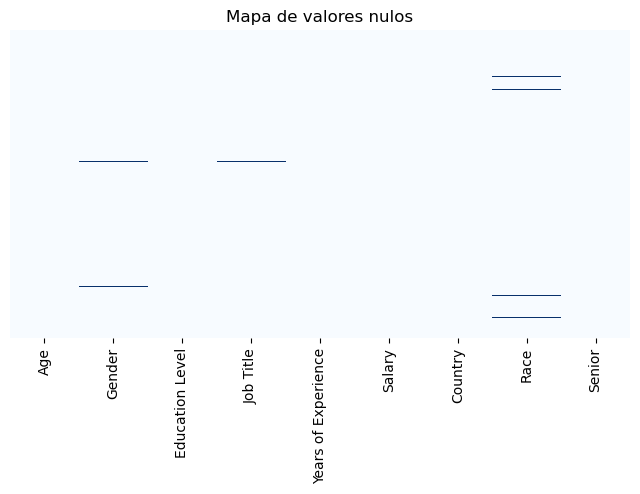

In [118]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='Blues')
plt.title('Mapa de valores nulos')
plt.show()

### Observación: Mapa de valores nulos
El mapa confirma visualmente la distribución de nulos por variable. `Race` 
es la que presenta mayor concentración de nulos seguida de `Gender`. 
En general no se observan patrones claros de coincidencia entre variables, 
lo que sugiere que los nulos son relativamente independientes entre sí. 
Sin embargo llama la atención que la mayor coincidencia aparente se da entre 
`Gender` y `Job Title`, lo cual es relevante ya que `Job Title` parecía 
ser una buena variable candidata para imputar `Gender`. Sin embargo, dado que el porcentaje 
de nulos es muy bajo en todas las variables, las líneas son muy delgadas y 
la visualización resulta poco legible, siendo más útil el análisis numérico previo.

### Pregunta 3 ###
¿Éxiste algún tipo de relación entre los valores nulos de la variable ***Gender*** y ***Salary***? Los nulos de ***Gender***, para esta práctica, hay que llevar a cabo algún tipo de imputación para no perder esos registros. ¿Cómo se realizará está imputación y cuales son las razones que llevan a hacerlo así?

***Respuesta:***

<Figure size 600x500 with 0 Axes>

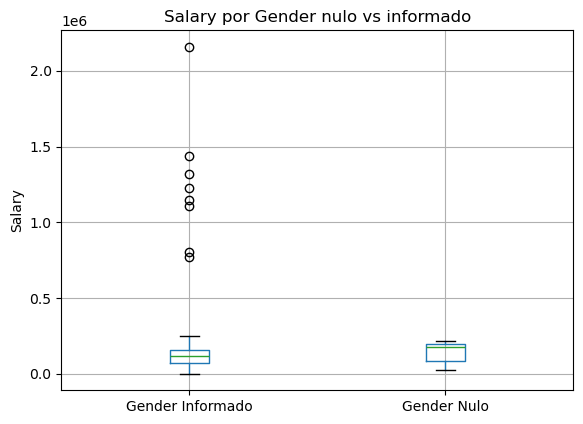

In [119]:
### Relación entre nulos de Gender y Salary
df_gender_null = df.copy()
df_gender_null['Gender_nulo'] = df['Gender'].isna().map({True: 'Gender Nulo', False: 'Gender Informado'})

plt.figure(figsize=(6, 5))
df_gender_null.boxplot(column='Salary', by='Gender_nulo')
plt.title('Salary por Gender nulo vs informado')
plt.suptitle('')
plt.xlabel('')
plt.ylabel('Salary')
plt.show()

<Figure size 600x500 with 0 Axes>

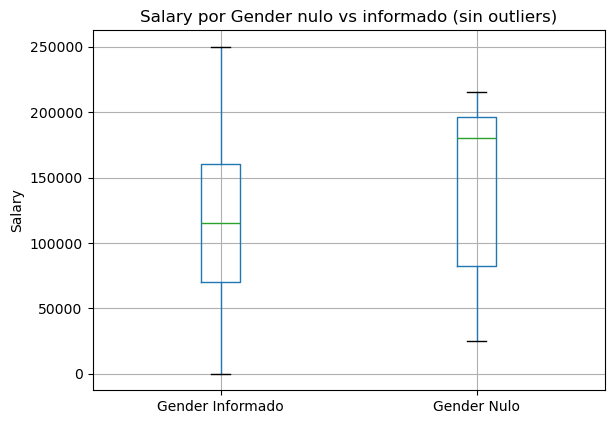

In [120]:
df_gender_null = df.copy()
df_gender_null['Gender_nulo'] = df['Gender'].isna().map({True: 'Gender Nulo', False: 'Gender Informado'})

Q1 = df_gender_null['Salary'].quantile(0.25)
Q3 = df_gender_null['Salary'].quantile(0.75)
IQR = Q3 - Q1

df_gender_null_clean = df_gender_null[df_gender_null['Salary'] <= Q3 + 1.5 * IQR]

plt.figure(figsize=(6, 5))
df_gender_null_clean.boxplot(column='Salary', by='Gender_nulo')
plt.title('Salary por Gender nulo vs informado (sin outliers)')
plt.suptitle('')
plt.xlabel('')
plt.ylabel('Salary')
plt.show()

### Observación: Salary por Gender nulo vs informado
Los boxplots muestran que hay una relación entre los nulos de `Gender` y `Salary`. 
Al eliminar los outliers extremos podemos ver claramente que los registros 
con `Gender` nulo tienen una mediana salarial (~180,000) notablemente superior 
a los registros con `Gender` informado (~115,000). Esto confirma que los 
nulos de `Gender` no son aleatorios sino que se concentran en perfiles 
de mayor salario.

In [121]:

salary_con_gender = df[df['Gender'].notna()]['Salary']
salary_sin_gender = df[df['Gender'].isna()]['Salary']

stat, p_value = ttest_ind(salary_con_gender, salary_sin_gender)
print(f"T-statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: -3.6432
P-value: 0.0003


### Observación: T-test Salary por Gender nulo vs informado
El t-test confirma estadísticamente que existe una diferencia significativa 
en el Salary entre registros con `Gender` nulo e informado 
(T-statistic: -3.64, p-value: 0.0003). Con un p-valor muy por debajo de 
0.05 rechazamos la hipótesis nula de igualdad de medias, confirmando que 
los nulos de `Gender` no son aleatorios sino que se asocian a perfiles 
de mayor salario.

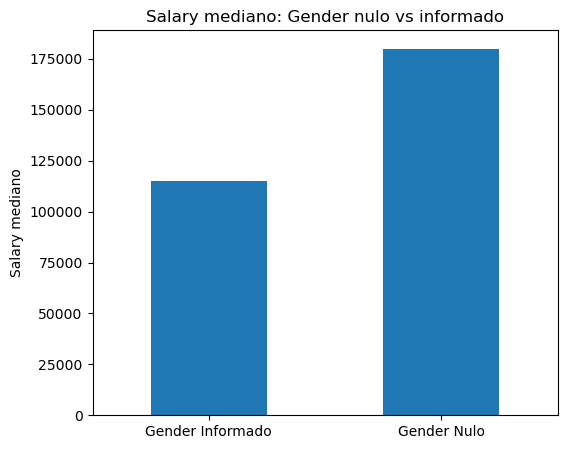

In [122]:
df_gender_null = df.copy()
df_gender_null['Gender_nulo'] = df['Gender'].isna().map({True: 'Gender Nulo', False: 'Gender Informado'})

plt.figure(figsize=(6, 5))
df_gender_null.groupby('Gender_nulo')['Salary'].median().plot(kind='bar')
plt.title('Salary mediano: Gender nulo vs informado')
plt.xlabel('')
plt.ylabel('Salary mediano')
plt.xticks(rotation=0)
plt.show()

### Observación: Salary mediano por Gender nulo vs informado
El gráfico confirma visualmente la diferencia salarial entre ambos grupos. 
Los registros con `Gender` nulo tienen un salario mediano de ~180,000 
frente a ~115,000 de los registros con `Gender` informado, una diferencia 
de aproximadamente 65,000. Junto con el t-test y los boxplots, podemos sostener
 que los nulos de `Gender` están asociados a 
perfiles de mayor salario.

#   RESPUESTA 3


**¿Existe relación entre los nulos de Gender y Salary?**

Creo que con los analisis hechos podemos decir que sí hay relación entre dichas variables. 
Como ya vimos, los registros con `Gender` nulo presentan una mediana salarial de ~180,000 frente a ~115,000 
de los registros con `Gender` informado, una diferencia de aproximadamente 65,000.

El t-test confirma que esta diferencia no es producto del azar (T-statistic: -3.64, p-value: 0.0003),
lo que nos indicaría que los nulos de `Gender` no son completamente aleatorios (MCAR) sino que se concentran 
en perfiles de mayor salario (MAR).

**¿Cómo se realizará la imputación?**

Inicialmente se consideró imputar `Gender` usando `Job Title` dado que 
la V de Cramér entre ambas variables (0.42) indicaba una asociación moderada, 
y el gráfico de distribución de género por Job Title confirmó que ciertos 
puestos tienen una distribución de género claramente no uniforme.

Sin embargo, al verificar la coincidencia de nulos entre `Gender` y 
`Job Title`, encontramos que no todos los registros con `Gender` nulo 
tienen `Job Title` informado. Para mantener una estrategia consistente 
y evitar aplicar métodos distintos según la disponibilidad de `Job Title`, 
se opta por imputar todos los nulos de `Gender` usando imputación aleatoria 
proporcional por rango de `Salary`. Esta decisión está respaldada por el 
análisis previo que demostró que los nulos de `Gender` no son aleatorios 
sino que se asocian a perfiles de mayor salario (p-value: 0.0003), por lo 
que se considera que usar el rango salarial como referencia para la imputación es la 
estrategia más coherente con los datos.

In [123]:
# Verificación de viabilidad de imputación de Gender por Job Title. 
# Antes de imputar, verificamos cuántos registros tienen nulos simultáneos en `Gender` y `Job Title`, ya que en esos casos la estrategia de imputación por Job Title no sería aplicable.
nulos_ambos = df[df['Gender'].isna() & df['Job Title'].isna()]
print(f"Registros con nulo en Gender Y Job Title: {len(nulos_ambos)}")
print(f"Registros con nulo solo en Gender: {df['Gender'].isna().sum() - len(nulos_ambos)}")

Registros con nulo en Gender Y Job Title: 24
Registros con nulo solo en Gender: 47


### Observación: Viabilidad de imputación por Job Title
De los 71 registros con `Gender` nulo, 24 tienen también `Job Title` nulo, 
por lo que la estrategia de imputación por `Job Title` solo seria posible para esos 47 registros. 
Para los 24 restantes se necesitaría otra estrategia alternativa dado que no disponemos de `Job Title`. 

Ahora, como ya vimos que los nulos de `Gender` se asocian tambien a perfiles de mayor salario, optaremos mejor por imputar usando rangos de `Salary`.

In [124]:
bins = [0, 70000, 115000, 160000, float('inf')]
labels = ['Q1', 'Q2', 'Q3', 'Q4']

df['Salary_rango'] = pd.cut(df['Salary'], bins=bins, labels=labels)

print(df[df['Gender'].notna()].groupby('Salary_rango', observed=True)['Gender'].value_counts(normalize=True).unstack().round(2))

Gender        Female  Male
Salary_rango              
Q1              0.54  0.46
Q2              0.46  0.54
Q3              0.45  0.55
Q4              0.34  0.66


### Observación: Proporciones de Gender por rango de Salary
Se confirma la tendencia ya detectada: a mayor salario mayor proporción 
de Male. En Q1 (<70,000) hay ligera mayoría Female (54%) mientras que 
en Q4 (>160,000) la proporción Male asciende al 66%. Usaremos estas 
proporciones para imputar aleatoriamente el Gender de los 24 registros 
que no tienen Job Title informado.

Se considera que una imputación aleatoria usando la proporción 
global de Gender (54% Male / 46% Female) no sería apropiada en este caso, ya que  
como demostramos estadísticamente, los nulos de `Gender` no son aleatorios 
(MAR) sino que se concentran en perfiles de mayor salario, donde la 
proporción de Male es notablemente superior (66% en Q4). Usar la proporción 
global alteraría artificialmente la distribución real de la muestra.

Antes de pasar a ejecutar las acciones que hayamos decidido realizar para corregir los problemas de valores nulos, analizamos los valores atípicos de las variables. Utilizaremos 2 métodos para identificarlos: Z-Score y rango intercuartil (IQR)

In [125]:
# Identificación de outliers (Z-score)
numericas = ['Age', 'Years of Experience', 'Salary']

z_scores = df[numericas].apply(zscore, nan_policy='omit')
outliers_zscore = (z_scores.abs() > 3)

print("Outliers detectados por Z-Score:")
print(outliers_zscore.sum())

Outliers detectados por Z-Score:
Age                    110
Years of Experience     28
Salary                   8
dtype: int64


### Observación: Outliers por Z-Score
El método Z-Score (umbral |z| > 3) detecta 110 outliers en `Age`, 28 en 
`Years of Experience` y 8 en `Salary`. 

In [126]:
outliers_iqr = pd.DataFrame()

for col in numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers_iqr[col] = ~df[col].between(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Outliers detectados por IQR:")
print(outliers_iqr.sum())# Identificación de outliers (IQR)

Outliers detectados por IQR:
Age                    217
Years of Experience     76
Salary                   8
dtype: int64


### Observación: Outliers por IQR
El método IQR detecta notablemente más outliers que Z-Score en `Age` (217 vs 110) 
y `Years of Experience` (76 vs 28). Sin embargo ambos métodos coinciden 
en `Salary` con solo 8 outliers.

### Pregunta 4 ###
¿Qué variables tienen outliers? en ocasiones, dependiendo de los outliers de una variable, es más apropiado identificarlos mediante un método u otro. En tu opinión y en base al estudio de los outliers de cada variable numérica, ¿cuál es el más apropiado para cada una y por qué?

***Respuesta:***

Las tres variables numéricas (`Age`, `Years of Experience` y `Salary`) 
presentan outliers. 

Respecto al método más apropiado para cada una:

**Age → IQR**
Como vimos en el EDA, `Age` presenta una distribución con sesgo a la derecha y valores raros
en ambos extremos (0, 3, 5 y 95, 110). Creo que el IQR es más apropiado en este caso porque utiliza la mediana y los cuartiles, 
que se ven menos afectadas por los valores extremos. El Z-Score, en cambio, basa su cálculo en la media y la desviación estándar, 
y en distribuciones asimétricas como estas pueden afectarse por los propios outliers que queremos quitar.

**Years of Experience → IQR**
Similar a `Age`, como vimos, tiene una distribución fuertemente sesgada 
con valores imposibles como 174 y 200 años. El IQR es más apropiado por las 
mismas razones, robustez frente a asimetría y no dependencia de la media.

**Salary → ninguno es suficiente por sí solo**
Ambos métodos coinciden en detectar solo 8 outliers.

In [127]:
print(df[df['Salary'] > 300000])

      Age  Gender  Education Level            Job Title  Years of Experience  \
311     0    Male              1.0     Business Analyst                  0.0   
2170    0    Male              2.0   Back end Developer                  0.0   
2488    0  Female              1.0  Front end Developer                  0.0   
2498    0  Female              0.0     Project Engineer                  0.0   
2887    0    Male              2.0  Full Stack Engineer                  0.0   
5840    0  Female              1.0    Marketing Analyst                  0.0   
6034    0    Male              1.0    Software Engineer                  0.0   
6399    0  Female              0.0      Sales Executive                  0.0   

       Salary    Country        Race  Senior Salary_rango  
311   1437376         UK       White       0           Q4  
2170  1229795     Canada       White       0           Q4  
2488  1105681         UK       Mixed       0           Q4  
2498  1147100         UK       Asian   

### Observación: Registros con Age=0, Years of Experience=0 y Salary extremo
Los 8 registros detectados como outliers de `Salary` presentan un patrón 
muy claro. todos tienen `Age` = 0 y `Years of Experience` = 0 simultáneamente 
junto con salarios que van desde 768,434 hasta 2,159,320. La combinación 
de estas tres variables con valores inusuales, en los mismos registros, nos da mayor razon para creer 
que deberían ser eliminados del dataset. Sin embargo quedan 86 registros adicionales 
con `Age` = 0 pero sin las demás anomalías, que merecen un análisis 
independiente antes de decidir su tratamiento.

In [128]:
age_cero = df[(df['Age'] == 0) & (df['Salary'] <= 300000)]
print(f"Registros con Age=0 y Salary normal: {len(age_cero)}")
print()
print(age_cero[['Age', 'Gender', 'Job Title', 'Years of Experience', 'Salary']].to_string())

Registros con Age=0 y Salary normal: 86

      Age  Gender                  Job Title  Years of Experience  Salary
31      0  Female                 Accountant                  4.0   55000
243     0  Female          Marketing Analyst                  6.0   70000
377     0    Male             Data Scientist                  5.0  180000
422     0  Female               Data Analyst                132.0       0
469     0    Male                        NaN                  2.0  115000
784     0  Female               Data Analyst                  2.0  110000
941     0  Female             Data Scientist                  7.0  185000
972     0    Male                        NaN                  5.0  150000
983     0    Male          Software Engineer                  8.0  180000
1111    0     NaN                        NaN                  6.0  120000
1253    0  Female         Back end Developer                  3.0   85000
1336    0  Female  Software Engineer Manager                 14.0  1850

In [129]:
df['Age_cero'] = (df['Age'] == 0).map({True: 'Age=0', False: 'Age normal'})

print("Salary:")
print(df.groupby('Age_cero')['Salary'].describe().round(0))
print()
print("Gender:")
print(df.groupby('Age_cero')['Gender'].value_counts(normalize=True).round(2))
print()
print("Race:")
print(df.groupby('Age_cero')['Race'].value_counts(normalize=True).round(2))

Salary:
             count      mean       std  min      25%       50%       75%  \
Age_cero                                                                   
Age normal  6590.0  115199.0   52954.0  0.0  70000.0  115000.0  160000.0   
Age=0         94.0  202972.0  346346.0  0.0  66250.0  115000.0  169790.0   

                  max  
Age_cero               
Age normal   250000.0  
Age=0       2159320.0  

Gender:
Age_cero    Gender
Age normal  Male      0.55
            Female    0.45
Age=0       Male      0.60
            Female    0.40
Name: proportion, dtype: float64

Race:
Age_cero    Race            
Age normal  White               0.29
            Asian               0.24
            Korean              0.07
            Australian          0.07
            Chinese             0.07
            Black               0.07
            African American    0.05
            Welsh               0.05
            Mixed               0.05
            Hispanic            0.05
Age=0       Whit

### Observación: Relación entre Age=0 y otras variables
Al comparar los registros con `Age`=0 contra el resto no se observan 
diferencias significativas en `Gender` ni en `Race`. En `Salary` la 
mediana es prácticamente idéntica (115,000 vs 115,000) aunque la media 
difiere considerablemente (202,972 vs 115,199), diferencia que seguramente está 
siendo arrastrada por los 8 registros con Salary extremo. Esto sugiere que los 86 registros restantes
con Age=0 no siguen un patrón sistemático claro y podrían tratarse como errores de introducción de datos, y podriamos eliminarlos. 

<Figure size 800x500 with 0 Axes>

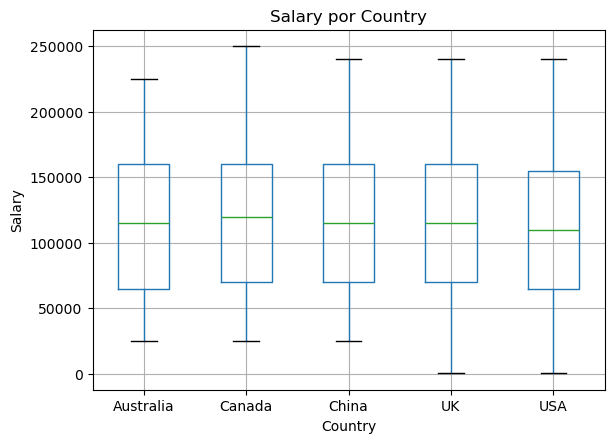

In [130]:
plt.figure(figsize=(8, 5))
df_viz.boxplot(column='Salary', by='Country')
plt.title('Salary por Country')
plt.suptitle('')
plt.xlabel('Country')
plt.ylabel('Salary')
plt.show()

<Figure size 1000x500 with 0 Axes>

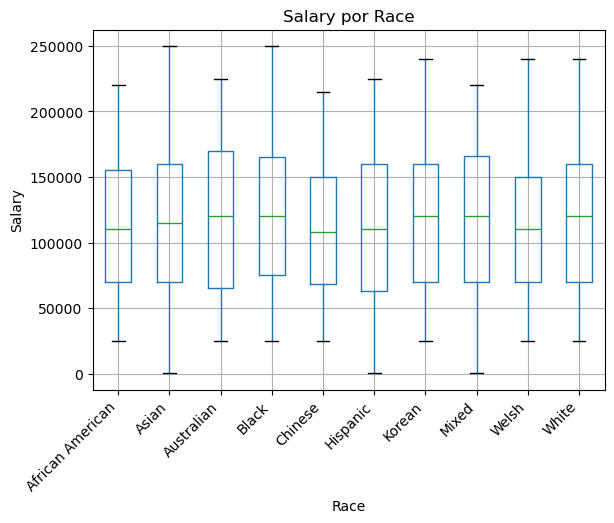

In [131]:
plt.figure(figsize=(10, 5))
df_viz.boxplot(column='Salary', by='Race')
plt.title('Salary por Race')
plt.suptitle('')
plt.xlabel('Race')
plt.ylabel('Salary')
plt.xticks(rotation=45, ha='right')
plt.show()

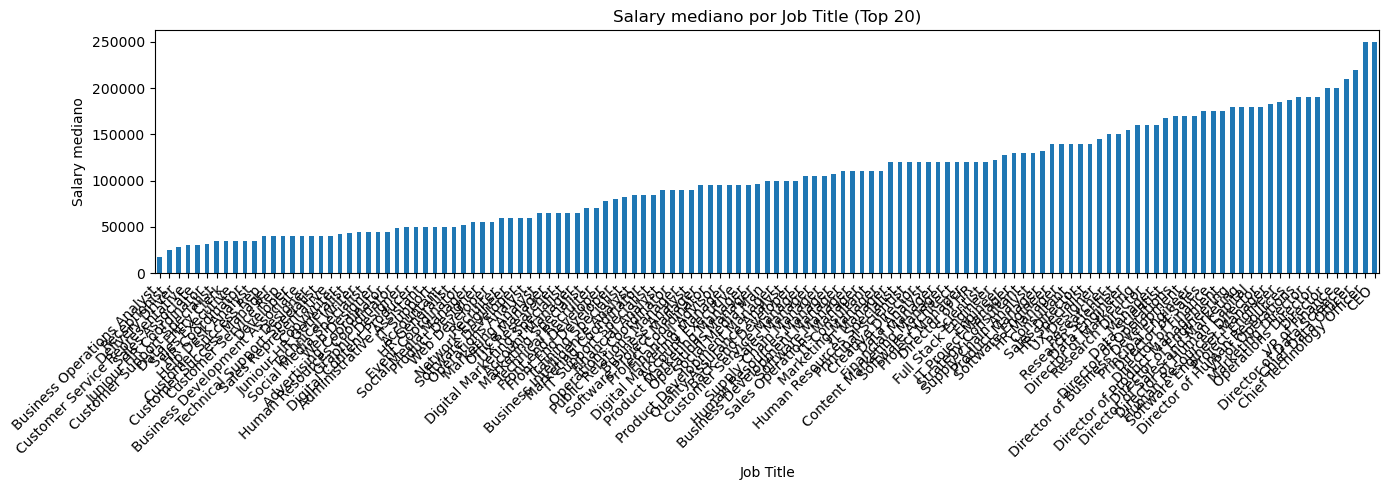

In [132]:
top20_jobs = df['Job Title'].value_counts().head(129).index
df[df['Job Title'].isin(top20_jobs)].groupby('Job Title')['Salary'].median().sort_values().plot(kind='bar', figsize=(14, 5))
plt.title('Salary mediano por Job Title (Top 20)')
plt.xlabel('Job Title')
plt.ylabel('Salary mediano')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Observación: Salary por Country, Race y Job Title
`Country` y `Race` muestran distribuciones de Salary prácticamente idénticas 
entre todas sus categorías, confirmando lo que ya anticipaban los barplots 
de salary mediano, y es que son variables que probablemente no nos sirvan para predecir `Salary`. 

`Job Title` en cambio muestra diferencias muy marcadas en el salary mediano 
entre categorías, convirtiéndola en una variable potencialmente muy relevante 
para predecir `Salary`. Para analizar mejor estos patrones dividimos los 
129 Job Titles en tres grupos según su salary mediano.

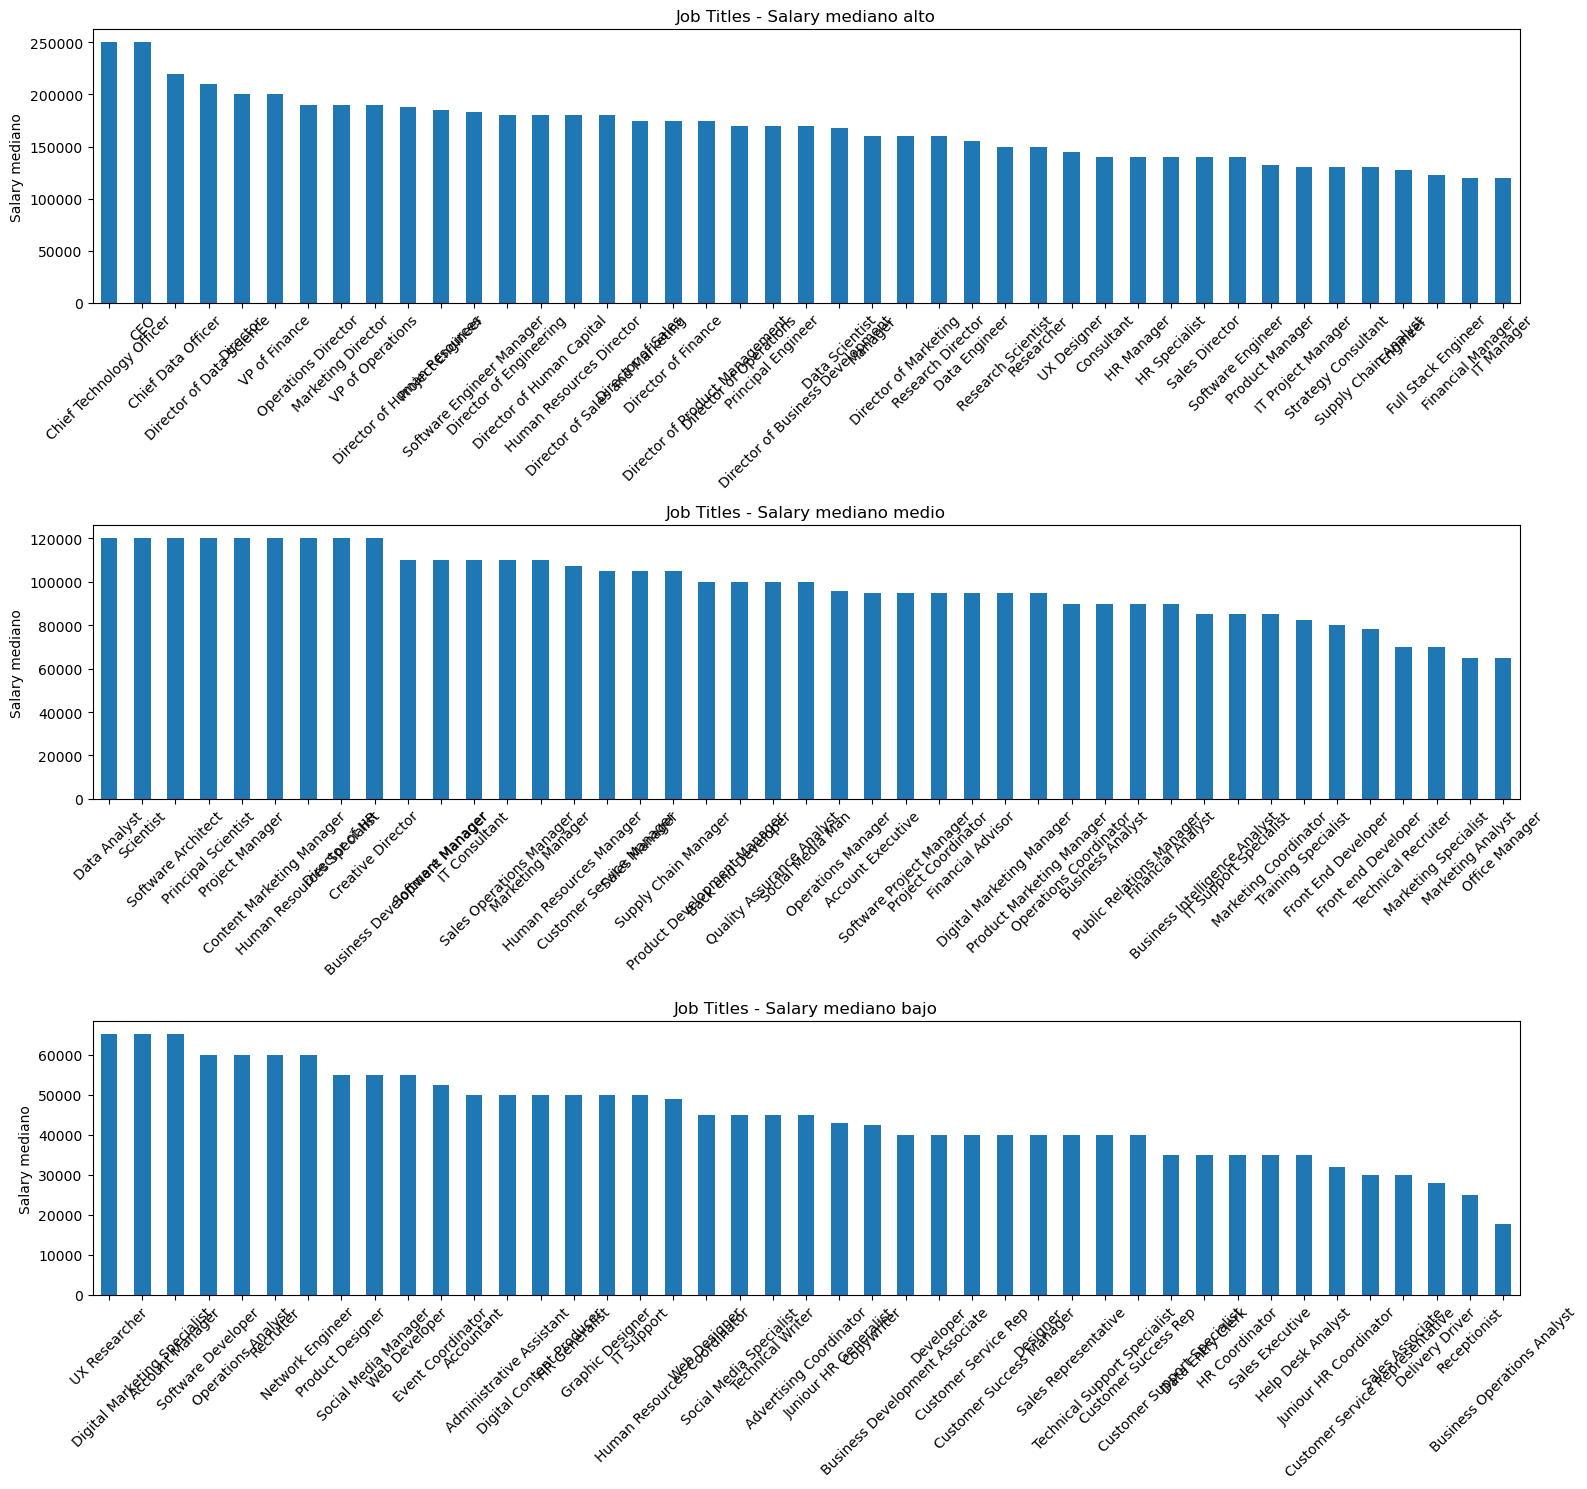

In [133]:
salary_por_job = df.groupby('Job Title')['Salary'].median().sort_values(ascending=False)

top = salary_por_job.iloc[:43]
mid = salary_por_job.iloc[43:86]
bot = salary_por_job.iloc[86:]

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

top.plot(kind='bar', ax=axes[0], title='Job Titles - Salary mediano alto')
mid.plot(kind='bar', ax=axes[1], title='Job Titles - Salary mediano medio')
bot.plot(kind='bar', ax=axes[2], title='Job Titles - Salary mediano bajo')

for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('Salary mediano')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

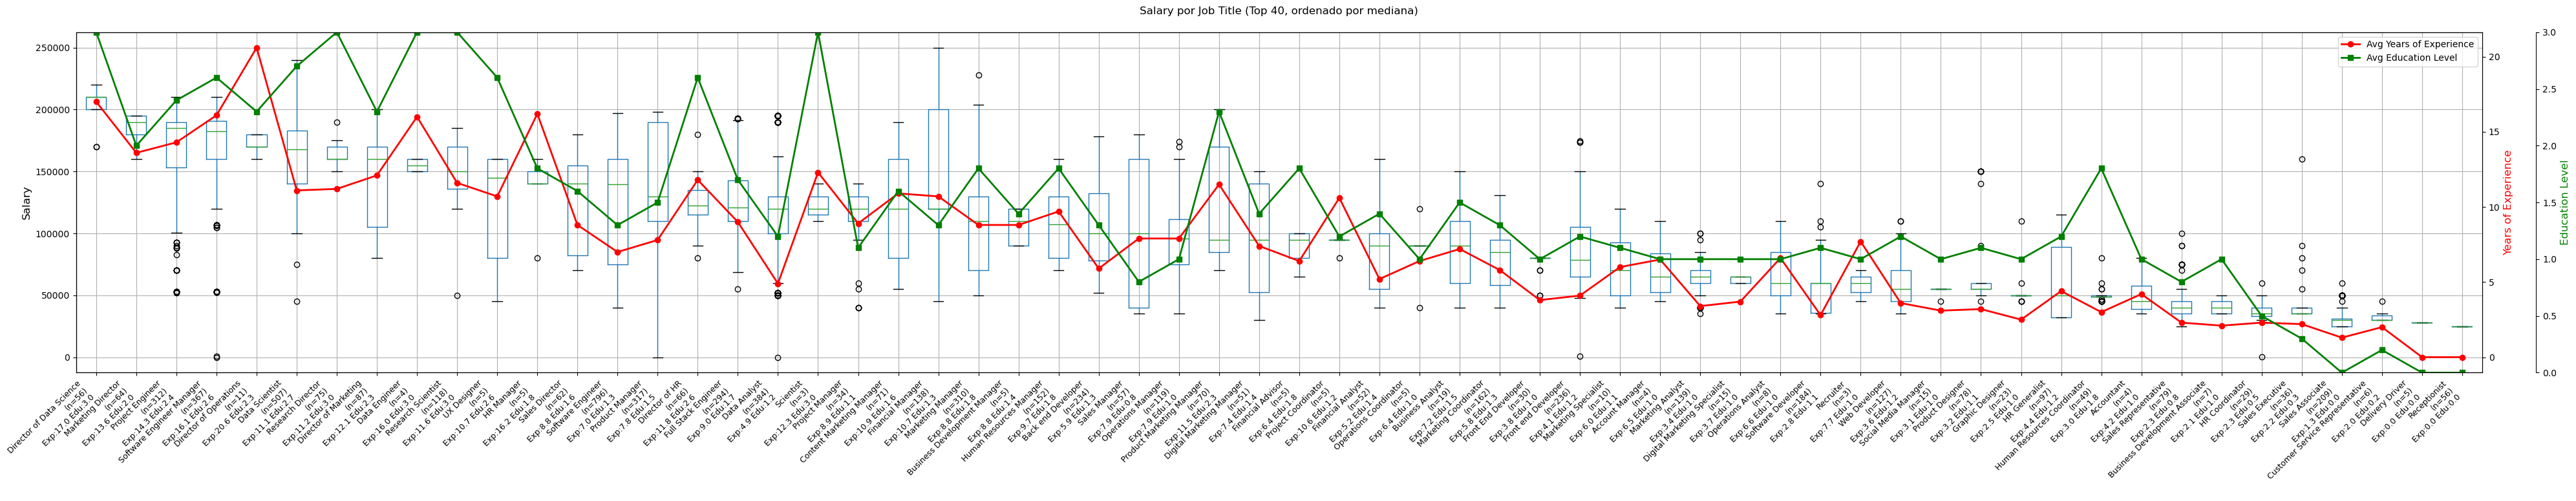

In [134]:
top40_jobs = df_viz['Job Title'].value_counts().head(60).index

subset = df_viz[df_viz['Job Title'].isin(top40_jobs)].copy()
counts = subset.groupby('Job Title')['Salary'].count()
medianas = subset.groupby('Job Title')['Salary'].median().sort_values(ascending=False)
mean_exp = subset.groupby('Job Title')['Years of Experience'].mean().round(1)
mean_edu = subset.groupby('Job Title')['Education Level'].mean().round(1)

orden = medianas.index.tolist()
subset['Job Title'] = pd.Categorical(subset['Job Title'], categories=orden, ordered=True)
subset = subset.sort_values('Job Title')

fig, ax1 = plt.subplots(figsize=(40, 8))

# Boxplot en eje izquierdo
subset_labeled = subset.copy()
subset_labeled['Job Title'] = subset_labeled['Job Title'].apply(
    lambda x: f"{x}\n(n={counts[x]})\nExp:{mean_exp[x]} Edu:{mean_edu[x]}"
)
subset_labeled.boxplot(column='Salary', by='Job Title', ax=ax1)
ax1.set_ylabel('Salary', fontsize=12)
ax1.set_xlabel('')
ax1.tick_params(axis='x', rotation=45)

# Eje derecho para experiencia
ax2 = ax1.twinx()
x_pos = range(1, len(orden) + 1)
ax2.plot(x_pos, [mean_exp[j] for j in orden], 
         color='red', marker='o', linewidth=2, label='Avg Years of Experience')
ax2.set_ylabel('Years of Experience', fontsize=12, color='red')

# Tercer eje para educación (escala 1-3)
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))
ax3.plot(x_pos, [mean_edu[j] for j in orden], 
         color='green', marker='s', linewidth=2, label='Avg Education Level')
ax3.set_ylabel('Education Level', fontsize=12, color='green')
ax3.set_ylim(0, 3)

# Leyendas
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax1.set_title('Salary por Job Title (Top 40, ordenado por mediana)', 
              pad=20, backgroundcolor='white')
plt.suptitle('')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.subplots_adjust(bottom=0.3)
plt.tight_layout()
plt.show()

### Conclusión sobre Job Title
El análisis del boxplot de los Top 40 Job Titles ordenados por salary mediano 
revela un patrón muy claro: los títulos con mayor salario mediano tienen 
consistentemente mayor media de `Years of Experience` y `Education Level`, 
mientras que los títulos con menor salario tienen valores más bajos en ambas 
variables. Esto sugiere que mucha de la información relevante que contiene `Job Title` 
sobre el salario puede ya estar siendo capturada por `Years of Experience` y 
`Education Level`.

Dado que:
- La variable tiene una cardinalidad muy alta (129 categorías) que hace 
inviable su uso directo en los modelos
- Su información relevante parece estar recogida en otras variables del dataset
- Introducirla requeriría técnicas complejas que añaden complejidad sin 
garantía de mejora

Se decide **no incluir `Job Title` como variable predictora** en los modelos. 
Esta decisión será validada empíricamente, si los modelos funcionan bien 
sin ella, quedará justificada. En caso contrario, se valorará incorporar 
`Job Area`  haciendo algun ajuste o reclasificando.

Ahora procedemos a trabajar los datos seleccionando registros, variables y solventando los problemas de outliers y valores nulos para dejar preparado el conjunto de datos para la fase de modelado posterior. En este sentido, las siguientes líneas de código, deben programarse para realizar estas transformaciones.

## 5. Preparación de datos

### Contador de registros eliminados
Llevamos un registro del número de filas eliminadas durante la limpieza 
para asegurarnos de no superar el umbral del 5% de la muestra original.

In [135]:
# Seleccion/Eliminación de registros y variables

In [136]:
filas_originales = len(df)
print(f"Filas originales: {filas_originales}")
print(f"5% de la muestra: {filas_originales * 0.05:.0f} filas")

Filas originales: 6684
5% de la muestra: 334 filas


In [137]:
registros_corruptos = df[(df['Age'] == 0) & (df['Years of Experience'] == 0) & (df['Salary'] > 300000)]
print(f"Registros corruptos identificados: {len(registros_corruptos)}")
registros_corruptos

Registros corruptos identificados: 8


,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Country,Race,Senior,Salary_rango,Age_cero
311,0,Male,1.0,Business Analyst,0.0,1437376,UK,White,0,Q4,Age=0
2170,0,Male,2.0,Back end Developer,0.0,1229795,Canada,White,0,Q4,Age=0
2488,0,Female,1.0,Front end Developer,0.0,1105681,UK,Mixed,0,Q4,Age=0
2498,0,Female,0.0,Project Engineer,0.0,1147100,UK,Asian,1,Q4,Age=0
2887,0,Male,2.0,Full Stack Engineer,0.0,768434,Canada,Asian,0,Q4,Age=0
5840,0,Female,1.0,Marketing Analyst,0.0,805612,USA,White,0,Q4,Age=0
6034,0,Male,1.0,Software Engineer,0.0,1320000,Canada,White,0,Q4,Age=0
6399,0,Female,0.0,Sales Executive,0.0,2159320,Australia,Australian,0,Q4,Age=0


In [138]:
df = df.drop(registros_corruptos.index)
filas_eliminadas = filas_originales - len(df)
print(f"Registros eliminados: {filas_eliminadas}")
print(f"Registros restantes: {len(df)}")
print(f"Porcentaje eliminado: {filas_eliminadas/filas_originales*100:.2f}%")

Registros eliminados: 8
Registros restantes: 6676
Porcentaje eliminado: 0.12%


### Revisión de registros con Age=0 (excluidos los corruptos)

In [139]:
age_cero = df[df['Age'] == 0]
print(f"Registros con Age=0 restantes: {len(age_cero)}")
print()

print("Salary:")
print(df.groupby('Age_cero')['Salary'].describe().round(0))
print()
print("Gender:")
print(df.groupby('Age_cero')['Gender'].value_counts(normalize=True).round(2))
print()
print("Race:")
print(df.groupby('Age_cero')['Race'].value_counts(normalize=True).round(2))

Registros con Age=0 restantes: 86

Salary:
             count      mean      std  min      25%       50%       75%  \
Age_cero                                                                  
Age normal  6590.0  115199.0  52954.0  0.0  70000.0  115000.0  160000.0   
Age=0         86.0  105884.0  59693.0  0.0  56250.0  107500.0  160000.0   

                 max  
Age_cero              
Age normal  250000.0  
Age=0       240000.0  

Gender:
Age_cero    Gender
Age normal  Male      0.55
            Female    0.45
Age=0       Male      0.61
            Female    0.39
Name: proportion, dtype: float64

Race:
Age_cero    Race            
Age normal  White               0.29
            Asian               0.24
            Korean              0.07
            Australian          0.07
            Chinese             0.07
            Black               0.07
            African American    0.05
            Welsh               0.05
            Mixed               0.05
            Hispanic      

In [140]:

salary_age_normal = df[df['Age'] != 0]['Salary']
salary_age_cero = df[df['Age'] == 0]['Salary']

stat, p_value = ttest_ind(salary_age_normal, salary_age_cero)
print(f"T-statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: 1.6180
P-value: 0.1057


In [141]:
df = df[df['Age'] != 0]
filas_eliminadas = filas_originales - len(df)
print(f"Registros eliminados acumulado: {filas_eliminadas}")
print(f"Registros restantes: {len(df)}")
print(f"Porcentaje eliminado acumulado: {filas_eliminadas/filas_originales*100:.2f}%")

Registros eliminados acumulado: 94
Registros restantes: 6590
Porcentaje eliminado acumulado: 1.41%


### Observación: Análisis de registros con Age=0 (excluidos los 8 corruptos)
Al eliminar los 8 registros, el análisis de los 86 registros 
restantes con Age=0 muestra que sus distribuciones de Salary, Gender y Race 
son muy similares al resto del dataset. El t-test confirma que no existe 
diferencia estadísticamente significativa en el Salary entre ambos grupos 
(T-statistic: 1.62, p-value: 0.1057), confirmando que los registros con 
Age=0 son aleatorios (MCAR) y pueden eliminarse sin introducir sesgo.

In [142]:
print(df['Years of Experience'].value_counts().sort_index(ascending=False).head(20))

Years of Experience
34.0      2
33.0      6
32.0     10
31.0      3
30.0      6
29.0      8
28.0     16
27.0     11
26.0      7
25.0     20
24.0     18
23.0     37
22.0     47
21.0     42
20.0     61
19.0    121
18.0    125
17.0    106
16.0    238
15.0    124
Name: count, dtype: int64


In [143]:
print(df[df['Years of Experience'] > 34]['Years of Experience'].value_counts().sort_index())

Series([], Name: count, dtype: int64)


In [144]:
print(f"Máximo de Years of Experience tras limpieza: {df['Years of Experience'].max()}")
print(f"Valores únicos por encima de 34:")
print(df[df['Years of Experience'] > 34]['Years of Experience'].value_counts().sort_index())

Máximo de Years of Experience tras limpieza: 34.0
Valores únicos por encima de 34:
Series([], Name: count, dtype: int64)


### Observación: Outliers de Years of Experience
Tras la eliminación de los registros con Age=0, los valores imposibles de 
`Years of Experience` (63, 77, 84, 132, 164, 174, 200) desaparecieron 
automáticamente ya que todos coincidían con registros de Age=0. 
El máximo actual es 34 años, valor perfectamente razonable y coherente 
con las edades del dataset.

In [145]:
outliers_iqr = pd.DataFrame()

for col in ['Age', 'Years of Experience', 'Salary']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers_iqr[col] = ~df[col].between(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Outliers detectados por IQR tras limpieza:")
print(outliers_iqr.sum())

Outliers detectados por IQR tras limpieza:
Age                    123
Years of Experience     69
Salary                   0
dtype: int64


In [146]:
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

Q1_exp = df['Years of Experience'].quantile(0.25)
Q3_exp = df['Years of Experience'].quantile(0.75)
IQR_exp = Q3_exp - Q1_exp

print("Outliers de Age:")
print(df[~df['Age'].between(Q1_age - 1.5*IQR_age, Q3_age + 1.5*IQR_age)]['Age'].value_counts().sort_index())
print()
print("Outliers de Years of Experience:")
print(df[~df['Years of Experience'].between(Q1_exp - 1.5*IQR_exp, Q3_exp + 1.5*IQR_exp)]['Years of Experience'].value_counts().sort_index())

Outliers de Age:
Age
3       1
5       1
8       1
54     63
55     16
56     11
57      9
58      7
60      5
61      2
62      5
95      1
110     1
Name: count, dtype: int64

Outliers de Years of Experience:
Years of Experience
26.0     7
27.0    11
28.0    16
29.0     8
30.0     6
31.0     3
32.0    10
33.0     6
34.0     2
Name: count, dtype: int64


### Tratamiento de outliers de Age y Years of Experience

Revisando los outliers detectados por IQR, los de `Years of Experience` 
(26-34 años) consideramos que todos tienen sentido y son valores perfectamente posibles 
para empleados con larga trayectoria laboral, por lo que decidimos conservarlos.

Para `Age` en cambio, encontramos valores que practicamente son imposibles en ambos 
extremos: 3, 5 y 8 años por abajo, y 95 y 110 por arriba. Estos serán 
eliminados para que el dataset tenga sentido. Por esta misma razon, consideramos que los valores entre 54 y 62 son perfectamente válidos y se conservan.

In [147]:
outliers_age = df[(df['Age'] < 16) | (df['Age'] > 75)]
print(f"Registros a eliminar: {len(outliers_age)}")
print(outliers_age[['Age', 'Years of Experience', 'Salary']])

Registros a eliminar: 5
      Age  Years of Experience  Salary
2402   95                  0.0       0
2948    5                  0.0       0
3033    8                  0.0       0
4451  110                  0.0       0
5777    3                  0.0       0


In [148]:
df = df[~((df['Age'] < 16) | (df['Age'] > 75))]
filas_eliminadas = filas_originales - len(df)
print(f"Registros eliminados acumulado: {filas_eliminadas}")
print(f"Registros restantes: {len(df)}")
print(f"Porcentaje eliminado acumulado: {filas_eliminadas/filas_originales*100:.2f}%")

Registros eliminados acumulado: 99
Registros restantes: 6585
Porcentaje eliminado acumulado: 1.48%


In [149]:
nulos_edu = df[df['Education Level'].isna()]
print(f"Registros con Education Level nulo: {len(nulos_edu)}")
nulos_edu[['Age', 'Gender', 'Job Title', 'Years of Experience', 'Salary', 'Education Level']]

Registros con Education Level nulo: 12


,Age,Gender,Job Title,Years of Experience,Salary,Education Level
2230,34,NaN,Back end Developer,0.0,140000,NaN
2518,29,NaN,Full Stack Engineer,0.0,98568,NaN
3550,32,NaN,Human Resources Manager,0.0,80000,NaN
3573,27,NaN,NaN,1.0,32000,NaN
3939,42,NaN,Data Scientist,0.0,140000,NaN
4175,34,NaN,Human Resources Manager,0.0,99000,NaN
4718,29,NaN,NaN,3.0,55000,NaN
4726,26,NaN,NaN,1.0,45000,NaN
4804,28,NaN,NaN,3.0,52000,NaN
5542,25,NaN,NaN,1.0,55000,NaN


In [150]:
df = df[df['Education Level'].notna()]
filas_eliminadas = filas_originales - len(df)
print(f"Registros eliminados acumulado: {filas_eliminadas}")
print(f"Registros restantes: {len(df)}")
print(f"Porcentaje eliminado acumulado: {filas_eliminadas/filas_originales*100:.2f}%")

Registros eliminados acumulado: 111
Registros restantes: 6573
Porcentaje eliminado acumulado: 1.66%


### Observación: Nulos de Education Level
Son solo 12 registros (0.18% del dataset) y todos coinciden con nulos 
en Gender, lo que ademas creo que los hace poco útiles para el modelado. Se decide 
eliminarlos dado su escaso número y la acumulación de nulos.


<Figure size 600x500 with 0 Axes>

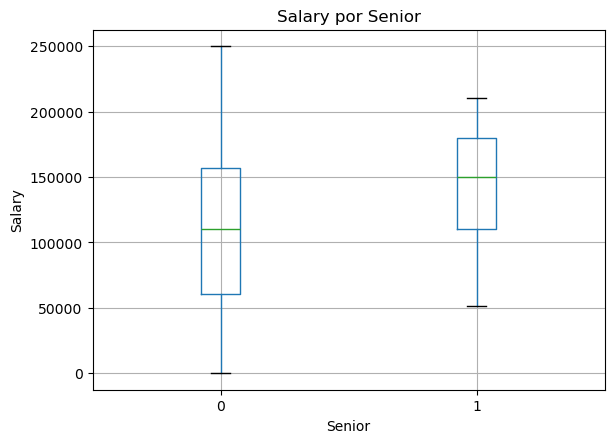

In [151]:
plt.figure(figsize=(6, 5))
df_viz.boxplot(column='Salary', by='Senior')
plt.title('Salary por Senior')
plt.suptitle('')
plt.xlabel('Senior')
plt.ylabel('Salary')
plt.show()

In [152]:
print(df.groupby('Senior')['Years of Experience'].describe().round(1))
print()
print(f"Correlación Senior-Years of Experience: {df['Senior'].corr(df['Years of Experience']):.2f}")
print(f"Correlación Senior-Salary: {df['Senior'].corr(df['Salary']):.2f}")

         count  mean  std  min  25%   50%   75%   max
Senior                                               
0       5626.0   7.3  5.8  0.0  3.0   6.0  11.0  34.0
1        947.0  12.8  5.6  0.0  9.0  12.0  16.0  32.0

Correlación Senior-Years of Experience: 0.32
Correlación Senior-Salary: 0.23


### Observación: Variable Senior
La variable `Senior` muestra una correlación moderada con `Years of Experience` 
(0.32) pero no está completamente capturada por ella, ya que hay Seniors con poca 
experiencia y no-Seniors con mucha. Su correlación con `Salary` (0.23) es 
positiva y puede aportar información adicional, por lo que se decide mantenerla.

In [153]:
# Imputación o acciones para tratar valores nulos
print(df[df['Gender'].isna()][['Salary', 'Salary_rango']].describe())
print()
print(df[df['Gender'].isna()]['Salary'].min())
print(f"Registros con Salary = 0: {(df[df['Gender'].isna()]['Salary'] == 0).sum()}")

              Salary
count      53.000000
mean   166395.566038
std     48922.443966
min     50000.000000
25%    140000.000000
50%    190000.000000
75%    200000.000000
max    215000.000000

50000
Registros con Salary = 0: 0


### Verificación previa a la imputación
Confirmamos que todos los registros con `Gender` nulo tienen `Salary` 
informado y mayor a 0 (mínimo 50,000), lo que garantiza que la 
imputación por rango de `Salary` es aplicable a todos los casos.

In [154]:
np.random.seed(42)

# Guardamos índices antes de imputar
indices_imputados = df[df['Gender'].isna()].index.tolist()

# Proporciones de Gender por rango de Salary
bins = [0, 70000, 115000, 160000, float('inf')]
labels = ['Q1', 'Q2', 'Q3', 'Q4']
df['Salary_rango'] = pd.cut(df['Salary'], bins=bins, labels=labels)
proporciones_salary = df[df['Gender'].notna()].groupby('Salary_rango', observed=True)['Gender'].value_counts(normalize=True).unstack().fillna(0)

# Imputar
for idx in indices_imputados:
    rango = df.loc[idx, 'Salary_rango']
    prop_male = proporciones_salary.loc[rango, 'Male'] if rango in proporciones_salary.index else 0.55
    df.loc[idx, 'Gender'] = np.random.choice(['Male', 'Female'], p=[prop_male, 1-prop_male])

print(f"Nulos en Gender tras imputación: {df['Gender'].isna().sum()}")
print()
print("Distribución final de Gender:")
print(df['Gender'].value_counts())

Nulos en Gender tras imputación: 0

Distribución final de Gender:
Gender
Male      3628
Female    2945
Name: count, dtype: int64


### Observación: Imputación de Gender completada
Tras la imputación la distribución de `Gender` quedó en 55.2% Male y 
44.8% Female, prácticamente idéntica a la distribución original (55% / 45%), 
confirmando que la imputación no introdujo sesgo significativo en la muestra.

In [155]:
df = df.drop(columns=['Salary_rango', 'Age_cero', 'Country', 'Race', 'Job Title'], errors='ignore')
print(f"Columnas restantes: {df.columns.tolist()}")
print(f"Shape: {df.shape}")
print(f"\nNulos por variable:")
print(df.isna().sum())

Columnas restantes: ['Age', 'Gender', 'Education Level', 'Years of Experience', 'Salary', 'Senior']
Shape: (6573, 6)

Nulos por variable:
Age                    0
Gender                 0
Education Level        0
Years of Experience    0
Salary                 0
Senior                 0
dtype: int64


### Dataset limpio
Tras todas las eliminaciones e imputaciones el dataset queda con 6,573 
registros y 6 variables sin ningún nulo. Se eliminaron en total 111 registros 
(1.66% de la muestra original), muy por debajo del umbral del 5%.

Variables finales:
- `Age` — numérica
- `Gender` — categórica (imputada)
- `Education Level` — ordinal
- `Years of Experience` — numérica
- `Salary` — numérica (variable objetivo regresión lineal)
- `Senior` — binaria

In [156]:
print(f"Registros con Salary = 0: {(df['Salary'] == 0).sum()}")
print(f"Registros con Salary < 10000: {(df['Salary'] < 10000).sum()}")

Registros con Salary = 0: 3
Registros con Salary < 10000: 7


In [157]:
df[df['Salary'] < 10000][['Age', 'Gender', 'Education Level', 'Years of Experience', 'Salary', 'Senior']]

,Age,Gender,Education Level,Years of Experience,Salary,Senior
258,29,Male,1.0,1.5,350,0
951,33,Male,1.0,7.0,0,0
1888,25,Female,1.0,1.0,550,0
1903,42,Male,2.0,13.0,0,0
2640,23,Male,3.0,1.0,579,0
2692,42,Male,2.0,14.0,0,0
4615,31,Female,1.0,4.0,500,0


In [158]:
df = df[df['Salary'] >= 10000]
filas_eliminadas = filas_originales - len(df)
print(f"Registros eliminados acumulado: {filas_eliminadas}")
print(f"Registros restantes: {len(df)}")
print(f"Porcentaje eliminado acumulado: {filas_eliminadas/filas_originales*100:.2f}%")

Registros eliminados acumulado: 118
Registros restantes: 6566
Porcentaje eliminado acumulado: 1.77%


Por último, para `Salary` tambien encontramos 7 registros con valores entre 0 y 579, 
valores que muy probablemente sean erróneos, a lo mejor se confundio la periodicidad del salario en algunos de estos casos y en los de 0 probablemente se deba a otra 
cosa como alguna situacion anomala como alguna baja por alguna razon o algo asi porque no hace sentido tener salario 0. Por estas razones estos también serán eliminados.

### Decisión sobre outliers: eliminación vs transformación
En este caso se optó por eliminar los outliers en lugar de imputarlos 
o transformarlos. La razón es que se considera que los outliers detectados no son valores 
extremos reales sino errores de introducción de datos como edades imposibles, 
años de experiencia que superan la edad, salarios de 0. Además, el número de registros eliminados es muy pequeño (1.77%) 
por lo que el impacto sobre la muestra deberá ser mínimo.

### Pregunta 5 ###
¿cómo han sido tratados los valores átipicos de la variable ***Salary*** y por qué se ha tomado esta decisión?

***Respuesta:***

Los valores atípicos de `Salary` se dividieron en dos grupos con tratamientos distintos:

**Registros con Salary extremo (>300,000):** Los 8 registros con salarios 
entre 768,434 y 2,159,320 fueron eliminados. La decisión se tomó porque 
estos registros presentaban simultáneamente `Age`=0 y `Years of Experience`=0, 
por lo que se considero que  se trataba de errores de datos y no de casos reales extremos. 


**Registros con Salary=0 o cercano a 0:** Los 7 registros con salarios 
inferiores a 10,000 también fueron eliminados, porque tambien los consideramos como errores de introducción de datos.

En ningún caso se aplicó  transformación porque se considero que los outliers 
no eran valores extremos reales sino errores de datos. Crei que en este sentido, la eliminación fue 
la decisión más honesta con los datos, y el impacto fue mínimo — apenas 
el 1.77% de la muestra original eliminada en total entre todos los tratamientos.

A continuación en los siguientes bloques de código, se han de llevar a cabo ciertas transformaciones que conviene realizar sobre los datos para dejarlos depurados y preparados para la fase de modelado. En este sentido, transformaciones de variables númericas para buscar mayor relación con la variable objetivo, recategorización de variables categóricas, estandarización, homogeneización de formatos y unidades, etc.

In [159]:
df

,Age,Gender,Education Level,Years of Experience,Salary,Senior
0,32,Male,1.0,5.0,90000,0
1,28,Female,2.0,3.0,65000,0
2,45,Male,3.0,15.0,150000,1
3,36,Female,1.0,7.0,60000,0
4,52,Male,2.0,20.0,200000,0
...,...,...,...,...,...,...
6679,49,Female,3.0,20.0,200000,0
6680,32,Male,0.0,3.0,50000,0
6681,30,Female,1.0,4.0,55000,0
6682,46,Male,2.0,14.0,140000,0


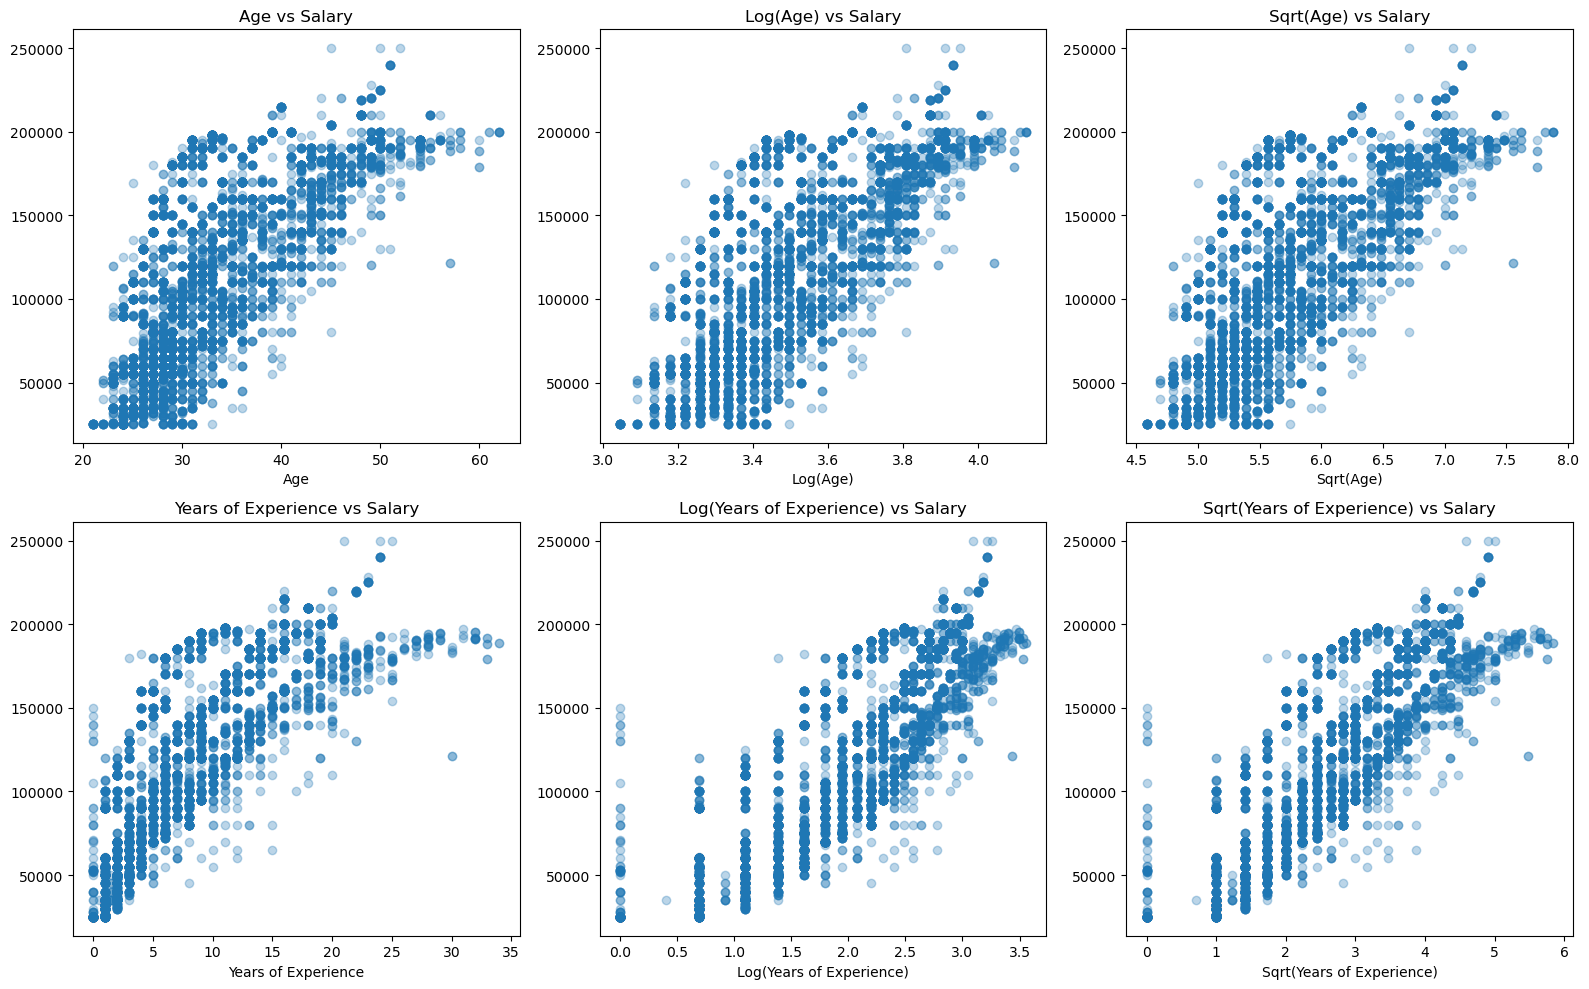

In [160]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Age original vs Salary
axes[0,0].scatter(df['Age'], df['Salary'], alpha=0.3)
axes[0,0].set_title('Age vs Salary')
axes[0,0].set_xlabel('Age')

# Age log vs Salary
axes[0,1].scatter(np.log(df['Age']), df['Salary'], alpha=0.3)
axes[0,1].set_title('Log(Age) vs Salary')
axes[0,1].set_xlabel('Log(Age)')

# Age sqrt vs Salary
axes[0,2].scatter(np.sqrt(df['Age']), df['Salary'], alpha=0.3)
axes[0,2].set_title('Sqrt(Age) vs Salary')
axes[0,2].set_xlabel('Sqrt(Age)')

# Years of Experience original vs Salary
axes[1,0].scatter(df['Years of Experience'], df['Salary'], alpha=0.3)
axes[1,0].set_title('Years of Experience vs Salary')
axes[1,0].set_xlabel('Years of Experience')

# Years of Experience log vs Salary
axes[1,1].scatter(np.log1p(df['Years of Experience']), df['Salary'], alpha=0.3)
axes[1,1].set_title('Log(Years of Experience) vs Salary')
axes[1,1].set_xlabel('Log(Years of Experience)')

# Years of Experience sqrt vs Salary
axes[1,2].scatter(np.sqrt(df['Years of Experience']), df['Salary'], alpha=0.3)
axes[1,2].set_title('Sqrt(Years of Experience) vs Salary')
axes[1,2].set_xlabel('Sqrt(Years of Experience)')

plt.tight_layout()
plt.show()

### Transformaciones de variables numéricas
Se evaluaron transformaciones logarítmica y raíz cuadrada sobre `Age` y 
`Years of Experience` para buscar mayor linealidad con `Salary`. Sin embargo 
las visualizaciones no mostraron mejora significativa respecto a las variables 
originales, cuya relación con `Salary` ya es suficientemente lineal. 
Se decide mantener las variables en su escala original y poder preservar mas facilidad en
la interpretabilidad de los coeficientes del modelo.

In [161]:
# Recategorización...

### Recategorización de variables categóricas

**Education Level:**  La variable presenta valores 0, 1, 2 y 3. Inicialmente 
el valor 0 generaba dudas sobre si era un error o un valor válido. Sin embargo, 
el análisis del salary mediano por nivel educativo mostró una progresión clara 
y coherente, el nivel 0 tiene un salary mediano de ~30,000, por debajo del 
nivel 1, lo que sugiere que representa un "sin estudios" y no un error 
de datos. Además la presencia de nulos distintos de 0 confirma que hay 
distinción entre no informar el nivel educativo y tener nivel 0. 
Al tratarse de una variable ordinal, la codificación numérica 0, 1, 2 y 3 
es perfectamente apropiada ya que preserva el orden natural de los niveles 
educativos y permite que el modelo capture la relación progresiva entre 
educación y salario. Se decide mantenerla tal cual.

**Country, Race y Job Title:** Estas variables fueron eliminadas del dataset 
durante la fase de limpieza. `Country` y `Race` no mostraron ser importantes para
predecir `Salary` ni sobre `Gender`. `Job Title` sí mostraba 
diferencias salariales entre categorías, pero su alta cardinalidad (129 
categorías) hacía inviable su uso directo. En caso de que el modelo no 
funcione correctamente sin ella, `Job Title` sería la primera candidata 
a incorporar mediante una estrategia de recategorización o target encoding.

In [162]:
# Estandarización...

### Estandarización
La estandarización de las variables numéricas se aplicará en cada modelo 
de forma independiente según sus necesidades, tratando de ver si podemos conservar interpretabilidad del modelo. 

In [163]:
# Tipos de valores...

In [164]:
print(df.dtypes)
print()
print(df.head())

Age                      int64
Gender                  object
Education Level        float64
Years of Experience    float64
Salary                   int64
Senior                   int64
dtype: object

   Age  Gender  Education Level  Years of Experience  Salary  Senior
0   32    Male              1.0                  5.0   90000       0
1   28  Female              2.0                  3.0   65000       0
2   45    Male              3.0                 15.0  150000       1
3   36  Female              1.0                  7.0   60000       0
4   52    Male              2.0                 20.0  200000       0


### Tipos de valores y codificación

Corregimos los tipos de datos y codificamos la variable categórica `Gender`.

In [165]:
# Corregir tipos
df['Education Level'] = df['Education Level'].astype(int)
df['Years of Experience'] = df['Years of Experience'].astype(float)
df['Salary'] = df['Salary'].astype(float)

# Codificar Gender
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

print(df.dtypes)
print()
print(df.head())

Age                      int64
Gender                   int64
Education Level          int64
Years of Experience    float64
Salary                 float64
Senior                   int64
dtype: object

   Age  Gender  Education Level  Years of Experience    Salary  Senior
0   32       1                1                  5.0   90000.0       0
1   28       0                2                  3.0   65000.0       0
2   45       1                3                 15.0  150000.0       1
3   36       0                1                  7.0   60000.0       0
4   52       1                2                 20.0  200000.0       0


### Tipos de valores y codificación

Se corrigieron los tipos de datos del dataset:
- `Education Level` se convirtio de float64 a 
int64 al no tener ya nulos que justificaran el tipo float.
- `Gender` fue codificada como variable binaria (Male=1, Female=0), 
necesario para su uso en los modelos.
- `Salary` se convirtió a float64 para evitar posibles problemas numéricos 
durante el modelado, aunque los valores de entrenamiento sean enteros.

El dataset queda completamente limpio, sin nulos y con todos los tipos 
correctos, listo para la fase de modelado.

### Pregunta 6 ###
En caso de que se haya llevado a cabo algún tratamiento sobre las variables categóricas, ¿qué acciones se han tomado y sobre qué variables? En el caso de la variable ***Education Level***, ¿Se ha llevado a cabo sobre ella alguna transformación o se ha dejado tal cual?¿Por qué?

***Respuesta:***

**Tratamiento sobre variables categóricas:**

- **Gender** fue codificada como variable binaria (Male=1, Female=0), 
transformación necesaria para su uso en los modelos.
- **Country** y **Race** fueron eliminadas del dataset al no mostrar 
relevancia predictiva sobre `Salary` ni sobre `Gender`.
- **Job Title** fue eliminada por su alta cardinalidad (129 categorías). 
Su información relevante sobre el salario parece estar recogida por 
`Years of Experience` y `Education Level`.

**Education Level:**
Se dejó tal cual, sin ninguna transformación. Al ser una variable ordinal 
con valores 0, 1, 2 y 3, se considera que la codificación numérica ya existente es 
apropiada y preserva el orden natural de los niveles 
educativos y permite al modelo capturar la relación progresiva entre 
educación y salario. 
El valor 0 se mantiene como válido ya que se condsiera que representa un
"sin estudios" genuino, respaldado por su salary mediano (~30,000) 
coherente con el resto de niveles y por la existencia de nulos distintos 
de 0 que confirman que hay distinción entre ambos casos.

Procedemos ahora con el primer modelo que vamos a definir con este conjunto de datos. Se trata de un modelo de regresión lineal que tratará de predecir los valores de la variable ***Salary*** en función de las demás variables.

Hasta aquí se habrán realizado diversas transformaciones y preparaciones de los datos comunes para todos los ejercicios de esta práctica. En los siguientes bloques, añadir transformaciones específicas para este modelo de regresión lineal.

In [166]:
# Transformaciones varias para adaptar al modelo de regresión lineal

## Regresión Lineal

### Transformaciones específicas para el modelo de regresión lineal
El dataset ya está preparado de forma general en la fase anterior. 
En este sentido, se considera que para la regresión lineal no se requieren, en principio transformaciones adicionales 
en este momento, la variable objetivo `Salary` se mantiene en su  escala original para preservar la interpretabilidad de los coeficientes.

La posible multicolinealidad entre `Age` y `Years of Experience` 
(correlación 0.61) se evaluará formalmente tras 
entrenar el modelo. Si fuera necesario, se eliminaría una de las dos 
variables en una iteración posterior.

De igual forma, si los residuos del modelo muestran no normalidad o 
heterocedasticidad, se valorará aplicar una transformación logarítmica 
sobre `Salary` en una segunda iteración.

Ahora procedemos a realizar la separación del conjunto de datos en 2 conjuntos: uno con las variables predictoras y otro con la variable objetivo. También separamos en conjuntos de entrenamiento y test para poder llevar a cabo el entrenamiento del modelo y la validación en conjuntos distintos. Escoged el porcentaje de datos para entrenamiento que se considere adecuado. Por último, entrenar un modelo de regresión lineal mostrando un resumen de los parametros, coeficientes y demás información útil para valorar la bondad del modelo entrenado.

In [167]:
# Definir la variable objetivo (y) y las predictoras (X)

y = df['Salary']
X = df.drop(columns=['Salary'])


In [168]:
# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tamaño del conjunto de entrenamiento: {X_train.shape}")
print(f"Tamaño del conjunto de prueba: {X_test.shape}")

Tamaño del conjunto de entrenamiento: (5252, 5)
Tamaño del conjunto de prueba: (1314, 5)


In [169]:
# Añadir constante para el intercepto
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

In [170]:
# Crear y ajustar el modelo
modelo = sm.OLS(y_train, X_train_sm).fit()


In [171]:
# Mostrar el resumen detallado del modelo
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     2517.
Date:                Thu, 02 Jul 2026   Prob (F-statistic):               0.00
Time:                        00:32:05   Log-Likelihood:                -61345.
No. Observations:                5252   AIC:                         1.227e+05
Df Residuals:                    5246   BIC:                         1.227e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                8.912e+04   3

### Pregunta 7 ###
A la vista de los resultados del modelo, ¿Presenta sesgo el modelo? ¿Se cumplen las condiciones/supuestos que deben cumplirse en una regresión lineal para que el modelo sea estadisticamente válido? Detalla la respuesta haciendo interpretacion de los resultados obtenidos.

***Respuesta:***

**R² y ajuste general:**
El modelo obtiene un R²=0.706, explicando el 70.6% de la varianza de 
`Salary`. El estadistico F es muy significativo (p≈0), confirmando 
que el modelo en conjunto aporta información relevante. Además todas las variables 
son estadísticamente significativas (p-valor=0.000).

**¿Presenta sesgo el modelo?**
Sí presenta cierto sesgo  debido a la multicolinealidad 
entre `Age` y `Years of Experience` (correlación 0.61). Esto se manifiesta 
en coeficientes contraintuitivos — `Age` tiene coeficiente negativo (-1,992), 
sugiriendo que a mayor edad menor salario, lo cual contradice la lógica. 
Creo que el modelo está "repartiendo", por asi decirlo, el efecto de la experiencia entre ambas 
variables de forma artificial. De igual forma, `Senior` presenta un 
coeficiente negativo (-6,068) que resulta tambien difícil de interpretar, a lo mejor menos horas trabajando o algo diferente 
a lo que pensariamos que es un puesto de mayor jerarquia, o igual senior esta recogiendo ya lo que tenemos en Years of Experience.

**¿Se cumplen los supuestos de la regresión lineal?**

- **Linealidad:** Se cumple razonablemente — los scatters mostraron 
relaciones lineales entre las predictoras y `Salary`.

- **Normalidad de residuos:** No se cumple completamente. El test 
Omnibus (p≈0) y el Jarque-Bera (p≈0) rechazan la hipótesis de normalidad 
de los residuos. El Skew=0.575 y Kurtosis=3.642 confirman cierta 
asimetría y colas más grandes de lo esperado.

- **Ausencia de multicolinealidad:** Parcialmente cumplida. El Condition 
Number=337 es alto y podría explicar el comportamiento de los coeficientes 
contraintuitivos de `Age` y `Senior`. 

- **Homocedasticidad:** Pendiente de verificar con los residuos — 
se analizará en la validación cruzada.

- **Ausencia de autocorrelación:** Se cumple. El Durbin-Watson=2.005 
es muy cercano a 2, indicando ausencia de autocorrelación en los residuos.

- **Efecto de la escala de las variables:** La diferencia de escala 
entre las variables predictoras puede estar afectando la interpretación 
del modelo. `Age` y `Years of Experience` están en rangos de 
decenas, `Education Level` entre 0 y 3, y `Salary` en rangos 
de miles. Esto hace que los coeficientes no sean directamente 
comparables entre sí y un coeficiente alto no implica necesariamente 
mayor impacto sobre `Salary`. En modelos posteriores donde se aplique 
estandarización, como el de regresión logística con LASSO, este problema debería
quedar corregido.

En conclusión, el modelo es estadísticamente válido en términos generales 
pero presenta limitaciones en la normalidad de residuos y posible 
multicolinealidad que podrían afectar la fiabilidad de los coeficientes 
individuales, aunque no necesariamente la capacidad predictiva global.

A continuación, se ha de aplicar validación cruzada sobre los datos para el modelo de regresión lineal. Con esto veremos la generalización del modelo a datos no conocidos. Generar los bloques de código necesarios para llevar a cabo esta validación. La validación ha de ser en base a 2 métricas de vuestra elección sobre conjuntos de test y han de mostrarse los resultados en diagramas de tipo de boxplot o que permitan entender cómo generaliza el modelo.

In [172]:
# Modelo de sklearn para validación cruzada
modelo_cv = LinearRegression()

# R² en cada fold
r2_scores = cross_val_score(modelo_cv, X, y, cv=10, scoring='r2')

# RMSE en cada fold
rmse_scores = np.sqrt(-cross_val_score(modelo_cv, X, y, cv=10, scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores.mean():.3f} (+/- {r2_scores.std():.3f})")
print(f"RMSE medio: {rmse_scores.mean():.0f} (+/- {rmse_scores.std():.0f})")

R² medio: 0.471 (+/- 0.626)
RMSE medio: 29893 (+/- 11204)


In [173]:
print("R² por fold:")
for i, score in enumerate(r2_scores):
    print(f"Fold {i+1}: {score:.3f}")
print()
print("RMSE por fold:")
for i, score in enumerate(rmse_scores):
    print(f"Fold {i+1}: {score:.0f}")

R² por fold:
Fold 1: 0.255
Fold 2: -1.335
Fold 3: 0.600
Fold 4: 0.581
Fold 5: 0.639
Fold 6: 0.663
Fold 7: 0.830
Fold 8: 0.837
Fold 9: 0.878
Fold 10: 0.761

RMSE por fold:
Fold 1: 42700
Fold 2: 57085
Fold 3: 29470
Fold 4: 29275
Fold 5: 28893
Fold 6: 25550
Fold 7: 22821
Fold 8: 18219
Fold 9: 18304
Fold 10: 26615


In [174]:
print("Primeros valores de Salary:")
print(df['Salary'].head(20).values)
print()
print("Últimos valores de Salary:")
print(df['Salary'].tail(20).values)

Primeros valores de Salary:
[ 90000.  65000. 150000.  60000. 200000.  55000. 120000.  80000.  45000.
 110000.  75000. 140000.  65000. 130000.  40000. 125000.  90000. 115000.
  35000. 180000.]

Últimos valores de Salary:
[ 90000. 200000.  40000.  70000. 160000.  35000. 130000.  95000.  35000.
 140000.  40000.  90000.  55000. 190000.  75000. 200000.  50000.  55000.
 140000.  35000.]


In [175]:
kf = KFold(n_splits=10)

for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
    if fold == 1:  # Fold 2 (índice 1)
        print(f"Fold 2 - Registros en test: {len(test_idx)}")
        print(f"\nEstadísticas de Salary en Fold 2 test:")
        print(y.iloc[test_idx].describe())
        print(f"\nEstadísticas de Salary en Fold 2 train:")
        print(y.iloc[train_idx].describe())

Fold 2 - Registros en test: 657

Estadísticas de Salary en Fold 2 test:
count       657.000000
mean     155109.589041
std       37389.188097
min       55000.000000
25%      130000.000000
50%      160000.000000
75%      190000.000000
max      200000.000000
Name: Salary, dtype: float64

Estadísticas de Salary en Fold 2 train:
count      5909.000000
mean     111061.738873
std       52400.685632
min       25000.000000
25%       65000.000000
50%      110000.000000
75%      155000.000000
max      250000.000000
Name: Salary, dtype: float64


In [176]:

kf = KFold(n_splits=10)

for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
    if fold == 1:  # Fold 2
        X_fold2_test = X.iloc[test_idx]
        y_fold2_test = y.iloc[test_idx]
        X_fold2_train = X.iloc[train_idx]
        y_fold2_train = y.iloc[train_idx]
        
        print("=== FOLD 2 TEST ===")
        print(pd.concat([X_fold2_test, y_fold2_test], axis=1).describe().round(1))
        print()
        print("=== RESTO (TRAIN) ===")
        print(pd.concat([X_fold2_train, y_fold2_train], axis=1).describe().round(1))

=== FOLD 2 TEST ===
         Age  Gender  Education Level  Years of Experience  Senior    Salary
count  657.0   657.0            657.0                657.0   657.0     657.0
mean    31.2     0.6              1.6                  6.9     0.1  155109.6
std      7.3     0.5              0.7                  4.2     0.2   37389.2
min     23.0     0.0              1.0                  0.0     0.0   55000.0
25%     27.0     0.0              1.0                  4.0     0.0  130000.0
50%     30.0     1.0              1.0                  6.0     0.0  160000.0
75%     32.0     1.0              2.0                  9.0     0.0  190000.0
max     62.0     1.0              3.0                 20.0     1.0  200000.0

=== RESTO (TRAIN) ===
          Age  Gender  Education Level  Years of Experience  Senior    Salary
count  5909.0  5909.0           5909.0               5909.0  5909.0    5909.0
mean     33.9     0.6              1.6                  8.2     0.2  111061.7
std       7.6     0.5         

### Observación: Problema en Fold 2
El Fold 2 presenta un R²=-1.334 debido a que su distribución de `Salary` 
es muy distinta al resto del dataset (mediana 160,000 vs 110,000). 
Los datos tienen una ordenación implícita que hace que ciertos folds 
tengan distribuciones no representativas. Creo que la solución es usar 
`shuffle=True` para aleatorizar antes de dividir en folds.

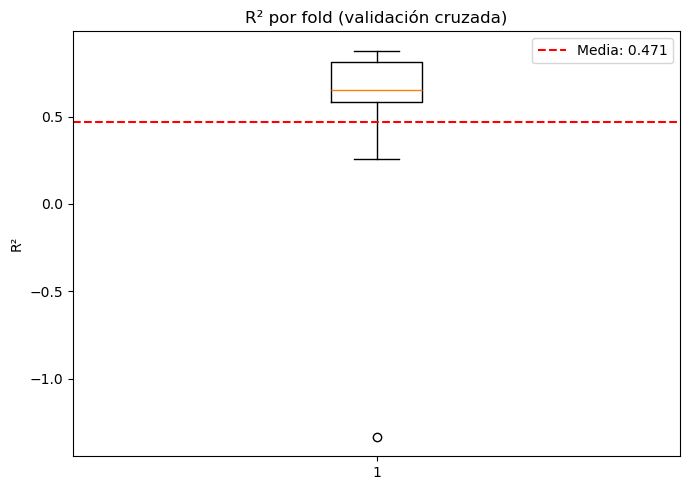

In [177]:
# Apoyo gráfico para interpretar la validación
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(r2_scores)
ax.set_title('R² por fold (validación cruzada)')
ax.set_ylabel('R²')
ax.axhline(y=r2_scores.mean(), color='red', linestyle='--', label=f'Media: {r2_scores.mean():.3f}')
ax.legend()

plt.tight_layout()
plt.show()

### Pregunta 8 ###
A la vista de los resultados de validación, ¿Existen problemas de varianza en los modelos entrenados?¿Por qué? 

***Respuesta:***

## Pregunta 8

Sí existen problemas de varianza en el modelo. La validación cruzada 
con 10 folds muestra un R² medio de 0.471 con una desviación estándar 
de 0.625 — una variabilidad enormemente alta. El caso más extremo es 
el Fold 2 con R²=-1.334, lo que significa que el modelo es peor que 
simplemente predecir la media de Salary.

El análisis del Fold 2 reveló la causa. La distribución de Salary es 
muy distinta al resto del dataset (mediana 160,000 vs 110,000 del 
conjunto de entrenamiento), además de no contener registros con 
Education Level=0. Esto ocurre porque KFold por defecto divide los 
datos de forma secuencial sin aleatorizar, y los datos tienen una 
ordenación implícita que concentra ciertos perfiles en bloques contiguos.

Este problema de varianza no indica necesariamente que el modelo sea 
malo, el R² sobre el conjunto de entrenamiento es 0.706 y la mayoría 
de folds obtienen R² entre 0.6 y 0.88. El problema es la sensibilidad del modelo
a la distribución de los datos en cada fold, lo que probablemente se podría
resolver aplicando `shuffle=True` en el KFold para aleatorizar antes 
de dividir.

Como siguiente paso, vamos a aplicar selección de variables a nuestro conjunto de datos para ver si somos capaces de encontrar un modelo que, a través de un conjunto menor de variables, sea capaz de predecir muy parecido o mejor incluso que el modelo de regresión lineal que acabamos de obtener en primera instancia.

Para ello vamos a proceder de dos formas. La primera consiste en llevar a cabo un metodo automatico de selección de variables hacía adelante (Forward). En los siguientes bloques de código, se ha de programar las instrucciones necesarias para llevar a cabo esta selección de variables. Se valorará mostrar el gráfico secuencial que muestra el perfomance de cada iteración. 

In [178]:
# Selección Forward de variables

def forward_selection(X, y, metric='aic'):
    variables_disponibles = list(X.columns)
    variables_seleccionadas = []
    mejor_metrica = float('inf')
    historial = []
    
    while variables_disponibles:
        metricas = []
        for var in variables_disponibles:
            vars_candidatas = variables_seleccionadas + [var]
            X_candidato = sm.add_constant(X[vars_candidatas])
            modelo = sm.OLS(y, X_candidato).fit()
            metricas.append((var, modelo.aic if metric=='aic' else modelo.bic))
        
        # Seleccionar la variable que minimiza AIC
        mejor_var, mejor_valor = min(metricas, key=lambda x: x[1])
        
        if mejor_valor < mejor_metrica:
            mejor_metrica = mejor_valor
            variables_seleccionadas.append(mejor_var)
            variables_disponibles.remove(mejor_var)
            historial.append((len(variables_seleccionadas), mejor_var, mejor_metrica))
        else:
            break
    
    return variables_seleccionadas, historial

variables_seleccionadas, historial = forward_selection(X_train, y_train)
print("Variables seleccionadas en orden:")
for paso, var, aic in historial:
    print(f"Paso {paso}: {var} → AIC: {aic:.0f}")

Variables seleccionadas en orden:
Paso 1: Years of Experience → AIC: 123541
Paso 2: Education Level → AIC: 122980
Paso 3: Age → AIC: 122815
Paso 4: Gender → AIC: 122726
Paso 5: Senior → AIC: 122703


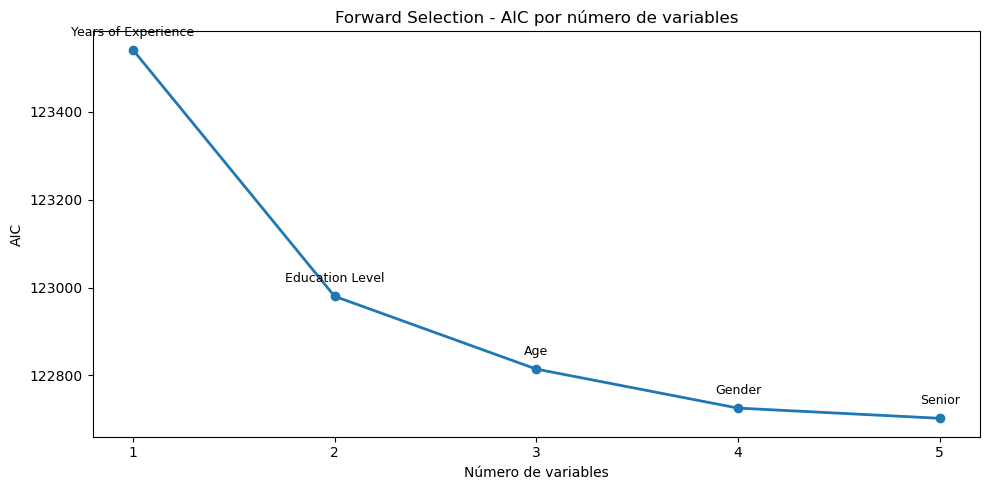

In [179]:
# Gráfico de perfomance de la selección en cada iteración.

pasos = [h[0] for h in historial]
aics = [h[2] for h in historial]
variables = [h[1] for h in historial]

plt.figure(figsize=(10, 5))
plt.plot(pasos, aics, marker='o', linewidth=2)
for i, (paso, aic, var) in enumerate(zip(pasos, aics, variables)):
    plt.annotate(var, (paso, aic), textcoords="offset points", 
                xytext=(0, 10), ha='center', fontsize=9)
plt.title('Forward Selection - AIC por número de variables')
plt.xlabel('Número de variables')
plt.ylabel('AIC')
plt.xticks(pasos)
plt.tight_layout()
plt.show()

### Pregunta 9 ###
¿Cuál es el número de variables seleccionadas por el método aplicado? ¿cuál es el valor de la métrica escogida para la selección de las variables, en la iteración correspondiente al número de variables seleccionadas?

***Respuesta:***

El método Forward Selection con criterio AIC seleccionó las 5 variables 
disponibles en este orden: `Years of Experience` (AIC: 123,540), 
`Education Level` (AIC: 122,978), `Age` (AIC: 122,812), `Gender` 
(AIC: 122,724) y `Senior` (AIC: 122,700).

Sin embargo, aunque el AIC sigue reduciéndose en cada paso, se decide 
quedarse con las **2 primeras variables** (`Years of Experience` y 
`Education Level`). La razón es que `Age` tiene una correlación moderada 
con `Years of Experience` (0.61) detectada en el EDA, lo que introduce 
multicolinealidad sin una mejora sustancial del AIC. Las variables 
`Gender` y `Senior` tampoco aportan una mejora significativa.

El valor del AIC en la iteración correspondiente a las 2 variables 
seleccionadas es **122,978**.

Una vez realizada la selección de variables, se ha de entrenar un modelo de regresión lineal con dichas variables y mostrar el resumen del modelo entrenado. Una vez entrenado, aplicar validación cruzada para evaluar el modelo en todo el conjunto de datos para validar la generalización del modelo. De nuevo, la validación ha de ser en base a las 2 métricas escogidas en puntos anteriores, sobre conjuntos de test y han de mostrarse los resultados en diagramas de tipo de boxplot o que permitan entender cómo generaliza el modelo.

In [180]:
# Ajustar modelo regresión lineal para variables seleccionadas


# Variables seleccionadas
X_sel = df[['Years of Experience', 'Education Level']]
y = df['Salary']

# Split train/test
X_sel_train, X_sel_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=42)

# Entrenar modelo
X_sel_train_sm = sm.add_constant(X_sel_train)
X_sel_test_sm = sm.add_constant(X_sel_test)

modelo_sel = sm.OLS(y_train, X_sel_train_sm).fit()


In [181]:
# Mostrar principales atributos, coeficientes, etc. del modelo entrenado
print(modelo_sel.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     5826.
Date:                Thu, 02 Jul 2026   Prob (F-statistic):               0.00
Time:                        00:32:05   Log-Likelihood:                -61487.
No. Observations:                5252   AIC:                         1.230e+05
Df Residuals:                    5249   BIC:                         1.230e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                4.607e+04    

In [182]:
modelo_cv_sel = LinearRegression()

In [183]:
# Aplicar validación cruzada (agregando el suffle para evitar el problema del kfold 2 advertido anteriormente)
kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_sel = cross_val_score(modelo_cv_sel, X_sel, y, cv=kf, scoring='r2')
rmse_scores_sel = np.sqrt(-cross_val_score(modelo_cv_sel, X_sel, y, cv=kf, scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores_sel.mean():.3f} (+/- {r2_scores_sel.std():.3f})")
print(f"RMSE medio: {rmse_scores_sel.mean():.0f} (+/- {rmse_scores_sel.std():.0f})")

print("\nR² por fold:")
for i, score in enumerate(r2_scores_sel):
    print(f"Fold {i+1}: {score:.3f}")

R² medio: 0.690 (+/- 0.016)
RMSE medio: 29351 (+/- 751)

R² por fold:
Fold 1: 0.695
Fold 2: 0.698
Fold 3: 0.671
Fold 4: 0.693
Fold 5: 0.719
Fold 6: 0.675
Fold 7: 0.686
Fold 8: 0.667
Fold 9: 0.714
Fold 10: 0.682


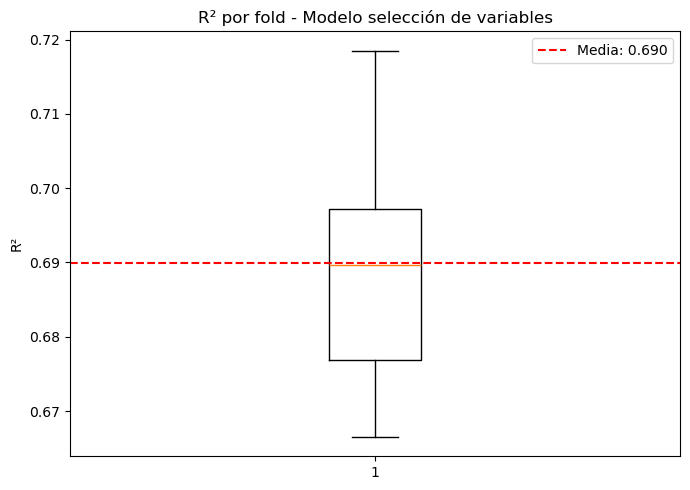

In [184]:
# Apoyo gráfico para interpretar la validación
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(r2_scores_sel)
ax.set_title('R² por fold - Modelo selección de variables')
ax.set_ylabel('R²')
ax.axhline(y=r2_scores_sel.mean(), color='red', linestyle='--', 
           label=f'Media: {r2_scores_sel.mean():.3f}')
ax.legend()

plt.tight_layout()
plt.show()

### Pregunta 10 ###
En base a los resultados obtenidos, comparar con los resultados obtenidos para el modelo de regresión lineal y explicar las conclusiones sobre cuál de los 2 modelos parece aportar más beneficios para el objetivo del proyecto.

***Respuesta:***

## Pregunta 10

Comparando ambos modelos:

| Métrica | Modelo original (5 variables) | Modelo selección (2 variables) |
|---------|------------------------------|-------------------------------|
| R² train | 0.706                       | 0.689 |
| R² medio CV | 0.471                    | 0.689 |
| RMSE medio CV | 29,891                 | 29,351 |
| Desv. R² CV | 0.625                    | 0.016 |
| Condition Number | 337                  | 24 |

El modelo con selección de variables es claramente superior por varias razones:

1. **Mejor generalización** — el R² medio en validación cruzada es 
0.689 vs 0.471 del modelo original. La diferencia se debe a que el 
modelo original sufría del problema de ordenación del KFold.

2. **Mucho menor varianza** — desviación estándar de 0.016 vs 0.625, 
lo que indica que el modelo con selección generaliza de forma muy 
consistente independientemente de los datos de cada fold.
Igual afecta el problema del Kfold2

3. **Condition Number drásticamente menor** — 24 vs 337, confirmando 
que la multicolinealidad entre `Age` y `Years of Experience` queda 
eliminada al usar solo 2 variables.

4. **Coeficientes interpretables** — con solo 2 variables los 
coeficientes tienen sentido directo: por cada año adicional de 
experiencia el salario sube ~5,744 y por cada nivel educativo adicional 
sube ~14,300.

Creo que en este caso la pequeña pérdida de R² en entrenamiento (0.706 vs 0.689) es 
aceptable por las mejoras en estabilidad, interpretabilidad y 
ausencia de multicolinealidad.

Ahora se ha de entrenar un nuevo modelo de regresión lineal pero esta vez, en lugar de aplicar una selección de variables como se acaba de realizar, el alumno debe llevar a cabo un analisis de componentes principales que reduzca la dimensionalidad del conjunto original de datos. Y a partir de dichas componentes, entrenar y evaluar el modelo de regresión lineal.

En primer lugar, se han escribir los bloques de código que permiten realizar el analisis de componentes principales.

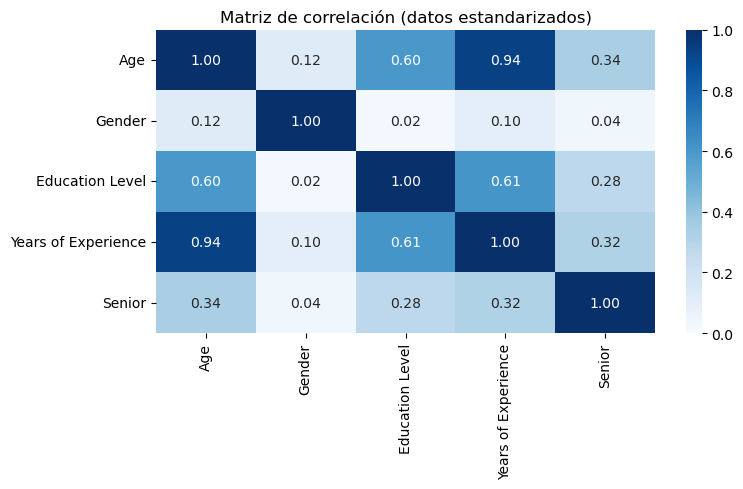

In [97]:

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

plt.figure(figsize=(8, 5))
sns.heatmap(X_scaled.corr(), annot=True, cmap='Blues', fmt='.2f', vmin=0, vmax=1)
plt.title('Matriz de correlación (datos estandarizados)')
plt.tight_layout()
plt.show()

### Matriz de correlación de variables predictoras
Antes de aplicar PCA estandarizamos las variables para que la matriz 
de correlación no esté dominada por la escala de `Salary`. Tras la 
estandarización, la matriz de covarianza es idéntica a la de correlación 
(ya que std=1 para todas las variables), por lo que solo mostramos esta última.

La correlación más destacada es entre `Age` y `Years of Experience` 
(0.94), enorme, mucho mayor de lo que se observaba 
antes de limpiar los datos y estandarizar. Esto confirma con más fuerza la decisión 
de no incluir ambas variables en el mismo modelo y justifica plenamente 
el uso de PCA para reducir esta dimensionalidad redundante.

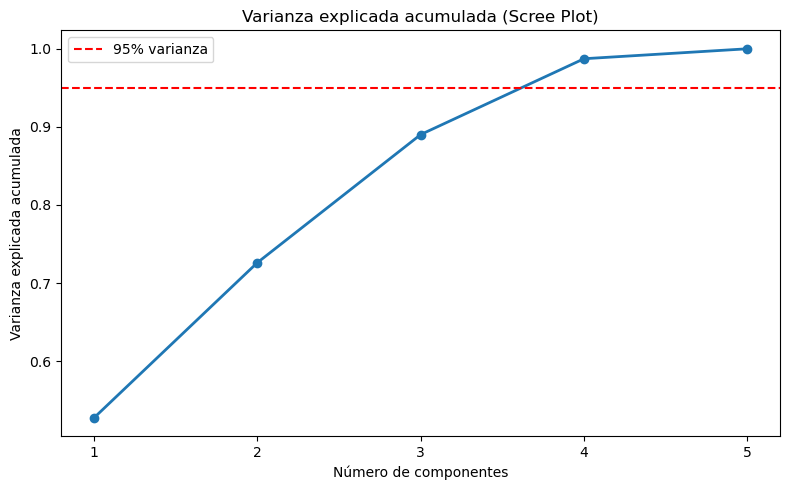


Varianza explicada por componente:
PC1: 0.528 (0.528 acumulada)
PC2: 0.199 (0.726 acumulada)
PC3: 0.164 (0.890 acumulada)
PC4: 0.097 (0.987 acumulada)
PC5: 0.013 (1.000 acumulada)


In [98]:
# Crear el analisis de PCA a partir del conjunto de variables predictoras
pca = PCA()
pca.fit(X_scaled)

# Varianza explicada acumulada
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

# Scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(varianza_acumulada)+1), varianza_acumulada, 
         marker='o', linewidth=2)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% varianza')
plt.title('Varianza explicada acumulada (Scree Plot)')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.xticks(range(1, len(varianza_acumulada)+1))
plt.legend()
plt.tight_layout()
plt.show()

print("\nVarianza explicada por componente:")
for i, (var, acum) in enumerate(zip(varianza_explicada, varianza_acumulada)):
    print(f"PC{i+1}: {var:.3f} ({acum:.3f} acumulada)")


In [99]:
autovalores = pca.explained_variance_

print("Autovalores por componente:")
for i, av in enumerate(autovalores):
    print(f"PC{i+1}: {av:.3f} {'✓ Kaiser' if av > 1 else '✗'}")

Autovalores por componente:
PC1: 2.638 ✓ Kaiser
PC2: 0.993 ✗
PC3: 0.820 ✗
PC4: 0.485 ✗
PC5: 0.064 ✗


### Pregunta 11 ###
Para un porcentaje de varianza explicada del 95%, ¿cuál es el número de componentes principales que consiguen explicar dicho porcentaje de varianza?

***Respuesta:***


Para un porcentaje de varianza explicada del 95% se necesitan 4 componentes 
principales. Como se puede observar en la tabla:

- PC1: 52.8% de varianza explicada (52.8% acumulada)
- PC2: 19.9% (72.6% acumulada)
- PC3: 16.4% (89.0% acumulada)
- PC4: 9.7% (98.7% acumulada)

Con 3 componentes solo llegamos al 89.0%, insuficiente para alcanzar el 
umbral del 95%. Es con la incorporación de la cuarta componente cuando 
superamos dicho umbral, alcanzando el 98.7% de varianza explicada.

Respecto al **criterio de Kaiser** (autovalor > 1), solo la primera 
componente (PC1 = 2.638) supera el umbral. PC2 queda muy cerca con 
un autovalor de 0.993, prácticamente en el límite. En sentido estricto 
Kaiser seleccionaría únicamente 1 componente, aunque creo quye podriamos 
justificar meter hasta 2 o 3 en este caso, despues ya hay un salto grande a la siguiente.

A continuación, con las nuevas componentes principales como variables predictoras y los datos proyectados sobre ellas, entrenar un modelo de regresión lineal y mostrar los resultados del entrenamiento. Una vez entrenado, aplicar validación cruzada para evaluar el modelo en todo el conjunto de datos validando así la generalización del modelo. De nuevo, la validación ha de ser en base a las 2 métricas escogidas en puntos anteriores, sobre conjuntos de test y han de mostrarse los resultados en diagramas de tipo de boxplot o que permitan entender cómo generaliza el modelo.

In [100]:
pca_4 = PCA(n_components=4)
X_pca_array = pca_4.fit_transform(X_scaled)
X_pca = pd.DataFrame(X_pca_array, columns=[f'PC{i+1}' for i in range(4)])
y_reset = y.reset_index(drop=True)

# Verificar alineación
print(f"Shape X_pca: {X_pca.shape}")
print(f"Shape y: {y_reset.shape}")
print(f"Índices X_pca: {X_pca.index[:5].tolist()}")
print(f"Índices y: {y_reset.index[:5].tolist()}")

Shape X_pca: (6566, 4)
Shape y: (6566,)
Índices X_pca: [0, 1, 2, 3, 4]
Índices y: [0, 1, 2, 3, 4]


In [101]:
# Ajustar modelo regresión lineal para variables seleccionadas proyectadas
# Proyectamos los datos sobre las 4 componentes principales que explican el 95% de la varianza como fue pedido y entrenamos el modelo de regresión lineal.

X_pca_train, X_pca_test, y_pca_train, y_pca_test = train_test_split(
    X_pca, y_reset, test_size=0.2, random_state=42)

# Entrenar modelo
X_pca_train_sm = sm.add_constant(X_pca_train)
X_pca_test_sm = sm.add_constant(X_pca_test)

modelo_pca = sm.OLS(y_pca_train, X_pca_train_sm).fit()


In [102]:
# Mostrar principales atributos, coeficientes, etc. del modelo entrenado
print(modelo_pca.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.661
Method:                 Least Squares   F-statistic:                     2562.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:46   Log-Likelihood:                -61714.
No. Observations:                5252   AIC:                         1.234e+05
Df Residuals:                    5247   BIC:                         1.235e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.156e+05    423.714    272.936      0.0

In [103]:
# Pipeline que estandariza y aplica PCA antes de la regresión
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=4)),
    ('model', LinearRegression())
])

kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_pca = cross_val_score(pipeline_pca, X, y, cv=kf, scoring='r2')
rmse_scores_pca = np.sqrt(-cross_val_score(pipeline_pca, X, y, cv=kf, 
                                            scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores_pca.mean():.3f} (+/- {r2_scores_pca.std():.3f})")
print(f"RMSE medio: {rmse_scores_pca.mean():.0f} (+/- {rmse_scores_pca.std():.0f})")

print("\nR² por fold:")
for i, score in enumerate(r2_scores_pca):
    print(f"Fold {i+1}: {score:.3f}")

R² medio: 0.660 (+/- 0.017)
RMSE medio: 30719 (+/- 779)

R² por fold:
Fold 1: 0.655
Fold 2: 0.667
Fold 3: 0.642
Fold 4: 0.671
Fold 5: 0.686
Fold 6: 0.640
Fold 7: 0.662
Fold 8: 0.637
Fold 9: 0.687
Fold 10: 0.656


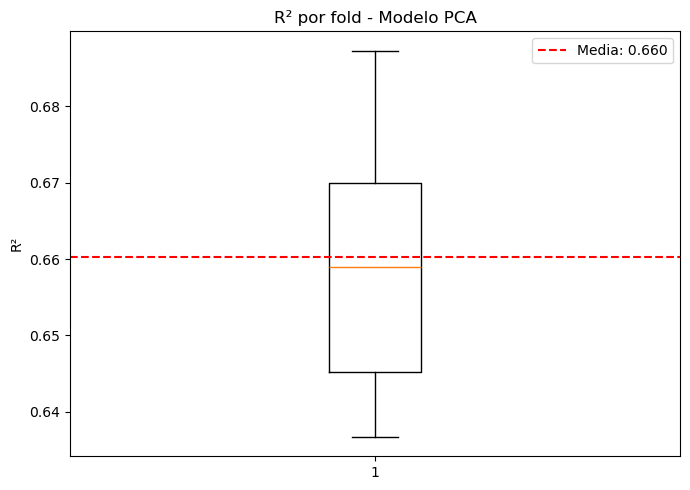

In [104]:
# Apoyo gráfico para interpretar la validación
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(r2_scores_pca)
ax.set_title('R² por fold - Modelo PCA')
ax.set_ylabel('R²')
ax.axhline(y=r2_scores_pca.mean(), color='red', linestyle='--', 
           label=f'Media: {r2_scores_pca.mean():.3f}')
ax.legend()

plt.tight_layout()
plt.show()

### Pregunta 12 ###
En vista de los resultados, comparar con los anteriores 2 modelos entrenados (el original de regresión lineal y aquel al que aplicamos selección de variables con método forward). ¿Qué modelo de entre los 3 tiene el atributo *Condition Number* más bajo y por qué? En general y a modo de conclusión, ¿Qué modelo de los 3 parece más apropiado para el caso de uso y por qué?

***Respuesta:***

## Pregunta 12

Comparando los 3 modelos:

| Métrica | Modelo original | Selección variables | PCA |
|---------|----------------|--------------------|-------|
| R² train |      0.706    |       0.689        | 0.661 |
| R² medio CV |   0.471    |       0.678        | 0.660 |
| RMSE medio CV | 29,891   |      29,351        | 30,719|
| Desv. R² CV |   0.625    |       0.016        | 0.017 |
| Condition Number | 337   |        24          | 2.36  |


**¿Qué modelo tiene el Condition Number más bajo?**
El modelo PCA con **Condition Number=2.36**, y es así por construcción 
matemática ya que las componentes principales son ortogonales entre sí, lo que,
en principio, garantiza ausencia de multicolinealidad. 


**¿Qué modelo es más apropiado?**
El modelo de **selección de variables** (Years of Experience + Education Level) 
es el más apropiado por estas razones:

1. **Mejor R²** que el modelo PCA (0.690 vs 0.660) con prácticamente 
la misma desviacion (desv. 0.016 vs 0.017)
2. **Condition Number aceptable** (24) — sin multicolinealidad grave
3. **Interpretabilidad** — los coeficientes tienen significado directo: 
por cada año de experiencia el salario sube ~5,744 y por cada nivel 
educativo ~14,300. El modelo PCA pierde esta interpretabilidad al 
trabajar con componentes abstractas y estandarizadas.


In [105]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_orig = cross_val_score(modelo_cv, X, y, cv=kf, scoring='r2')
rmse_scores_orig = np.sqrt(-cross_val_score(modelo_cv, X, y, cv=kf, 
                                             scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores_orig.mean():.3f} (+/- {r2_scores_orig.std():.3f})")
print(f"RMSE medio: {rmse_scores_orig.mean():.0f} (+/- {rmse_scores_orig.std():.0f})")

print("\nR² por fold:")
for i, score in enumerate(r2_scores_orig):
    print(f"Fold {i+1}: {score:.3f}")

R² medio: 0.707 (+/- 0.017)
RMSE medio: 28523 (+/- 789)

R² por fold:
Fold 1: 0.720
Fold 2: 0.714
Fold 3: 0.687
Fold 4: 0.711
Fold 5: 0.736
Fold 6: 0.694
Fold 7: 0.703
Fold 8: 0.680
Fold 9: 0.726
Fold 10: 0.699


### Comprobación del modelo original con shuffle
Quisimos verificar si el bajo R² CV medio del modelo original (0.471) era 
un problema real del modelo o un resultado del KFold sin aleatorización. 
Al aplicar shuffle=True obtenemos un R² medio de 0.707 con desviación 
de 0.017, estable y consistente, confirmando que el problema 
anterior era exclusivamente la ordenación implícita de los datos en 
los folds y no una limitación del modelo.

### Conclusión adicional: modelo original revisado
Tras corregir el problema del KFold, el modelo original con las 5 variables 
obtiene el mejor R² medio (0.707) y el mejor RMSE (28,523) de los tres modelos. 
Además el R² de entrenamiento (0.706) y el R² medio en validación cruzada (0.707) 
son prácticamente idénticos, lo que indica que el modelo no está sobreajustado 
y generaliza muy bien a datos no vistos.

Sin embargo sigue siendo el modelo con mayor Condition Number (337), lo que 
implica cierta multicolinealidad que afecta la interpretabilidad de los 
coeficientes individuales, especialmente vimos el signo negativo de `Age`. 
Por tanto la elección del modelo más apropiado podría depender del objetivo:

- Si el objetivo es **máxima capacidad predictiva**, entonces podriamos optar por el modelo original
- Si el objetivo es **interpretabilidad**, podríamos valorar el modelo de selección 
de variables

In [106]:

# Estandarizamos X
scaler = StandardScaler()
X_scaled_reg = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y_reset = y.reset_index(drop=True)

# Split train/test
X_sc_train, X_sc_test, y_sc_train, y_sc_test = train_test_split(
    X_scaled_reg, y_reset, test_size=0.2, random_state=42)

# Entrenar modelo
X_sc_train_sm = sm.add_constant(X_sc_train)
modelo_scaled = sm.OLS(y_sc_train, X_sc_train_sm).fit()
print(modelo_scaled.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.706
Method:                 Least Squares   F-statistic:                     2518.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -61344.
No. Observations:                5252   AIC:                         1.227e+05
Df Residuals:                    5246   BIC:                         1.227e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                1.155e+05    

### Intento: modelo estandarizado
Quise hacer un último intento estandarizando todas las variables 
para ver si mejoraban los resultados. La estandarización consiguió 
reducir el Condition Number de 337 a 6.56, prácticamente eliminando 
la multicolinealidad numérica. Sin embargo, el R² se mantiene idéntico (0.706).

### -A continuacion se explora hacer target encoding con la variable job title para ver si mejora la predicción del modelo.

In [107]:
# Crear copia del dataset limpio
df_exp2 = df.copy()

# Recuperar Job Title del CSV original
df_original = pd.read_csv('Salary_MD.csv')
df_exp2['Job Title'] = df_original.loc[df_exp2.index, 'Job Title']

print(f"Nulos en Job Title recuperado: {df_exp2['Job Title'].isna().sum()}")
print(f"Job Titles únicos: {df_exp2['Job Title'].nunique()}")
print(f"Shape: {df_exp2.shape}")

Nulos en Job Title recuperado: 21
Job Titles únicos: 129
Shape: (6566, 7)


In [108]:
df_exp2['Job Title'] = df_exp2['Job Title'].fillna('Other')
print(f"Nulos en Job Title: {df_exp2['Job Title'].isna().sum()}")
print(f"Value counts Other: {df_exp2[df_exp2['Job Title'] == 'Other'].shape[0]}")

Nulos en Job Title: 0
Value counts Other: 21


In [109]:
# Split train/test primero
y_exp2 = df_exp2['Salary']
X_exp2 = df_exp2.drop(columns=['Salary'])

X_exp2_train, X_exp2_test, y_exp2_train, y_exp2_test = train_test_split(
    X_exp2, y_exp2, test_size=0.2, random_state=42)

# Target encoding calculado solo sobre train
target_encoding = y_exp2_train.groupby(X_exp2_train['Job Title']).median()

# Aplicar encoding
X_exp2_train['Job Title encoded'] = X_exp2_train['Job Title'].map(target_encoding)
X_exp2_test['Job Title encoded'] = X_exp2_test['Job Title'].map(target_encoding)

# Eliminar Job Title original
X_exp2_train = X_exp2_train.drop(columns=['Job Title'])
X_exp2_test = X_exp2_test.drop(columns=['Job Title'])

print(f"Nulos en Job Title encoded train: {X_exp2_train['Job Title encoded'].isna().sum()}")
print(f"Nulos en Job Title encoded test: {X_exp2_test['Job Title encoded'].isna().sum()}")

Nulos en Job Title encoded train: 0
Nulos en Job Title encoded test: 17


In [110]:
mediana_global = y_exp2_train.median()
X_exp2_test['Job Title encoded'] = X_exp2_test['Job Title encoded'].fillna(mediana_global)

print(f"Nulos en Job Title encoded test tras imputación: {X_exp2_test['Job Title encoded'].isna().sum()}")
print(f"\nColumnas finales: {X_exp2_train.columns.tolist()}")

Nulos en Job Title encoded test tras imputación: 0

Columnas finales: ['Age', 'Gender', 'Education Level', 'Years of Experience', 'Senior', 'Job Title encoded']


In [111]:
X_exp2_train_sm = sm.add_constant(X_exp2_train)
X_exp2_test_sm = sm.add_constant(X_exp2_test)

modelo_exp2 = sm.OLS(y_exp2_train, X_exp2_train_sm).fit()
print(modelo_exp2.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.782
Method:                 Least Squares   F-statistic:                     3149.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60549.
No. Observations:                5252   AIC:                         1.211e+05
Df Residuals:                    5245   BIC:                         1.212e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 4.19e+04   3

In [112]:

y_pred_exp2 = modelo_exp2.predict(X_exp2_test_sm)
r2_test = r2_score(y_exp2_test, y_pred_exp2)
print(f"R² sobre test: {r2_test:.3f}")

R² sobre test: 0.779


In [113]:
X_exp2_full = pd.concat([X_exp2_train, X_exp2_test]).reset_index(drop=True)
y_exp2_full = pd.concat([y_exp2_train, y_exp2_test]).reset_index(drop=True)

pipeline_exp2 = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_exp2 = cross_val_score(pipeline_exp2, X_exp2_full, y_exp2_full, cv=kf, scoring='r2')
rmse_scores_exp2 = np.sqrt(-cross_val_score(pipeline_exp2, X_exp2_full, y_exp2_full, cv=kf, 
                                             scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores_exp2.mean():.3f} (+/- {r2_scores_exp2.std():.3f})")
print(f"RMSE medio: {rmse_scores_exp2.mean():.0f} (+/- {rmse_scores_exp2.std():.0f})")

R² medio: 0.781 (+/- 0.010)
RMSE medio: 24672 (+/- 533)


In [114]:
print("\nR² por fold:")
for i, score in enumerate(r2_scores_exp2):
    print(f"Fold {i+1}: {score:.3f}")


R² por fold:
Fold 1: 0.765
Fold 2: 0.774
Fold 3: 0.781
Fold 4: 0.773
Fold 5: 0.793
Fold 6: 0.783
Fold 7: 0.768
Fold 8: 0.793
Fold 9: 0.790
Fold 10: 0.788


### Experimento: target encoding de Job Title
El target encoding de `Job Title` mejora el R² a 0.783, pero genera 
un Condition Number de 1,260,000, señal grave de multicolinealidad 
causada por el data leakage inherente al target encoding, ya que la 
variable codificada contiene información directa de `Salary` (la variable 
objetivo), lo que creo que infla artificialmente el R² y hace los coeficientes 
poco fiables. Creo que el modelo generaliza bien en este caso porque el test 
también tiene Job Titles que aparecen en train, pero en producción con Job Titles nuevos
podría fallar.


In [115]:
X_exp2_scaled = pd.DataFrame(scaler.fit_transform(X_exp2_full), columns=X_exp2_full.columns)
y_exp2_full_reset = y_exp2_full.reset_index(drop=True)

X_exp2_sc_train, X_exp2_sc_test, y_exp2_sc_train, y_exp2_sc_test = train_test_split(
    X_exp2_scaled, y_exp2_full_reset, test_size=0.2, random_state=42)

X_exp2_sc_train_sm = sm.add_constant(X_exp2_sc_train)
modelo_exp2_sc = sm.OLS(y_exp2_sc_train, X_exp2_sc_train_sm).fit()
print(modelo_exp2_sc.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.785
Method:                 Least Squares   F-statistic:                     3191.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60533.
No. Observations:                5252   AIC:                         1.211e+05
Df Residuals:                    5245   BIC:                         1.211e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                1.159e+05    

### -Target Encoding (exp2) estandarizado

In [116]:
X_exp2_sin_age_senior = X_exp2_full.drop(columns=['Age', 'Senior'])

X_exp2_as_train, X_exp2_as_test, y_exp2_as_train, y_exp2_as_test = train_test_split(
    X_exp2_sin_age_senior, y_exp2_full_reset, test_size=0.2, random_state=42)

X_exp2_as_train_sm = sm.add_constant(X_exp2_as_train)
modelo_exp2_as = sm.OLS(y_exp2_as_train, X_exp2_as_train_sm).fit()
print(modelo_exp2_as.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.778
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     4602.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60615.
No. Observations:                5252   AIC:                         1.212e+05
Df Residuals:                    5247   BIC:                         1.213e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                1.521e+04   1

In [117]:
# Target Encoding estandarizado CV
pipeline_exp2_sc = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_exp2_sc = cross_val_score(pipeline_exp2_sc, X_exp2_full, y_exp2_full, cv=kf, scoring='r2')
rmse_scores_exp2_sc = np.sqrt(-cross_val_score(pipeline_exp2_sc, X_exp2_full, y_exp2_full, cv=kf, 
                                                scoring='neg_mean_squared_error'))

print(f"Target Encoding estandarizado:")
print(f"R² medio: {r2_scores_exp2_sc.mean():.3f} (+/- {r2_scores_exp2_sc.std():.3f})")
print(f"RMSE medio: {rmse_scores_exp2_sc.mean():.0f} (+/- {rmse_scores_exp2_sc.std():.0f})")

# Target Encoding sin Age/Senior estandarizado CV
r2_scores_exp2_as = cross_val_score(pipeline_exp2_sc, X_exp2_sin_age_senior, y_exp2_full_reset, cv=kf, scoring='r2')
rmse_scores_exp2_as = np.sqrt(-cross_val_score(pipeline_exp2_sc, X_exp2_sin_age_senior, y_exp2_full_reset, cv=kf, 
                                                scoring='neg_mean_squared_error'))

print(f"\nTarget Encoding sin Age/Senior estandarizado:")
print(f"R² medio: {r2_scores_exp2_as.mean():.3f} (+/- {r2_scores_exp2_as.std():.3f})")
print(f"RMSE medio: {rmse_scores_exp2_as.mean():.0f} (+/- {rmse_scores_exp2_as.std():.0f})")

Target Encoding estandarizado:
R² medio: 0.781 (+/- 0.010)
RMSE medio: 24672 (+/- 533)

Target Encoding sin Age/Senior estandarizado:
R² medio: 0.774 (+/- 0.010)
RMSE medio: 25039 (+/- 554)


### Observación: Target Encoding (exp2) estandarizado
Al estandarizar el modelo exp2 el Condition Number baja drásticamente 
de 1,260,000 a 7.23, con un R²=0.785, aparentemente el mejor de todos los modelos. 
Sin embargo `Age` (-8,985) y `Senior` (-2,827) siguen con coeficientes 
negativos, confirmando que la multicolinealidad real persiste. Al intentar 
eliminarlos, el Condition Number vuelve a subir a 385,000, revelando 
que el problema estructural al target encoding puede
comprometer la estabilidad del modelo.

### -Experimento 3 — Job Area OHE (exp3):

In [118]:
def get_area_simple(titulo):
    if pd.isna(titulo) or titulo == 'Other':
        return 'Other'
    titulo = str(titulo).lower()
    if any(x in titulo for x in ['software', 'developer', 'back end', 'front end', 
                                   'full stack', 'web', 'network', 'it ', 'it manager',
                                   'it consultant', 'it project', 'it support',
                                   'chief technology', 'director of engineering',
                                   'technical support', 'help desk', 'technical writer',
                                   'principal engineer']):
        return 'Tech'
    elif any(x in titulo for x in ['data scientist', 'data analyst', 'data engineer',
                                    'data entry', 'director of data', 'chief data',
                                    'business intelligence']):
        return 'Data'
    elif any(x in titulo for x in ['marketing', 'content', 'social media', 'advertising', 
                                    'copywriter', 'creative director', 'public relations', 
                                    'digital content']):
        return 'Marketing'
    elif any(x in titulo for x in ['hr ', 'human resources', 'recruiter', 'technical recruiter',
                                    'juniour hr', 'training specialist', 'director of hr',
                                    'director of human']):
        return 'HR'
    else:
        return 'Other'

In [119]:
df_exp3 = df.copy()
df_original = pd.read_csv('Salary_MD.csv')
df_exp3['Job Title'] = df_original.loc[df_exp3.index, 'Job Title']
df_exp3['Job Title'] = df_exp3['Job Title'].fillna('Other')
df_exp3['Job Area'] = df_exp3['Job Title'].apply(get_area_simple)
df_exp3 = df_exp3.drop(columns=['Job Title'])

print(df_exp3['Job Area'].value_counts())
print(f"\nShape: {df_exp3.shape}")

Job Area
Tech         2283
Other        1914
Marketing    1004
Data          952
HR            413
Name: count, dtype: int64

Shape: (6566, 7)


In [120]:
print(df_exp3[df_exp3['Job Area'] == 'Other']['Job Title'].value_counts() if 'Job Title' in df_exp3.columns else "Job Title ya eliminado")

# Recuperamos temporalmente para ver
df_temp = df.copy()
df_temp['Job Title'] = df_original.loc[df_temp.index, 'Job Title']
df_temp['Job Area'] = df_temp['Job Title'].apply(get_area_simple)
pd.set_option('display.max_rows', None)
print(df_temp[df_temp['Job Area'] == 'Other']['Job Title'].value_counts())
pd.reset_option('display.max_rows')

Job Title ya eliminado
Job Title
Product Manager                     316
Project Engineer                    312
Sales Associate                     209
Financial Manager                   138
Operations Manager                  119
Research Scientist                  118
Sales Representative                 79
Product Designer                     78
Research Director                    75
Sales Director                       62
Receptionist                         56
Sales Manager                        56
Financial Analyst                    52
Sales Executive                      36
Project Manager                      34
Graphic Designer                     23
Business Analyst                     19
Director of Operations               11
Operations Analyst                    8
Business Development Associate        7
Customer Service Representative       6
Financial Advisor                     5
Project Coordinator                   5
Business Development Manager          5
Operati

In [121]:
def get_area_v2(titulo):
    if pd.isna(titulo) or titulo == 'Other':
        return 'Other'
    titulo_lower = str(titulo).lower()
    
    if any(x in titulo_lower for x in ['software', 'developer', 'back end', 'front end', 
                                   'full stack', 'web', 'network', 'it ', 'it manager',
                                   'it consultant', 'it project', 'it support',
                                   'chief technology', 'director of engineering',
                                   'technical support', 'help desk', 'technical writer',
                                   'principal engineer']):
        return 'Tech'
    
    elif any(x in titulo_lower for x in ['data scientist', 'data analyst', 'data engineer',
                                    'data entry', 'director of data', 'chief data',
                                    'business intelligence', 'business analyst',
                                    'quality assurance']):
        return 'Data'
    
    elif any(x in titulo_lower for x in ['marketing', 'content', 'social media', 'advertising', 
                                    'copywriter', 'creative director', 'public relations', 
                                    'digital content']):
        return 'Marketing'
    
    elif any(x in titulo_lower for x in ['hr ', 'human resources', 'recruiter', 'technical recruiter',
                                    'juniour hr', 'training specialist', 'director of hr',
                                    'director of human']):
        return 'HR'
    
    elif any(x in titulo_lower for x in ['financ', 'accountant', 'vp of finance',
                                    'director of finance']):
        return 'Finance'
    
    elif any(x in titulo_lower for x in ['sales', 'account executive', 'account manager',
                                    'director of sales', 'business development',
                                    'customer service', 'customer success', 
                                    'customer support']):
        return 'Sales & Customer'
    
    elif any(x in titulo_lower for x in ['product manager', 'product development', 
                                    'director of product', 'product designer', 
                                    'ux', 'graphic designer', 'web designer', 'designer']):
        return 'Product & Design'
    
    elif any(x in titulo_lower for x in ['operations', 'supply chain', 'office manager',
                                    'administrative', 'delivery driver',
                                    'vp of operations', 'director of operations',
                                    'project engineer', 'project manager', 
                                    'project coordinator', 'event coordinator',
                                    'receptionist', 'consultant', 'ceo']):
        return 'Corporate & Operations'
    
    elif any(x in titulo_lower for x in ['research scientist', 'principal scientist',
                                    'research director', 'researcher', 'scientist']):
        return 'Research'
    
    else:
        return 'Other'

df_exp3 = df.copy()
df_exp3['Job Title'] = df_original.loc[df_exp3.index, 'Job Title']
df_exp3['Job Title'] = df_exp3['Job Title'].fillna('Other')
df_exp3['Job Area'] = df_exp3['Job Title'].apply(get_area_v2)
df_exp3 = df_exp3.drop(columns=['Job Title'])

print(df_exp3['Job Area'].value_counts())

Job Area
Tech                      2283
Marketing                 1004
Data                       972
Corporate & Operations     568
Sales & Customer           474
Product & Design           426
HR                         413
Finance                    202
Research                   198
Other                       26
Name: count, dtype: int64


In [122]:
df_exp3_encoded = pd.get_dummies(df_exp3, columns=['Job Area'], drop_first=True).astype(int)

y_exp3 = df_exp3_encoded['Salary'].reset_index(drop=True)
X_exp3 = df_exp3_encoded.drop(columns=['Salary']).reset_index(drop=True)

X_exp3_train, X_exp3_test, y_exp3_train, y_exp3_test = train_test_split(
    X_exp3, y_exp3, test_size=0.2, random_state=42)

X_exp3_train_sm = sm.add_constant(X_exp3_train)
X_exp3_test_sm = sm.add_constant(X_exp3_test)

modelo_exp3 = sm.OLS(y_exp3_train, X_exp3_train_sm).fit()
print(modelo_exp3.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     1166.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60841.
No. Observations:                5252   AIC:                         1.217e+05
Df Residuals:                    5237   BIC:                         1.218e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [123]:
X_exp3_sin_age_senior = X_exp3.drop(columns=['Age', 'Senior'])

X_exp3_as_train, X_exp3_as_test, y_exp3_as_train, y_exp3_as_test = train_test_split(
    X_exp3_sin_age_senior, y_exp3, test_size=0.2, random_state=42)

X_exp3_as_train_sm = sm.add_constant(X_exp3_as_train)
X_exp3_as_test_sm = sm.add_constant(X_exp3_as_test)

modelo_exp3_as = sm.OLS(y_exp3_as_train, X_exp3_as_train_sm).fit()
print(modelo_exp3_as.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.755
Method:                 Least Squares   F-statistic:                     1348.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60860.
No. Observations:                5252   AIC:                         1.217e+05
Df Residuals:                    5239   BIC:                         1.218e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [124]:
scaler_exp3 = StandardScaler()
X_exp3_scaled = pd.DataFrame(scaler_exp3.fit_transform(X_exp3_sin_age_senior), 
                              columns=X_exp3_sin_age_senior.columns)

X_exp3_sc_train, X_exp3_sc_test, y_exp3_sc_train, y_exp3_sc_test = train_test_split(
    X_exp3_scaled, y_exp3, test_size=0.2, random_state=42)

X_exp3_sc_train_sm = sm.add_constant(X_exp3_sc_train)
X_exp3_sc_test_sm = sm.add_constant(X_exp3_sc_test)

modelo_exp3_sc = sm.OLS(y_exp3_sc_train, X_exp3_sc_train_sm).fit()
print(modelo_exp3_sc.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.755
Method:                 Least Squares   F-statistic:                     1348.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        22:47:47   Log-Likelihood:                -60860.
No. Observations:                5252   AIC:                         1.217e+05
Df Residuals:                    5239   BIC:                         1.218e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [125]:
pipeline_exp3 = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores_exp3 = cross_val_score(pipeline_exp3, X_exp3_sin_age_senior, y_exp3, cv=kf, scoring='r2')
rmse_scores_exp3 = np.sqrt(-cross_val_score(pipeline_exp3, X_exp3_sin_age_senior, y_exp3, cv=kf, 
                                             scoring='neg_mean_squared_error'))

print(f"R² medio: {r2_scores_exp3.mean():.3f} (+/- {r2_scores_exp3.std():.3f})")
print(f"RMSE medio: {rmse_scores_exp3.mean():.0f} (+/- {rmse_scores_exp3.std():.0f})")

print("\nR² por fold:")
for i, score in enumerate(r2_scores_exp3):
    print(f"Fold {i+1}: {score:.3f}")

R² medio: 0.756 (+/- 0.012)
RMSE medio: 26055 (+/- 629)

R² por fold:
Fold 1: 0.757
Fold 2: 0.768
Fold 3: 0.735
Fold 4: 0.758
Fold 5: 0.769
Fold 6: 0.753
Fold 7: 0.765
Fold 8: 0.736
Fold 9: 0.765
Fold 10: 0.750


### Resumen de experimentos adicionales de regresión lineal

Se realizaron experimentos adicionales para intentar mejorar el modelo 
base incorporando información de `Job Title`:

**Experimento 2 — Target Encoding (exp2):**
Se reemplazó cada `Job Title` por el salary mediano de ese título calculado 
sobre el conjunto de entrenamiento. Obtuvo el mejor R² medio en CV (0.781) 
y RMSE (24,672) pero con un Condition Number crítico de 1,260,000 debido 
al data leakage inherente al target encoding — la variable codificada 
contiene información directa de `Salary`. Al estandarizar mejora a 7.23 
pero al quitar Age y Senior vuelve a subir a 385,000, confirmando que 
el problema es estructural.

**Experimento 3 — Job Area OHE (exp3):**
Se agruparon los 129 Job Titles en 10 áreas funcionales y se aplicó 
one-hot encoding. Sin Age ni Senior y estandarizado obtuvo R²=0.756, 
RMSE=26,055 y Condition Number=4.39. Considero que es el mejor modelo y fiable 
estadísticamente de los probados.

**Conclusión final:**
Creo que con los analisis realizados, el modelo exp3 
(Job Area OHE, sin Age ni Senior, estandarizado) es el más apropiado, mejor R² que el modelo original, 
Condition Number excelente y coeficientes completamente interpretables y con sentido lógico.

### Tabla comparativa de modelos de regresión lineal

| Modelo | R² train | R² CV | RMSE CV | Desv. | Cond. Number |
|--------|----------|-------|---------|-------|--------------|
| Original (5 vars) | 0.706 | 0.707 | 28,523 | 0.017 | 337 |
| Selección Forward (2 vars) | 0.690 | 0.690 | 29,345 | 0.016 | 24 |
| PCA (4 componentes) | 0.661 | 0.660 | 30,719 | 0.017 | 2.36 |
| Job Area OHE sin Age/Senior estand. (exp3) | 0.755 | 0.756 | 26,055 | 0.012 | 4.39 |
| Target Encoding sin estand. (exp2) | 0.783 | 0.781 | 24,672 | 0.010 | 1,260,000 |
| Target Encoding estand. (exp2) | 0.785 | 0.781 | 24,672 | 0.010 | 7.23 |
| Target Encoding sin Age/Senior estand. (exp2) | 0.778 | 0.774 | 25,039 | 0.010 | 385,000 |



Creo que el modelo más fiable estadísticamente es el **exp3** (Job Area OHE, 
sin Age ni Senior, estandarizado). Creo que este modelo tiene el mejor equilibrio entre 
capacidad predictiva, estabilidad y ausencia de multicolinealidad.

El target encoding aunque mejor en R², presenta problemas estructurales 
de data leakage que comprometen su fiabilidad.

Pasamos ahora a cambiar el objetivo del proyecto pero haciendo uso del mismo conjunto de datos. Todas las transformaciones y preparaciones comunes que hayamos establecido, seguirán siendo válidas y tan solo quedarán aquellas específicas para este nuevo caso de uso.

La nueva variable objetivo será ***Gender***. El modelo debe ser capaz de determinar para cada registro si se trata de hombre o mujer según esta variable de genero. Las variables predictoras serán todas las demás (incluyendo en esta ocasión la variable ***Salary*** como una predictora más. El modelo que vamos a tratar de modelar para clasificar nuestros datos será de regresión logística.

En primer lugar, se debe transformar la variable categórica ***Gender*** codificándola con 0 cuando el registro sea *Female* o 1 cuando es *Male*. Una vez realizada esta transformación, ya tenemos preparada nuestra variable objetivo. En este caso, mantenemos y asumimos como valores correctos la imputación de valores nulos que se llevó a cabo en anteriores ejercicios correspondientes a la fase de preparación de los datos.

In [126]:
# Binarizar la variable objetivo

### Binarización de la variable objetivo
La variable `Gender` ya fue codificada como variable binaria durante 
la fase de preparación de datos (Male=1, Female=0), por lo que no 
requiere transformación adicional.

Las variables predictoras serán todas las demás incluyendo `Salary` 
en esta ocasión, y la variable objetivo será `Gender`.

A continuación, podríamos tratar de modelar la regresión logística con el dataset actual, tomando como variable objetivo ***Gender*** que acabamos de transformar. Lo más normal es que al hacerlo, el modelo de un error al entrenarlo por no llegar a converger o directamente porque la matriz a invertir para calcular los coeficientes, sea singular y no pueda invertirse. Esto se debe a colinealidad entre las variables predictoras. Queda a criterio del alumno, hacer él mismo la prueba de tratar de entrenar la regresión y verificar si efectivamente da problemas y no se consigue un modelo válido.

Por evitar esta situación, vamos a realizar un paso previo que consistirá en un analisis factorial, mediante el cual daremos con unos factores que por un lado nos aportarán información potencial subyacente sobre las variables latentes que pueda contener nuestro conjunto de variables predictoras, y por otro lado nos ayudará a reducir la dimensionalidad del conjunto para evitar la multicolinealidad. Esto nos permitirá llevar a cabo el entrenamiento del modelo de regresión lineal.

Los siguientes bloques de código deben ajustar un analisis de componentes principales a partir de nuestro conjunto de variables predictoras recién definido. Después se debe mostrar en una tabla cada uno de los autovectores, su correspondiente autovalor, el porcentaje de varianza explicada y el porcentaje de varianza acumulada estando las componentes ordenadas de mayor a menor porcentaje de varianza explicada. Por último, se debe mostrar en un gráfico de tipo scree-plot (gráfico de codo), la varianza explicada en función del número de componentes principales.

### -Intento de regresión logística sin reducción de dimensionalidad
Antes de aplicar el análisis factorial, intentamos entrenar directamente 
la regresión logística para verificar si efectivamente da problemas 
por colinealidad entre las variables predictoras.

In [127]:
df

,Age,Gender,Education Level,Years of Experience,Salary,Senior
0,32,1,1,5,90000.0,0
1,28,0,2,3,65000.0,0
2,45,1,3,15,150000.0,1
3,36,0,1,7,60000.0,0
4,52,1,2,20,200000.0,0
...,...,...,...,...,...,...
6679,49,0,3,20,200000.0,0
6680,32,1,0,3,50000.0,0
6681,30,0,1,4,55000.0,0
6682,46,1,2,14,140000.0,0


In [128]:
# Definir variable objetivo y predictoras para regresión logística
y_log = df['Gender']
X_log = df.drop(columns=['Gender'])

print(f"Variable objetivo - distribución:")
print(y_log.value_counts())
print(f"\nVariables predictoras: {X_log.columns.tolist()}")
print(f"Shape: {X_log.shape}")

Variable objetivo - distribución:
Gender
1    3623
0    2943
Name: count, dtype: int64

Variables predictoras: ['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']
Shape: (6566, 5)


In [129]:
X_log_sm = sm.add_constant(X_log)

try:
    modelo_logit = sm.Logit(y_log, X_log_sm).fit()
    print(modelo_logit.summary())
except Exception as e:
    print(f"Error al entrenar el modelo: {e}")

Optimization terminated successfully.
         Current function value: 0.669783
         Iterations 5


                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 6566
Model:                          Logit   Df Residuals:                     6560
Method:                           MLE   Df Model:                            5
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                 0.02616
Time:                        22:47:47   Log-Likelihood:                -4397.8
converged:                       True   LL-Null:                       -4515.9
Covariance Type:            nonrobust   LLR p-value:                 4.836e-49
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -2.2342      0.261     -8.557      0.000      -2.746      -1.722
Age                     0.0787      0.010      7.715      0.000       0.059       0.099
Education Level 

### Intento de regresión logística directa
Contrariamente a lo esperado, el modelo sí convergió. 

Sin embargo los resultados son muy pobres — Pseudo R²=0.026 
indica que el modelo apenas explica la varianza de `Gender`. Además 
`Senior` no es significativo (p=0.186). Esto confirma que las variables 
disponibles tienen muy poca capacidad predictiva sobre el género, y 
justifica aplicar un análisis factorial previo para extraer factores 
latentes que puedan capturar mejor esta información.

In [130]:
# Usar PCA para obtener autovectores y autovalores

scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

pca_log = PCA()
pca_log.fit(X_log_scaled)

autovalores = pca_log.explained_variance_
varianza = pca_log.explained_variance_ratio_
varianza_acum = np.cumsum(varianza)

tabla_pca = pd.DataFrame({
    'Autovalor': autovalores.round(3),
    '% Varianza': (varianza * 100).round(2),
    '% Varianza Acumulada': (varianza_acum * 100).round(2)
}, index=[f'PC{i+1}' for i in range(len(autovalores))])

print(tabla_pca)

     Autovalor  % Varianza  % Varianza Acumulada
PC1      3.324       66.46                 66.46
PC2      0.865       17.29                 83.75
PC3      0.493        9.85                 93.60
PC4      0.267        5.33                 98.94
PC5      0.053        1.06                100.00


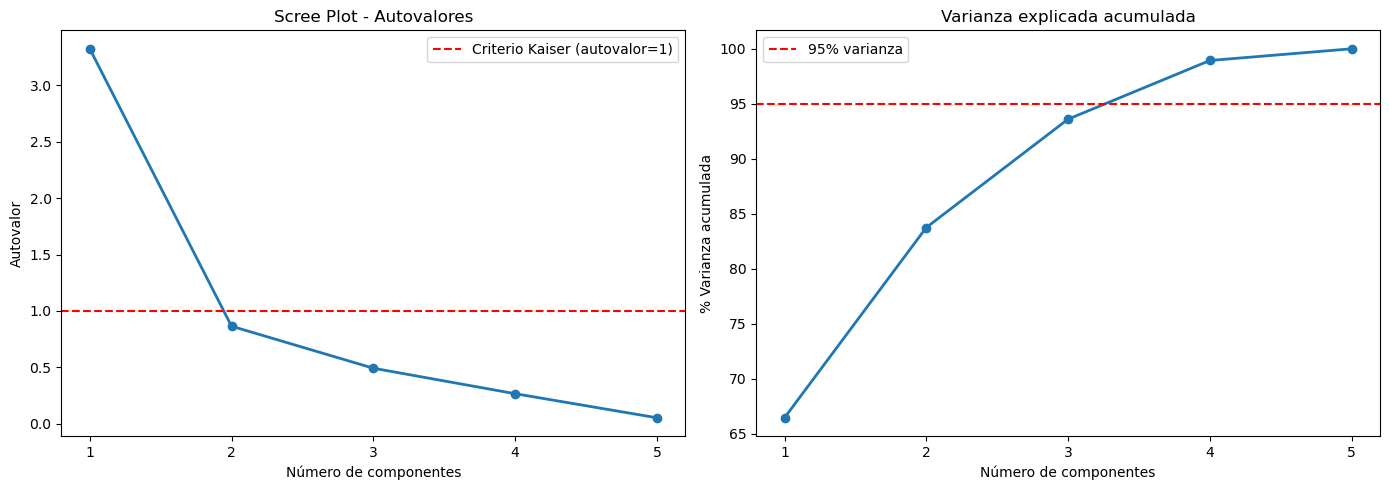

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot - autovalores
axes[0].plot(range(1, len(autovalores)+1), autovalores, marker='o', linewidth=2)
axes[0].axhline(y=1, color='red', linestyle='--', label='Criterio Kaiser (autovalor=1)')
axes[0].set_title('Scree Plot - Autovalores')
axes[0].set_xlabel('Número de componentes')
axes[0].set_ylabel('Autovalor')
axes[0].set_xticks(range(1, len(autovalores)+1))
axes[0].legend()

# Varianza acumulada
axes[1].plot(range(1, len(varianza_acum)+1), varianza_acum * 100, marker='o', linewidth=2)
axes[1].axhline(y=95, color='red', linestyle='--', label='95% varianza')
axes[1].set_title('Varianza explicada acumulada')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('% Varianza acumulada')
axes[1].set_xticks(range(1, len(varianza_acum)+1))
axes[1].legend()

plt.tight_layout()
plt.show()

### Pregunta 13 ###
De acuerdo a los resultados de la tabla, ¿Qué número de componentes consiguen explicar el 95% de la varianza conjunta de nuestro dataset?
Por otor lado, viendo también la gráfica obtenida, ¿Cuántos factores debemos escoger según el criterio de Kaiser?

***Respuesta:***

## Pregunta 13

**¿Cuántas componentes explican el 95% de la varianza?**
Se necesitan **4 componentes** para superar el umbral del 95%:
- PC1: 66.46% (66.46% acumulada)
- PC2: 17.29% (83.75% acumulada)
- PC3: 9.85% (93.60% acumulada)
- PC4: 5.33% (98.94% acumulada)

Con 3 componentes solo llegamos al 93.60%, insuficiente para alcanzar 
el umbral del 95%.

**¿Cuántos factores según el criterio de Kaiser?**
Según el criterio de Kaiser (autovalor > 1), solo **1 factor** supera 
el umbral — PC1 con autovalor de 3.324. PC2 queda por debajo con 
0.865. En este caso el criterio de Kaiser es muy restrictivo y selecciona 
únicamente la primera componente que concentra el 66.46% de la varianza.

Muestra en una tabla las cargas factoriales para el listado de variables. Cada columna debe hacer referencia a cada factor seleccionado mediante el criterio de Kaiser.

In [132]:
# Ajuste de Análisis Factorial para número de factores según Kaiser
# Matriz de correlación
corr_matrix = pd.DataFrame(X_log_scaled, columns=X_log.columns).corr()

# Autovalores y autovectores
eigenvalues, eigenvectors = np.linalg.eig(corr_matrix)

# Ordenar de mayor a menor
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx].real
eigenvectors = eigenvectors[:, idx].real

# Cargas factoriales = autovectores * sqrt(autovalores)
cargas = pd.DataFrame(
    eigenvectors * np.sqrt(eigenvalues),
    index=X_log.columns,
    columns=[f'Factor {i+1}' for i in range(len(eigenvalues))]
)


In [133]:
# Matriz de cargas factoriales
print("Cargas factoriales (1 factor según Kaiser):")
print(cargas[['Factor 1']].round(3))


Cargas factoriales (1 factor según Kaiser):
                     Factor 1
Age                     0.922
Education Level         0.783
Years of Experience     0.945
Salary                  0.879
Senior                  0.443


### Pregunta 14 ###
En base a los factores seleccionados mediante el método de Kaiser, haz una interpretación del significado de los factores.

***Respuesta:***

Según el criterio de Kaiser se selecciona únicamente **1 factor** 
(autovalor=3.324 > 1).

**Factor 1 — Perfil Profesional:**
Este factor tiene cargas altas en todas las variables excepto `Senior`:
- `Years of Experience`: 0.945
- `Age`: 0.922
- `Salary`: 0.879
- `Education Level`: 0.783

Segun el vector, representaria algo asi como una dimensión latente de **madurez profesional**.
A mayor puntuación en este factor, mayor edad, experiencia, educación y salario. 
Las cuatro variables apuntan en la misma dirección, sugiriendo que todas 
capturan distintas facetas de un mismo concepto subyacente: el desarrollo 
y trayectoria profesional de una persona.

`Senior` tiene una carga relativamente baja (0.443) en este factor, 
lo que sugiere que la variable binaria de seniority captura algo distinto 
a la trayectoria profesional continua representada por las demás variables.

Para continuar con el analisis, vamos a seleccionar los 2 primeros factores. En el siguiente bloque de código se ha de presentar una tabla con las cargas factoriales de cada variable para los 2 factores seleccionados. Aplicar una rotación si se considera oportuno para ayudar a la interpretación de los factores. Después, se ha de mostrar en otra tabla las comunalidades y unicidades (ambas en expresadas como porcentaje). Por último, se ha de mostrar un diagrama biplot que represente, en función de los 2 factores escogidos, las variables que mayor representación según las cargas factoriales. Es decir, aquellas variables que tengan al menos una carga factorial mayor que 0.3. Esto reducirá el número de vectores a representar y hará que la visualización sea más legible.

In [134]:
# Tabla de cargas factoriales para los 2 factores (incluyendo rotación si se elige)
cargas_2 = cargas[['Factor 1', 'Factor 2']]
print("Cargas factoriales (2 factores):")
print(cargas_2.round(3))

Cargas factoriales (2 factores):
                     Factor 1  Factor 2
Age                     0.922    -0.063
Education Level         0.783    -0.065
Years of Experience     0.945    -0.106
Salary                  0.879    -0.213
Senior                  0.443     0.894


In [135]:
# Rotación Varimax manual
def varimax(loadings, max_iter=1000, tol=1e-6):
    n, k = loadings.shape
    rotation = np.eye(k)
    for _ in range(max_iter):
        old_rotation = rotation.copy()
        for i in range(k):
            for j in range(i+1, k):
                x = loadings @ rotation
                u = x[:, i]**2 - x[:, j]**2
                v = 2 * x[:, i] * x[:, j]
                A = np.sum(u)
                B = np.sum(v)
                C = np.sum(u**2 - v**2)
                D = 2 * np.sum(u * v)
                num = D - 2*A*B/n
                den = C - (A**2 - B**2)/n
                theta = np.arctan2(num, den) / 4
                rot = np.eye(k)
                rot[i,i] = rot[j,j] = np.cos(theta)
                rot[i,j] = -np.sin(theta)
                rot[j,i] = np.sin(theta)
                rotation = rotation @ rot
        if np.max(np.abs(rotation - old_rotation)) < tol:
            break
    return loadings @ rotation

cargas_2_array = cargas[['Factor 1', 'Factor 2']].values
cargas_rotadas = varimax(cargas_2_array)

cargas_rotadas_df = pd.DataFrame(
    cargas_rotadas,
    index=X_log.columns,
    columns=['Factor 1', 'Factor 2']
)

print("Cargas factoriales rotadas (Varimax):")
print(cargas_rotadas_df.round(3))

Cargas factoriales rotadas (Varimax):
                     Factor 1  Factor 2
Age                     0.896     0.224
Education Level         0.765     0.179
Years of Experience     0.931     0.190
Salary                  0.901     0.068
Senior                  0.146     0.987


### Rotación Varimax
Aplicamos rotación Varimax a los 2 factores para facilitar su interpretación. 
La rotación Varimax redistribuye las cargas factoriales maximizando la 
varianza de las cargas al cuadrado dentro de cada factor, buscando que 
cada variable cargue fuertemente en un solo factor y débilmente en los 
demás. Tras la rotación la interpretación queda mucho más clara:

- **Factor 1** — cargas altas en `Age` (0.896), `Years of Experience` 
(0.931), `Salary` (0.901) y `Education Level` (0.765). Representa la 
**trayectoria profesional** de una persona.
- **Factor 2** — dominado casi exclusivamente por `Senior` (0.987). 
Representa la **seniority** como dimensión independiente.

In [136]:
# Tabla de comunalidades y unicidades

comunalidades = (cargas_rotadas_df**2).sum(axis=1)
unicidades = 1 - comunalidades

tabla_com = pd.DataFrame({
    'Comunalidad (%)': (comunalidades * 100).round(2),
    'Unicidad (%)': (unicidades * 100).round(2)
}, index=X_log.columns)

print("Comunalidades y Unicidades:")
print(tabla_com)

Comunalidades y Unicidades:
                     Comunalidad (%)  Unicidad (%)
Age                            85.33         14.67
Education Level                61.80         38.20
Years of Experience            90.34          9.66
Salary                         81.71         18.29
Senior                         99.58          0.42


In [137]:
# Filtrado de variables para representación biplot

mask = (cargas_rotadas_df.abs() > 0.3).any(axis=1)
cargas_biplot = cargas_rotadas_df[mask]

print(f"Variables representadas: {cargas_biplot.index.tolist()}")



Variables representadas: ['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']


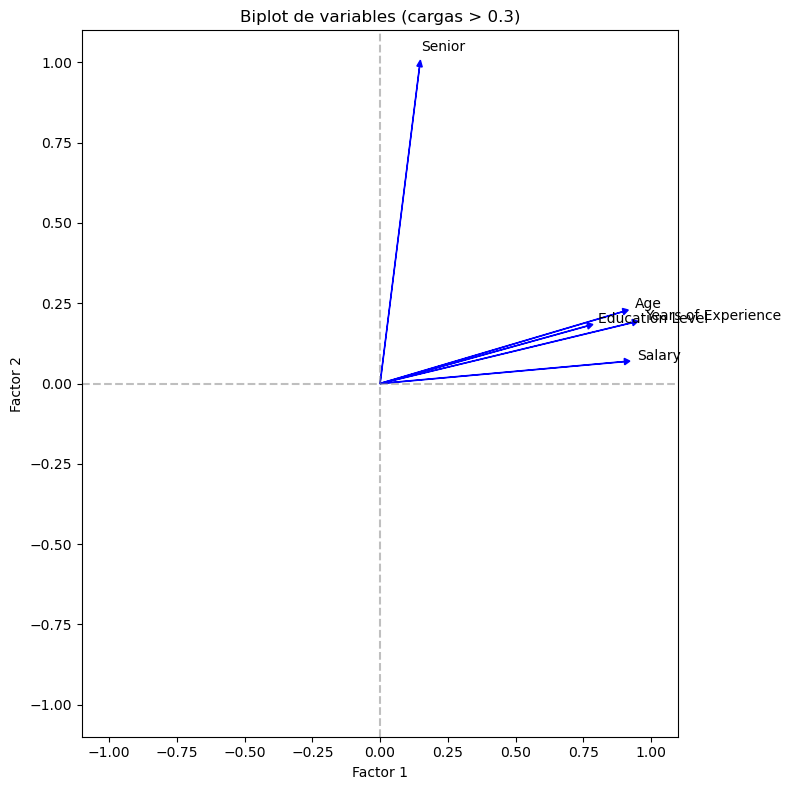

In [138]:
# Representación gráfica biplot de vectores de variables

fig, ax = plt.subplots(figsize=(8, 8))

for var in cargas_biplot.index:
    ax.arrow(0, 0, 
             cargas_biplot.loc[var, 'Factor 1'], 
             cargas_biplot.loc[var, 'Factor 2'],
             head_width=0.02, head_length=0.02, 
             fc='blue', ec='blue')
    ax.text(cargas_biplot.loc[var, 'Factor 1'] * 1.05,
            cargas_biplot.loc[var, 'Factor 2'] * 1.05,
            var, fontsize=10)

ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('Factor 1')
ax.set_ylabel('Factor 2')
ax.set_title('Biplot de variables (cargas > 0.3)')
plt.tight_layout()
plt.show()

### Pregunta 15 ###
Según los resultados mostrados, ¿Qué interpretación podemos hacer de los porcentajes de comunalidades y unicidades? En caso de obtener unicidades por debajo de 0, ¿A qué se debe?. Analizando el diagrama biplot, ¿Qué podemos concluir acerca de las variables representadas?

***Respuesta:***


**Comunalidades y unicidades:**
Los 2 factores explican bien la mayoría de las variables. `Senior` (99.58%) 
y `Years of Experience` (90.34%) son las mejor explicadas, mientras que 
`Education Level` (61.80%) es la que menor comunalidad tiene. Su unicidad 
del 38.20% indica que casi 4 de cada 10 puntos de varianza de esta variable 
son específicos de ella y no están capturados por los factores. No se 
obtienen unicidades negativas en nuestro caso.

**¿A qué se deben las unicidades negativas?**
Tengo entendido que las unicidades negativas ocurren cuando 
el modelo factorial sobreestima las comunalidades.
Es decir, los factores "explican" más varianza de la 
que realmente existe en la variable. Esto sucede cuando se 
extraen demasiados factores respecto al tamaño muestral, cuando hay 
multicolinealidad extrema entre variables, o cuando el número de variables 
es muy pequeño y creo que son un indicador de inestabilidad.

**Análisis del biplot:**
Todas las variables tienen cargas superiores a 0.3 en algún factor por 
lo que todas están representadas. Se observan claramente dos grupos:

- `Age`, `Years of Experience`, `Salary` y `Education Level` apuntan 
en la misma dirección sobre el Factor 1 (eje horizontal), confirmando 
que representan una dimensión común de trayectoria profesional.
- `Senior` apunta casi exclusivamente en la dirección del Factor 2 
(eje vertical), confirmando su independencia del resto de variables 
y su papel como dimensión de seniority pura.

Seguimos con el diseño de nuestro modelo para intentar distinguir entre *Male* y *Female* para cada uno de los registros del conjunto de datos. Para ello vamos a tratar de modelar la regresión logística.

Vamos a tratar de reducir la dimensionalidad de nuestro conjunto de variables predictoras aplicando un método de regularización. De esta forma trataremos de diseñar un modelo de regresión logística con regularización que evite en la medida de lo posible la multicolinealidad y manteniendo la máxima información posible acerca de nuestra variable objetivo. 

En los siguientes bloques de código, se ha de terminar de transformar el conjunto de datos para que pueda ser utilizado en un modelo de regresión logística. Ya se realizó la binarización de la variable objetivo ***Gender*** pero ahora queda normalizar, estandarizar y demás operaciones que considere el alumno oportunas para este modelo.

## Preparación de datos para Regresión Logística

### Normalización y estandarización
Las variables numéricas se estandarizan con `StandardScaler` antes de 
entrenar el modelo. Considero que esto es especialmente importante para la regularización 
LASSO ya que esta penaliza los coeficientes y si las variables tienen escalas 
distintas, la penalización sería muy abritraria.

### Codificación de categóricas
`Gender` ya fue codificada como variable binaria (Male=1, Female=0) 
durante la fase de preparación de datos.

Para `Job Title`, en su momento, aplicaremos One-Hot Encoding dada la relación moderada 
detectada con Gender (V de Cramér=0.42) y porque la Pregunta 16 requiere 
interpretar coeficientes de categorías específicas como `Receptionist` y 
`Front End Developer`.

`Race` también se incluye con One-Hot Encoding para verificar empíricamente 
su aportación, aunque la V de Cramér con Gender era prácticamente nula (0.03). 
El análisis progresivo de modelos confirmó que Race no mejora el Pseudo R² 
(0.156 vs 0.157), validando empíricamente su escasa relevancia.

### Reducción de dimensionalidad
Para reducir la multicolinealidad entre las variables numéricas aplicamos 
el análisis factorial previo, obteniendo 2 factores:
- **Factor 1** (trayectoria profesional): captura Age, Years of Experience y Salary
- **Factor 2** (seniority): captura Senior

`Education Level`, ademas en uno de los intentos, se propone mantener como variable independiente por su alta 
unicidad (38.20%), ya que consideramos que es información que los factores no capturan y que poddria ayudar a mejorar
la R².

El modelo final utiliza como variables predictoras:
- Factor 1 y Factor 2 (scores factoriales)
- Education Level
- Job Title OHE (con `Other` como referencia)
- Race OHE (con `Unknown` como referencia)

Una vez preparados los datos, pasamos a modelar la regresión logísitica aplicando una regularización LASSO. Queda a discreción del alumno la configuración del algoritmo de optimización de la función de coste y la fuerza de la regularización. Se deberán mostrar como resultado del entrenamiento los coeficientes de la regresión con la desviación estandar de los errores en su estimación, el logaritmo de la verosimilitud, el de logaritmo de la verosimilitud del modelo nulo, el pseudo-R2 y las métricas AIC y BIC.

## Regresión Logística con regularización LASSO
### Análisis progresivo de modelos

Construimos los modelos de forma progresiva para entender qué variables 
aportan información sobre `Gender` y cuál es el límite predictivo 
de nuestro dataset.

### Modelo 1 - Variables originales
Primer intento con las 5 variables originales sin ninguna transformación adicional.

In [139]:
# Variables
X_m1 = df[['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']].reset_index(drop=True)
y_m1 = y_log.reset_index(drop=True)

# Split
X_m1_train, X_m1_test, y_m1_train, y_m1_test = train_test_split(
    X_m1, y_m1, test_size=0.2, random_state=42)

# Estandarizar
scaler_m1 = StandardScaler()
X_m1_train_sc = pd.DataFrame(scaler_m1.fit_transform(X_m1_train), columns=X_m1.columns)
X_m1_test_sc = pd.DataFrame(scaler_m1.transform(X_m1_test), columns=X_m1.columns)

# LASSO
X_m1_train_sm = sm.add_constant(X_m1_train_sc)

modelo_m1 = sm.Logit(y_m1_train.reset_index(drop=True), 
                      X_m1_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m1.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.6695844886338201
            Iterations: 74
            Function evaluations: 74
            Gradient evaluations: 74
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5246
Method:                           MLE   Df Model:                            5
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                 0.02528
Time:                        22:47:55   Log-Likelihood:                -3516.4
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                 1.620e-37
                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------

### Modelo 2 - Solo Factor 1
Usamos únicamente el Factor 1 (trayectoria profesional) como predictor atendiendo al criterio de Kaiser.

In [140]:
# 1. Scores factoriales de los 2 factores
scores_factoriales = pd.DataFrame(
    X_log_scaled @ eigenvectors[:, :2],
    columns=['Factor 1', 'Factor 2']
).reset_index(drop=True)

# 2. Ajuste de modelo Logit con el primer factor
X_m2 = scores_factoriales[['Factor 1']].reset_index(drop=True)
y_m2 = y_log.reset_index(drop=True)

X_m2_train, X_m2_test, y_m2_train, y_m2_test = train_test_split(
    X_m2, y_m2, test_size=0.2, random_state=42)

scaler_m2 = StandardScaler()
X_m2_train_sc = pd.DataFrame(scaler_m2.fit_transform(X_m2_train), columns=X_m2.columns)
X_m2_test_sc = pd.DataFrame(scaler_m2.transform(X_m2_test), columns=X_m2.columns)

X_m2_train_sm = sm.add_constant(X_m2_train_sc)

modelo_m2 = sm.Logit(y_m2_train.reset_index(drop=True),
                      X_m2_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m2.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.6814502428987325
            Iterations: 16
            Function evaluations: 16
            Gradient evaluations: 16
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5250
Method:                           MLE   Df Model:                            1
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                0.007960
Time:                        22:47:58   Log-Likelihood:                -3578.9
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                 3.498e-14
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------


### Modelo 3 - 2 Factores

In [141]:
### Modelo 3 - Factor 1 y Factor 2. Añadimos el Factor 2 (seniority) al modelo.

X_m3 = scores_factoriales[['Factor 1', 'Factor 2']].reset_index(drop=True)
y_m3 = y_log.reset_index(drop=True)

X_m3_train, X_m3_test, y_m3_train, y_m3_test = train_test_split(
    X_m3, y_m3, test_size=0.2, random_state=42)

scaler_m3 = StandardScaler()
X_m3_train_sc = pd.DataFrame(scaler_m3.fit_transform(X_m3_train), columns=X_m3.columns)
X_m3_test_sc = pd.DataFrame(scaler_m3.transform(X_m3_test), columns=X_m3.columns)

X_m3_train_sm = sm.add_constant(X_m3_train_sc)

modelo_m3 = sm.Logit(y_m3_train.reset_index(drop=True),
                      X_m3_train_sm).fit_regularized(
    method='l1', alpha=0.01, maxiter=1000)

print(modelo_m3.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.6812650963460446
            Iterations: 24
            Function evaluations: 24
            Gradient evaluations: 24
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5249
Method:                           MLE   Df Model:                            2
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                0.008218
Time:                        22:48:00   Log-Likelihood:                -3578.0
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                 1.329e-13
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------


### Modelo 4 - 2 Factores + Education Level
Añadimos Education Level por su alta unicidad (38.20%) — información 
que los factores no capturan.

In [142]:
X_m4 = pd.concat([
    scores_factoriales[['Factor 1', 'Factor 2']],
    df['Education Level'].reset_index(drop=True)
], axis=1)

y_m4 = y_log.reset_index(drop=True)

X_m4_train, X_m4_test, y_m4_train, y_m4_test = train_test_split(
    X_m4, y_m4, test_size=0.2, random_state=42)

scaler_m4 = StandardScaler()
X_m4_train_sc = pd.DataFrame(scaler_m4.fit_transform(X_m4_train), columns=X_m4.columns)
X_m4_test_sc = pd.DataFrame(scaler_m4.transform(X_m4_test), columns=X_m4.columns)

X_m4_train_sm = sm.add_constant(X_m4_train_sc)

modelo_m4 = sm.Logit(y_m4_train.reset_index(drop=True),
                      X_m4_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m4.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.6763844559407041
            Iterations: 40
            Function evaluations: 40
            Gradient evaluations: 40
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5248
Method:                           MLE   Df Model:                            3
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                 0.01535
Time:                        22:48:02   Log-Likelihood:                -3552.3
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                 7.469e-24
                      coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------

### Modelo 5 - 2 Factores + Education Level + Job Area OHE
Añadimos el área funcional del puesto de trabajo.

In [143]:
df_log = df.copy()
df_log['Job Title'] = df_original.loc[df_log.index, 'Job Title']
df_log['Job Title'] = df_log['Job Title'].fillna('Other')
df_log['Job Area'] = df_log['Job Title'].apply(get_area_v2)
df_log = df_log.drop(columns=['Job Title'])

print(df_log['Job Area'].value_counts())

Job Area
Tech                      2283
Marketing                 1004
Data                       972
Corporate & Operations     568
Sales & Customer           474
Product & Design           426
HR                         413
Finance                    202
Research                   198
Other                       26
Name: count, dtype: int64


In [144]:
job_area_dummies_m5 = pd.get_dummies(df_log['Job Area'], drop_first=False).astype(int).reset_index(drop=True)
job_area_dummies_m5 = job_area_dummies_m5.drop(columns=['Other'], errors='ignore')

X_m5 = pd.concat([
    scores_factoriales[['Factor 1', 'Factor 2']],
    df['Education Level'].reset_index(drop=True),
    job_area_dummies_m5
], axis=1)

y_m5 = y_log.reset_index(drop=True)

X_m5_train, X_m5_test, y_m5_train, y_m5_test = train_test_split(
    X_m5, y_m5, test_size=0.2, random_state=42)

scaler_m5 = StandardScaler()
X_m5_train_sc = pd.DataFrame(scaler_m5.fit_transform(X_m5_train), columns=X_m5.columns)
X_m5_test_sc = pd.DataFrame(scaler_m5.transform(X_m5_test), columns=X_m5.columns)

X_m5_train_sm = sm.add_constant(X_m5_train_sc)

modelo_m5 = sm.Logit(y_m5_train.reset_index(drop=True),
                      X_m5_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m5.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.6472391478943526
            Iterations: 150
            Function evaluations: 150
            Gradient evaluations: 150
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5239
Method:                           MLE   Df Model:                           12
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                 0.05783
Time:                        22:48:07   Log-Likelihood:                -3399.0
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                 8.243e-82
                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------

### Modelo 6 - 2 Factores + Education Level + Job Title completo OHE
Usamos los 129 Job Titles directamente con OHE.

In [145]:
# Normalizar todos los Job Titles a title case (primera letra de cada palabra en mayúscula)
df_original_corrected = df_original.copy()
df_original_corrected['Job Title'] = df_original_corrected['Job Title'].str.title().str.strip()

In [146]:

job_title_corr = df_original_corrected.loc[df.index, 'Job Title'].fillna('Other')
job_title_corr = job_title_corr.str.title().str.strip()

job_title_dummies_corr = pd.get_dummies(job_title_corr, drop_first=False).astype(int).reset_index(drop=True)
job_title_dummies_corr = job_title_dummies_corr.drop(columns=['Other'], errors='ignore')

X_m6_corr = pd.concat([
    scores_factoriales[['Factor 1', 'Factor 2']],
    df['Education Level'].reset_index(drop=True),
    job_title_dummies_corr
], axis=1)

y_m6_corr = y_log.reset_index(drop=True)

X_m6_corr_train, X_m6_corr_test, y_m6_corr_train, y_m6_corr_test = train_test_split(
    X_m6_corr, y_m6_corr, test_size=0.2, random_state=42)

scaler_m6_corr = StandardScaler()
X_m6_corr_train_sc = pd.DataFrame(scaler_m6_corr.fit_transform(X_m6_corr_train), 
                                    columns=X_m6_corr.columns).reset_index(drop=True)

X_m6_corr_train_sm = sm.add_constant(X_m6_corr_train_sc)

modelo_m6_corr = sm.Logit(y_m6_corr_train.reset_index(drop=True),
                           X_m6_corr_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m6_corr.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.5820774281019195
            Iterations: 382
            Function evaluations: 383
            Gradient evaluations: 382
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5135
Method:                           MLE   Df Model:                          116
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                  0.1530
Time:                        22:48:15   Log-Likelihood:                -3055.6
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                9.945e-161
                                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

### Modelo 7 - 2 Factores + Education Level + Job Title completo + Race
Añadimos Race para ver si aporta información adicional sobre Gender.

In [147]:
race_dummies_m7_corr = pd.get_dummies(
    df_original_corrected.loc[df.index, 'Race'].fillna('Unknown'),
    drop_first=False).astype(int).reset_index(drop=True)
race_dummies_m7_corr = race_dummies_m7_corr.drop(columns=['Unknown'], errors='ignore')

X_m7_corr = pd.concat([
    scores_factoriales[['Factor 1', 'Factor 2']],
    df['Education Level'].reset_index(drop=True),
    job_title_dummies_corr,
    race_dummies_m7_corr
], axis=1)

y_m7_corr = y_log.reset_index(drop=True)

X_m7_corr_train, X_m7_corr_test, y_m7_corr_train, y_m7_corr_test = train_test_split(
    X_m7_corr, y_m7_corr, test_size=0.2, random_state=42)

scaler_m7_corr = StandardScaler()
X_m7_corr_train_sc = pd.DataFrame(scaler_m7_corr.fit_transform(X_m7_corr_train),
                                    columns=X_m7_corr.columns).reset_index(drop=True)

X_m7_corr_train_sm = sm.add_constant(X_m7_corr_train_sc)

modelo_m7_corr = sm.Logit(y_m7_corr_train.reset_index(drop=True),
                           X_m7_corr_train_sm).fit_regularized(
    method='l1', alpha=0.1, maxiter=1000)

print(modelo_m7_corr.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.5817021981493243
            Iterations: 393
            Function evaluations: 393
            Gradient evaluations: 393
                           Logit Regression Results                           
Dep. Variable:                 Gender   No. Observations:                 5252
Model:                          Logit   Df Residuals:                     5127
Method:                           MLE   Df Model:                          124
Date:                Mon, 29 Jun 2026   Pseudo R-squ.:                  0.1466
Time:                        22:48:25   Log-Likelihood:                -3078.9
converged:                       True   LL-Null:                       -3607.6
Covariance Type:            nonrobust   LLR p-value:                6.925e-148
                                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

In [148]:
resumen_corr = pd.DataFrame({
    'Log-Likelihood': [m.llf for m in [modelo_m1, modelo_m2, modelo_m3, modelo_m4, 
                                        modelo_m5, modelo_m6_corr, modelo_m7_corr]],
    'LL-Null': [m.llnull for m in [modelo_m1, modelo_m2, modelo_m3, modelo_m4,
                                    modelo_m5, modelo_m6_corr, modelo_m7_corr]],
    'Pseudo R²': [m.prsquared for m in [modelo_m1, modelo_m2, modelo_m3, modelo_m4,
                                         modelo_m5, modelo_m6_corr, modelo_m7_corr]],
    'AIC': [m.aic for m in [modelo_m1, modelo_m2, modelo_m3, modelo_m4,
                              modelo_m5, modelo_m6_corr, modelo_m7_corr]],
    'BIC': [m.bic for m in [modelo_m1, modelo_m2, modelo_m3, modelo_m4,
                              modelo_m5, modelo_m6_corr, modelo_m7_corr]]
}, index=['M1 - Variables originales', 'M2 - Factor 1', 'M3 - Factor 1 + Factor 2',
          'M4 - 2 Factores + Edu Level', 'M5 - 2 Factores + Edu + Job Area',
          'M6 - 2 Factores + Edu + Job Title (corr)', 
          'M7 - 2 Factores + Edu + Job Title + Race (corr)']).round(3)

print(resumen_corr)

                                                 Log-Likelihood   LL-Null  \
M1 - Variables originales                             -3516.434 -3607.649   
M2 - Factor 1                                         -3578.933 -3607.649   
M3 - Factor 1 + Factor 2                              -3578.000 -3607.649   
M4 - 2 Factores + Edu Level                           -3552.261 -3607.649   
M5 - 2 Factores + Edu + Job Area                      -3399.007 -3607.649   
M6 - 2 Factores + Edu + Job Title (corr)              -3055.644 -3607.649   
M7 - 2 Factores + Edu + Job Title + Race (corr)       -3078.919 -3607.649   

                                                 Pseudo R²       AIC       BIC  
M1 - Variables originales                            0.025  7044.868  7084.266  
M2 - Factor 1                                        0.008  7161.865  7174.998  
M3 - Factor 1 + Factor 2                             0.008  7161.999  7181.698  
M4 - 2 Factores + Edu Level                          0.015 

### Pregunta 16 ###
En vista de las métricas y resultados obtenidos, ¿qué tal ha predicho los valores del conjunto de entrenamiento? A partir de los coeficientes estimados, ¿Qué interpretación hacemos de los odds de la categoría *Mixed* de la variable ***Race*** y las categorías *Receptionist* y *Front End Developer* de la variable ***Job Title***? ¿Qué interpretamos del valor obtenido de la métrica Pseudo-R2?

***Respuesta:***

**¿Qué tal ha predicho el modelo los valores del conjunto de entrenamiento?**

Se realizó un análisis progresivo de 7 modelos para tratar de maximizar la capacidad 
predictiva sobre `Gender`, si bien hubo mejoras, el modelo es muy limitado como veremos a 
continuación:

| Modelo | Variables | Pseudo R² | AIC | BIC |
|--------|-----------|-----------|-----|-----|
| M1 | 5 variables originales | 0.025 | 7,044 | 7,084 |
| M2 | Factor 1 | 0.008 | 7,161 | 7,175 |
| M3 | Factor 1 + Factor 2 | 0.008 | 7,162 | 7,182 |
| M4 | 2 Factores + Education Level | 0.015 | 7,112 | 7,139 |
| M5 | 2 Factores + Edu + Job Area | 0.058 | 6,824 | 6,909 |
| M6 | 2 Factores + Edu + Job Title (corr.) | 0.153 | 6,345 | 7,114 |
| M7 | 2 Factores + Edu + Job Title + Race (corr.) | 0.147 | 6,408 | 7,229 |


El mejor modelo en Pseudo R² y AIC es M6, con Job Title como única 
variable adicional. Añadir Race en M7 empeora el modelo ligeramente 
(Pseudo R² baja de 0.153 a 0.147), confirmando empíricamente que Race 
no aporta información relevante para predecir Gender. El BIC por su parte favorece
al modelo 5 con la reclasificacion de job title por Areas.

**Interpretación de los odds (modelo M7 corregido):**

Los odds se calculan como e^coeficiente:
- Odds > 1 → mayor probabilidad de ser Male (1)
- Odds < 1 → mayor probabilidad de ser Female (0)

- **Race = Mixed** (coef=0.011, p=0.845): 
  odds = e^0.011 = 1.011. Prácticamente neutro y no significativo — 
  pertenecer a la categoría Mixed no modifica la probabilidad de ser 
  Male respecto a la categoría de referencia. Confirma empíricamente 
  la irrelevancia de Race para predecir Gender.

- **Job Title = Receptionist** (coef=-0.879, p=0.396): 
  odds = e^-0.879 = 0.415. Sugiere que ser Receptionist reduce la 
  probabilidad de ser Male, y en consecuencia es más probable ser Female. 
  Sin embargo el coeficiente no es estadísticamente significativo (p=0.396), 
  probablemente por el reducido número de registros (56).

- **Job Title = Front End Developer** (coef=-0.027, p=0.699): 
  odds = e^-0.027 = 0.973. Prácticamente neutro y no significativo. 
  Antes de corregir la capitalización (`Front End Developer` vs 
  `Front end Developer`), el modelo separaba 30 y 238 registros 
  respectivamente, produciendo un coeficiente artificialmente positivo 
  (0.491) para la versión con mayúsculas. Tras unificar los 268 
  registros, el coeficiente se acerca a 0, revelando que este puesto 
  no tiene asociación significativa con ningún género.

**¿Qué interpretamos del Pseudo R²?**

El Pseudo R² máximo obtenido es 0.153, lo que se considera un valor bajo (aceptable >0.2). 
Esto indica que las variables disponibles tienen una capacidad predictiva 
muy limitada sobre Gender. Creo que en este sentido una posible conclusión es que el género de una persona 
no está determinado de forma sistemática por su salario, experiencia, 
educación o puesto de trabajo, o al menos no con la suficiente consistencia 
como para que un modelo estadístico lo capture bien con un Pseudo R² 
satisfactorio.

Para el conjunto de validación, utilizar el modelo entrenado para validarlo a través de métricas de validación como la precisión, exactitud, sensibilidad, etc., obtenidas a partir de la matriz de confusión. Mostrar la gráfica de la curva ROC y calcular el area bajo la curva.

### Validación del modelo - Curva ROC
Evaluamos el modelo M6 (mejor AIC y Pseudo R²) sobre el conjunto de test.

In [149]:
# Clasificar los registros del conjunto de validación aplicando el modelo entrenado

# Estandarizar test con el scaler de M6
X_m6_corr_test_sc = pd.DataFrame(
    scaler_m6_corr.transform(X_m6_corr_test),
    columns=X_m6_corr.columns).reset_index(drop=True)

X_m6_corr_test_sm = sm.add_constant(X_m6_corr_test_sc, has_constant='add')

# Asegurar que las columnas del test coinciden con las del train
train_cols = modelo_m6_corr.model.exog_names
X_m6_corr_test_sm = X_m6_corr_test_sm.reindex(columns=train_cols, fill_value=0)

# Predicciones de probabilidad
y_pred_prob = modelo_m6_corr.predict(X_m6_corr_test_sm)
y_test_reset = y_m6_corr_test.reset_index(drop=True)

# Clasificación con umbral 0.6
y_pred_class = (y_pred_prob >= 0.6).astype(int)

print(f"Registros clasificados: {len(y_pred_class)}")
print(f"Predichos como Male (1): {y_pred_class.sum()}")
print(f"Predichos como Female (0): {(y_pred_class == 0).sum()}")

Registros clasificados: 1314
Predichos como Male (1): 685
Predichos como Female (0): 629


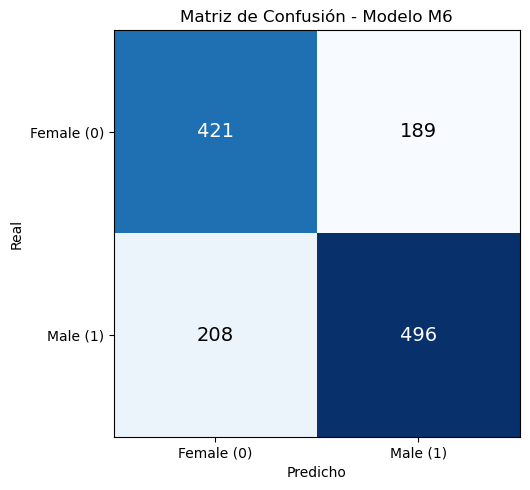

              precision    recall  f1-score   support

  Female (0)       0.67      0.69      0.68       610
    Male (1)       0.72      0.70      0.71       704

    accuracy                           0.70      1314
   macro avg       0.70      0.70      0.70      1314
weighted avg       0.70      0.70      0.70      1314



In [150]:
# Calcular la matriz de confusión y sus métricas
cm = confusion_matrix(y_test_reset, y_pred_class)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Female (0)', 'Male (1)'])
ax.set_yticklabels(['Female (0)', 'Male (1)'])
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión - Modelo M6')

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                fontsize=14, color='white' if cm[i, j] > cm.max()/2 else 'black')

plt.tight_layout()
plt.show()

print(classification_report(y_test_reset, y_pred_class,
                            target_names=['Female (0)', 'Male (1)']))

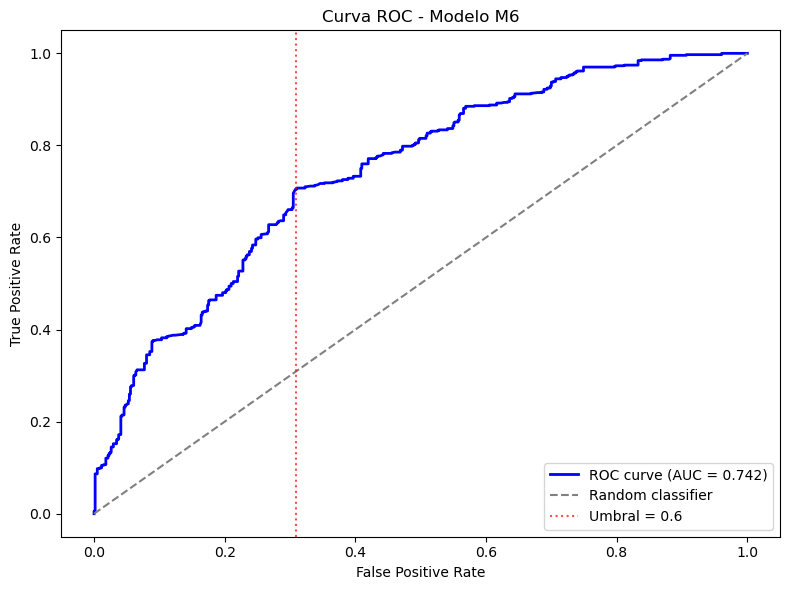

AUC: 0.742


In [151]:
# Mostrar la curva ROC y calcular el area bajo la curva.

fpr, tpr, thresholds = roc_curve(y_test_reset, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
plt.axvline(x=fpr[np.argmin(np.abs(thresholds - 0.6))], 
            color='red', linestyle=':', alpha=0.7, label='Umbral = 0.6')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC - Modelo M6')
plt.legend()
plt.tight_layout()
plt.show()

print(f"AUC: {roc_auc:.3f}")

### Comparación de modelos en validación
Además del modelo M6 (Job Title OHE completo), se valida también el modelo M5 
(Job Area OHE) para comparar su capacidad predictiva real 
sobre el conjunto de test y determinar cuál ofrece mejores métricas 
de clasificación.

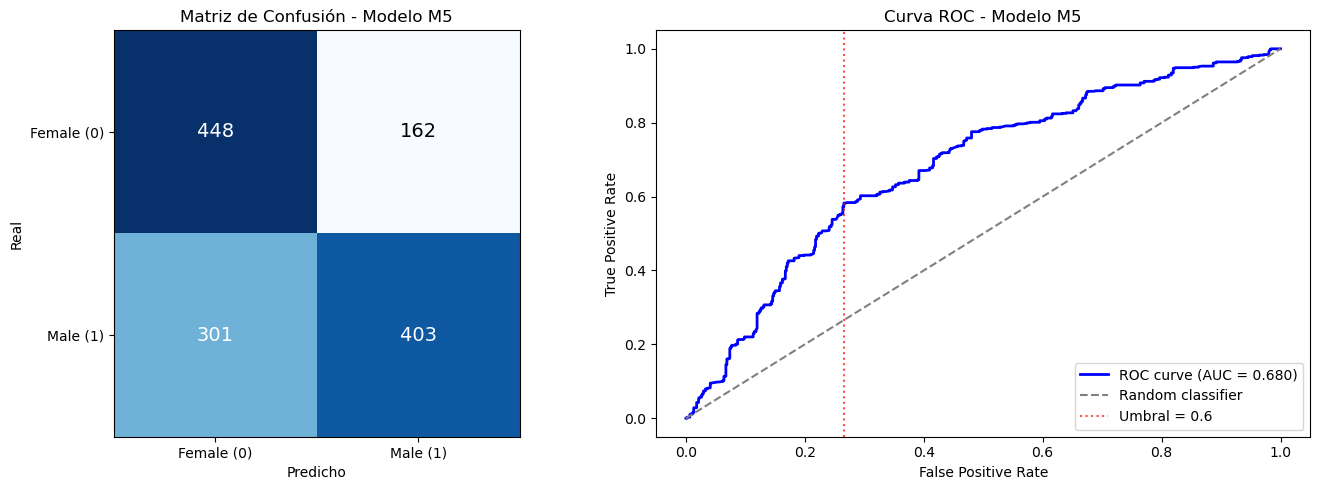

              precision    recall  f1-score   support

  Female (0)       0.60      0.73      0.66       610
    Male (1)       0.71      0.57      0.64       704

    accuracy                           0.65      1314
   macro avg       0.66      0.65      0.65      1314
weighted avg       0.66      0.65      0.65      1314

AUC: 0.680


In [152]:

# Estandarizar test con el scaler de M5
X_m5_test_sc = pd.DataFrame(
    scaler_m5.transform(X_m5_test),
    columns=X_m5.columns).reset_index(drop=True)

X_m5_test_sm = sm.add_constant(X_m5_test_sc, has_constant='add')

# Asegurar columnas coinciden con train
train_cols_m5 = modelo_m5.model.exog_names
X_m5_test_sm = X_m5_test_sm.reindex(columns=train_cols_m5, fill_value=0)

# Predicciones
y_pred_prob_m5 = modelo_m5.predict(X_m5_test_sm)
y_test_m5_reset = y_m5_test.reset_index(drop=True)

# Clasificación umbral 0.6
y_pred_class_m5 = (y_pred_prob_m5 >= 0.6).astype(int)

# Matriz de confusión
cm_m5 = confusion_matrix(y_test_m5_reset, y_pred_class_m5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot matriz de confusión
im = axes[0].imshow(cm_m5, cmap='Blues')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Female (0)', 'Male (1)'])
axes[0].set_yticklabels(['Female (0)', 'Male (1)'])
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')
axes[0].set_title('Matriz de Confusión - Modelo M5')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm_m5[i, j], ha='center', va='center',
                fontsize=14, color='white' if cm_m5[i, j] > cm_m5.max()/2 else 'black')

# Curva ROC
fpr_m5, tpr_m5, thresholds_m5 = roc_curve(y_test_m5_reset, y_pred_prob_m5)
roc_auc_m5 = auc(fpr_m5, tpr_m5)

axes[1].plot(fpr_m5, tpr_m5, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_m5:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
axes[1].axvline(x=fpr_m5[np.argmin(np.abs(thresholds_m5 - 0.6))],
                color='red', linestyle=':', alpha=0.7, label='Umbral = 0.6')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Curva ROC - Modelo M5')
axes[1].legend()

plt.tight_layout()
plt.show()

print(classification_report(y_test_m5_reset, y_pred_class_m5,
                            target_names=['Female (0)', 'Male (1)']))
print(f"AUC: {roc_auc_m5:.3f}")

### Pregunta 17 ###
Realizar una interpretación de los resultados obtenidos en las métricas: accuracy y recall (para ambas categorías 0 y 1). ¿Cuál es el valor del area bajo la curva obtenido? ¿Qué conclusión sobre el modelo obtenemos a partir de este valor? ¿Y cual sería la conclusión general del modelo en base a todos los resultados obtenidos?

***Respuesta:***


Se evaluaron dos modelos sobre el conjunto de validación (20% del dataset, 
1,314 registros) con umbral de clasificación de 0.6:

| Modelo | Accuracy | Precision Female | Recall Female | Precision Male | Recall Male | F1 macro | AUC |
|--------|----------|-----------------|---------------|----------------|-------------|----------|-----|
| M5 - Job Area OHE | 0.65 | 0.60 | 0.73 | 0.71 | 0.57 | 0.65 | 0.680 |
| M6 - Job Title OHE | 0.70 | 0.67 | 0.69 | 0.72 | 0.70 | 0.70 | 0.742 |


**Selección del umbral:**
El umbral por defecto de 0.5 producía un sesgo claro hacia Male (recall 
Male=0.83, recall Female=0.48), creo que esto se debe al desbalance inicial en el dataset 
(55% Male, 45% Female). Subir el umbral a 0.6 equilibra el recall entre 
ambas clases y mejora el accuracy general.

**Interpretación de métricas — Modelo M6:**
Con accuracy del 70% y F1 macro de 0.70, el modelo clasifica correctamente 
7 de cada 10 registros. El recall de Female (0.69) y Male (0.70) están 
bien equilibrados, lo que indicaría que el modelo no favorece 
sistemáticamente ninguna clase. La precision de Male (0.72) es ligeramente 
superior a la de Female (0.67), sugiriendo que cuando el modelo predice 
Male acierta con más frecuencia.

**Área bajo la curva ROC:**
El AUC de 0.742 indica que el modelo discrimina correctamente entre Male 
y Female el 74.2% de las veces, un resultado moderado pero coherente 
con el bajo Pseudo R² de 0.153 obtenido en el modelo.

**Conclusión:**
Creo que el modelo M6 ofrece el mejor rendimiento(AUC=0.742, accuracy=70%) de los modelos analizados,
sin embargo creo que los resultados obtenidos son consistentes con la conclusión del análisis de que Gender no es 
predecible con mucha precisión a partir de las variables disponibles en el dataset. El Job Title completo aporta información relevante 
(M6 supera a M5 en todas las métricas) pero insuficiente para construir un clasificador robusto.

Cambiamos de tercio y pasamos ahora a trabajar con todo el conjunto de datos completo (incluyendo la variable ***Gender***) ya que vamos a realizar un clustering sobre todo el conjunto para ver qué grupos o segmentos encontramos más representativos en los datos. Empezaremos cargando un fichero nuevo que contiene los mismos datos pero sin la necesidad de tratar o trabajar nulos y outliers. El fichero se llama *Salary.csv*.

El clustering que vamos a realizar sobre estos datos es un clustering jerarquico aglomerativo. Para ello prepararemos los datos categorizando algunas variables según se considere oportuno, agruparemos categorías de variables categóricas si procede, normalizaremos y/o estandarizaremos, codificaremos variables categóricas, etc. Muchos de estos pasos son comunes con los ejercicios anteriores por lo que será sencillo repetir algunos de estos pasos. Otros podrán añadirse en función de lo que el alumno considere teniendo en cuenta el ejercicio de clusterización que vamos a llevar a cabo.

Las siguientes lineas de código deben llevar a cabo estas transformaciones.

Por sencillez a la hora de interpretar resultados, se recomienda trabajar sobre una copia del conjunto de datos original para poder extraer métricas a partir de los datos sin transformar.

In [153]:
df_cluster = pd.read_csv('Salary.csv')
print(df_cluster.shape)
print(df_cluster.dtypes)
print(df_cluster.head())
print(df_cluster.isnull().sum())

(6684, 9)
Age                    float64
Gender                  object
Education Level          int64
Job Title               object
Years of Experience    float64
Salary                 float64
Country                 object
Race                    object
Senior                   int64
dtype: object
    Age  Gender  Education Level          Job Title  Years of Experience  \
0  32.0    Male                1  Software Engineer                  5.0   
1  28.0  Female                2       Data Analyst                  3.0   
2  45.0    Male                3            Manager                 15.0   
3  36.0  Female                1    Sales Associate                  7.0   
4  52.0    Male                2           Director                 20.0   

     Salary Country      Race  Senior  
0   90000.0      UK     White       0  
1   65000.0     USA  Hispanic       0  
2  150000.0  Canada     White       1  
3   60000.0     USA  Hispanic       0  
4  200000.0     USA     Asian       0  


In [154]:
df_clust = df_cluster.copy()

### Preparación de datos para clustering

Se trabaja sobre una copia del dataset original para poder comparar 
los clusters con los datos sin transformar. Las variables numéricas 
(`Age`, `Years of Experience`, `Salary`) se mantienen como  
variables continuas, ya que considero que en este caso, 
la categorización supondría una pérdida innecesaria de 
información dado que el clustering jerárquico aglomerativo puede calcular 
distancias euclidianas que aprovechan mejor la granularidad de las 
variables continuas. La estandarización resolverá el problema de escala 
entre variables. `Education Level` y `Senior` se mantienen como 
variables ordinales numéricas.

Para las variables categóricas (`Gender`, `Country`, `Race`, `Job Title`) 
se aplicará One-Hot Encoding. `Job Title` se sustituye por `Job Area` 
(10 categorías) dada su alta cardinalidad (128 categorías únicas), 
tratando de reducir la dimensionalidad, pero conservando algo de información  
sobre el perfil profesional.

In [155]:
# Codificación de categóricas
# Gender
df_clust['Gender'] = df_clust['Gender'].map({'Male': 1, 'Female': 0})

# Job Area (usando la función get_area_v2 ya definida)
df_clust['Job Title'] = df_clust['Job Title'].str.title().str.strip()
df_clust['Job Area'] = df_clust['Job Title'].apply(get_area_v2)
df_clust = df_clust.drop(columns=['Job Title'])

# OHE de categóricas
df_clust = pd.get_dummies(df_clust, columns=['Country', 'Race', 'Job Area'], 
                           drop_first=False).astype(int)

print(f"Shape tras codificación: {df_clust.shape}")
print(df_clust.dtypes)

Shape tras codificación: (6684, 31)
Age                                int64
Gender                             int64
Education Level                    int64
Years of Experience                int64
Salary                             int64
Senior                             int64
Country_Australia                  int64
Country_Canada                     int64
Country_China                      int64
Country_UK                         int64
Country_USA                        int64
Race_African American              int64
Race_Asian                         int64
Race_Australian                    int64
Race_Black                         int64
Race_Chinese                       int64
Race_Hispanic                      int64
Race_Korean                        int64
Race_Mixed                         int64
Race_Welsh                         int64
Race_White                         int64
Job Area_Corporate & Operations    int64
Job Area_Data                      int64
Job Area_Finance     

In [156]:
# Normalización / Estandarización

# Variables a estandarizar (numéricas continuas y ordinales)
cols_escalar = ['Age', 'Years of Experience', 'Salary', 'Education Level', 'Senior']

scaler_clust = StandardScaler()
df_clust[cols_escalar] = scaler_clust.fit_transform(df_clust[cols_escalar])

print("Estadísticas tras estandarización:")
print(df_clust[cols_escalar].describe().round(3))
print(f"\nShape final: {df_clust.shape}")

Estadísticas tras estandarización:
            Age  Years of Experience    Salary  Education Level    Senior
count  6684.000             6684.000  6684.000         6684.000  6684.000
mean      0.000                0.000     0.000           -0.000     0.000
std       1.000                1.000     1.000            1.000     1.000
min      -1.660               -1.339    -2.177           -1.843    -0.409
25%      -0.739               -0.842    -0.858           -0.707    -0.409
50%      -0.212               -0.179    -0.006           -0.707    -0.409
75%       0.578                0.651     0.846            0.429    -0.409
max       3.738                4.299     2.551            1.565     2.443

Shape final: (6684, 31)


A continuación procedemos a definir la función de enlace para el algoritmo jerarquico aglomerativo. Se requiere porbar al menos 2 funciones de enlace y hacer todo el proceso de clusterización completo para dichas funciones. Crear las matrices de distancias basadas en dichas funciones y mostrar los dendogramas de la clusterización, a ser posible indicando con colores selección de clusters.

### Clustering Jerárquico Aglomerativo
Probamos dos funciones de enlace:
- **Ward**: minimiza la varianza intra-cluster.
- **Simple**: Usa la distancia mínima entre observaciones 
de dos clusters

In [157]:
# Crear las matrices de distancias para las funciones de enlace escogidas

# Muestra aleatoria para visualización
np.random.seed(42)
idx_sample = np.random.choice(df_clust.index, size=200, replace=False)
df_sample = df_clust.loc[idx_sample]

# Matrices de distancias
Z_ward = linkage(df_sample, method='ward')
Z_single = linkage(df_sample, method='single')


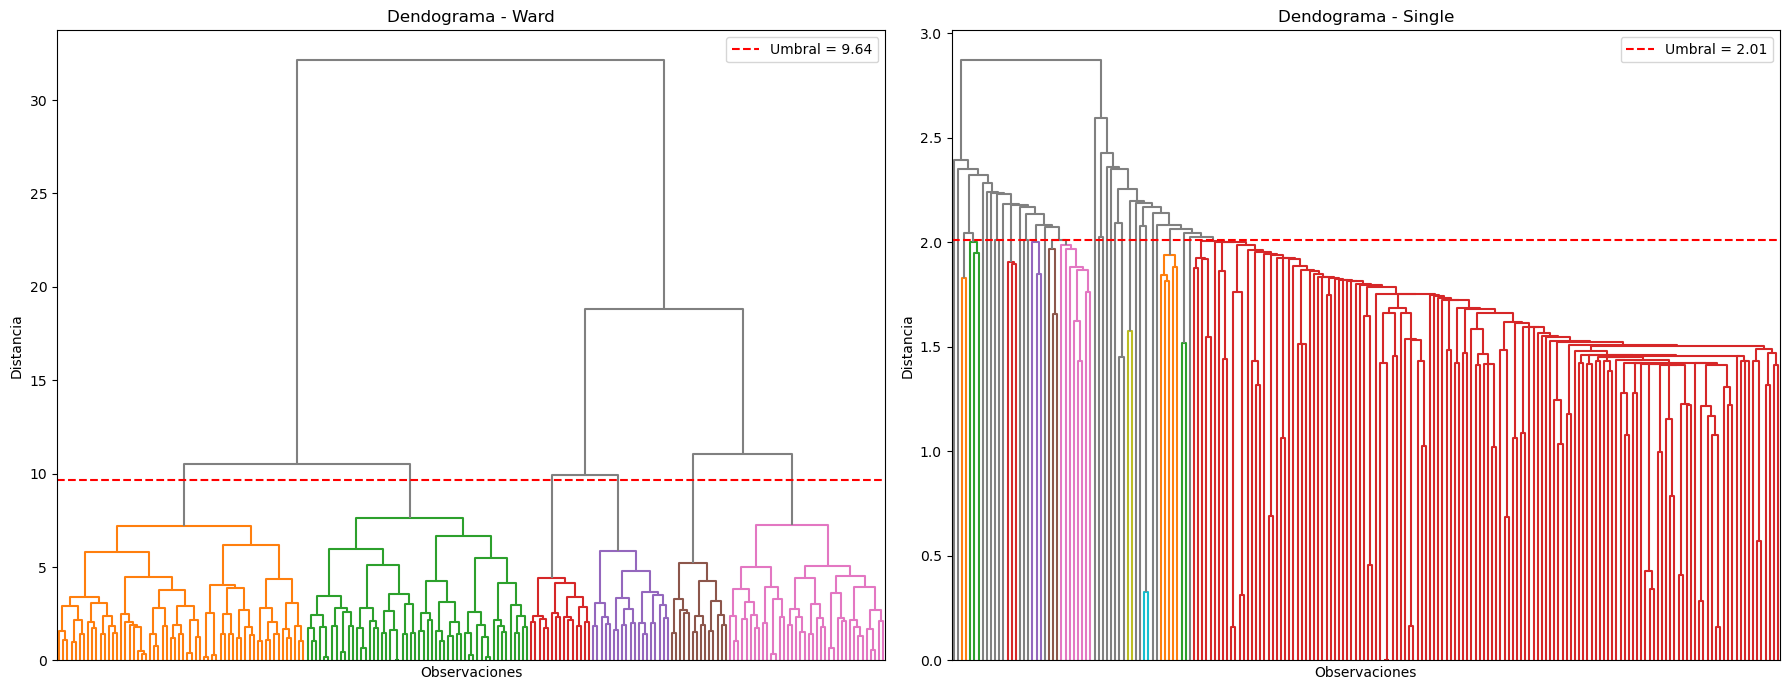

In [158]:
# Umbrales
threshold_ward = 0.3 * max(Z_ward[:,2])
threshold_single = 0.7 * max(Z_single[:,2])

# Dendogramas
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

dendrogram(Z_ward, ax=axes[0], color_threshold=threshold_ward,
           above_threshold_color='gray', no_labels=True)
axes[0].axhline(y=threshold_ward, color='red', linestyle='--', 
                linewidth=1.5, label=f'Umbral = {threshold_ward:.2f}')
axes[0].set_title('Dendograma - Ward')
axes[0].set_xlabel('Observaciones')
axes[0].set_ylabel('Distancia')
axes[0].legend()

dendrogram(Z_single, ax=axes[1], color_threshold=threshold_single,
           above_threshold_color='gray', no_labels=True)
axes[1].axhline(y=threshold_single, color='red', linestyle='--',
                linewidth=1.5, label=f'Umbral = {threshold_single:.2f}')
axes[1].set_title('Dendograma - Single')
axes[1].set_xlabel('Observaciones')
axes[1].set_ylabel('Distancia')
axes[1].legend()

plt.tight_layout()
plt.show()

k=2: Silhouette = 0.2131
k=3: Silhouette = 0.2197
k=4: Silhouette = 0.1850
k=5: Silhouette = 0.1828
k=6: Silhouette = 0.1231
k=7: Silhouette = 0.1150
k=8: Silhouette = 0.1148


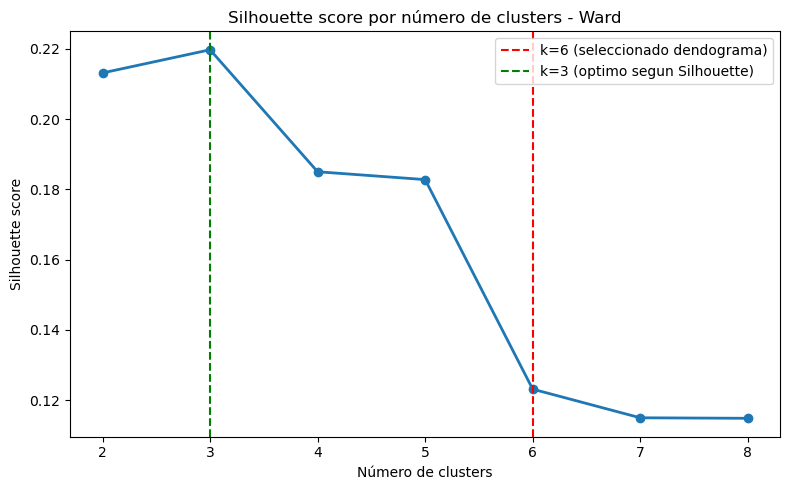

In [159]:
# Calcular Silhouette score para 2-8 clusters sobre dataset completo con Ward
Z_ward_full = linkage(df_clust, method='ward')

silhouette_scores = {}
for n_clusters in range(2, 9):
    labels = fcluster(Z_ward_full, n_clusters, criterion='maxclust')
    score = silhouette_score(df_clust, labels, sample_size=2000, random_state=42)
    silhouette_scores[n_clusters] = score
    print(f"k={n_clusters}: Silhouette = {score:.4f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), 
         marker='o', linewidth=2)
plt.axvline(x=6, color='red', linestyle='--', label='k=6 (seleccionado dendograma)')
plt.axvline(x=3, color='green', linestyle='--', label='k=3 (optimo segun Silhouette)')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette score por número de clusters - Ward')
plt.legend()
plt.tight_layout()
plt.show()

### Pregunta 18 ###
A la vista de los resultados, para cada función de enlace escogida, ¿En cuántos clusters se ha decidido agrupar los datos?

***Respuesta:***

## Pregunta 18

### Selección de la función de enlace
Se probaron dos funciones de enlace, Ward y Simple, representando 
los dos extremos del espectro de métodos jerárquicos aglomerativos.

El dendograma de **Single** confirma el efecto cadena esperado: un 
único cluster masivo absorbe progresivamente el resto de observaciones, 
produciendo una estructura completamente desequilibrada y de dificil
interpretación. Este comportamiento es una limitación 
conocida del enlace simple y por esta razón lo descartamos como método viable para 
nuestros datos.

El dendograma de **Ward** produce una estructura jerárquica clara y 
balanceada, con clusters bien diferenciados y de tamaño comparable, razon por la cual
se selecciona Ward como método definitivo para el análisis.

### Selección del número de clusters
La elección del número óptimo de clusters se apoya en dos criterios 
complementarios que ofrecen resultados distintos:

- **Silhouette score**: favorece **k=3** (score=0.220), indicando que 
3 clusters maximiza la separación entre grupos y la cohesión interna.

- **Dendograma Ward**: visualmente sugiere **k=6** como un número natural posible 
de clusters en los datos.

Ante esta discrepancia, se decide **estudiar ambas soluciones** — k=3 
y k=6 — y compararlas en términos de interpretabilidad y coherencia 
de los grupos resultantes. El análisis del perfil de cada cluster 
permitirá determinar cuál ofrece una segmentación más útil y accionable.

A continuación crear varias columnas nuevas sobre el dataframe original (una por cada función de enlace con que se haya decidido trabajar) y almacenar en ellas para cada registro el número de cluster que le corresponde según la clusterización realizada. Después realizar una serie de agrupaciones y métricas que permitan entender o interpretar la naturaleza de cada cluster.

In [160]:
# Agregar columnas al dataframe original

labels_3 = fcluster(Z_ward_full, 3, criterion='maxclust')
labels_6 = fcluster(Z_ward_full, 6, criterion='maxclust')

# Añadir al dataframe original para interpretar
df_original_clust = df_cluster.copy()
df_original_clust['Cluster_3'] = labels_3
df_original_clust['Cluster_6'] = labels_6

# Ver distribución de clusters
print("Distribución k=3:")
print(df_original_clust['Cluster_3'].value_counts().sort_index())

print("\nDistribución k=6:")
print(df_original_clust['Cluster_6'].value_counts().sort_index())

Distribución k=3:
Cluster_3
1    2923
2     959
3    2802
Name: count, dtype: int64

Distribución k=6:
Cluster_6
1     455
2    2468
3     541
4     418
5     541
6    2261
Name: count, dtype: int64


In [161]:
# Perfil de cada cluster con variables originales
cols_perfil = ['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']

df_original_clust['Job Area'] = df_original_clust['Job Title'].str.title().str.strip().apply(get_area_v2)

# Perfil completo k=3
perfil_3 = df_original_clust.groupby('Cluster_3')[cols_perfil].mean().round(2)
perfil_3['% Female'] = df_original_clust.groupby('Cluster_3')['Gender'].apply(
    lambda x: (x == 'Female').mean()).round(3)

print("=== PERFIL CLUSTERS k=3 ===")
print(perfil_3.to_string())

print("\nJob Area por cluster k=3 (% sobre total del área):")
ct3 = pd.crosstab(df_original_clust['Cluster_3'], 
                  df_original_clust['Job Area'], 
                  normalize='columns') * 100
print(ct3.applymap(lambda x: f'{x:.0f}%').to_string())

# Perfil completo k=6
perfil_6 = df_original_clust.groupby('Cluster_6')[cols_perfil].mean().round(2)
perfil_6['% Female'] = df_original_clust.groupby('Cluster_6')['Gender'].apply(
    lambda x: (x == 'Female').mean()).round(3)

print("\n=== PERFIL CLUSTERS k=6 ===")
print(perfil_6.to_string())

print("\nJob Area por cluster k=6 (% sobre total del área):")
ct6 = pd.crosstab(df_original_clust['Cluster_6'], 
                  df_original_clust['Job Area'], 
                  normalize='columns') * 100
print(ct6.applymap(lambda x: f'{x:.0f}%').to_string())

=== PERFIL CLUSTERS k=3 ===
             Age  Education Level  Years of Experience     Salary  Senior  % Female
Cluster_3                                                                          
1          27.98             1.02                 3.24   68055.41     0.0     0.478
2          39.81             2.21                12.76  144159.35     1.0     0.404
3          37.36             2.05                11.52  154724.62     0.0     0.439

Job Area por cluster k=3 (% sobre total del área):
Job Area  Corporate & Operations Data Finance   HR Marketing Other Product & Design Research Sales & Customer Tech
Cluster_3                                                                                                         
1                            33%  27%     28%  48%       48%    0%              39%       1%              83%  49%
2                            59%   8%      8%  23%        9%   80%               4%      27%               2%  11%
3                             8%  65%   

<project folder> FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(ct3.applymap(lambda x: f'{x:.0f}%').to_string())
<project folder> FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(ct6.applymap(lambda x: f'{x:.0f}%').to_string())


### Pregunta 19 ###
Hacer una interpretación de los resultados para cada función de enlace indicando el sentido que pueda tener cada uno de los clusters.

***Respuesta:***

### Interpretación de los clusters

#### Solución k=3


| Cluster | N | Edad | Salario | YoE | Seniority | % Female | Perfil |
|---------|---|------|---------|-----|-----------|----------|--------|
| 1 | 2,923 | 28 | 68k | 3 años | No | 48% | Junior |
| 2 | 959 | 40 | 144k | 13 años | Sí | 40% | Senior |
| 3 | 2,802 | 37 | 155k | 12 años | No | 44% | Mid-Senior técnico |

**Cluster 1 — Perfil Junior:**
Trabajadores jóvenes (28 años) con poca experiencia (3 años) y salarios 
bajos (68k). Sin seniority. Predominan en áreas de Sales & Customer (83%), 
HR (48%) y Marketing (48%) (areas que creo que tienen mucho que ver con las personas). 
Y con una distribución de género equilibrada (48% Female).

**Cluster 2 — Perfil Senior con Seniority:**
Trabajadores más maduros (40 años) con mucha experiencia (13 años), seniority 
formal y salarios de medios a altos (144k). 
Predominan en Corporate & Operations (59%) y Other (80%)(aunque recordemos que aqui pusimos a los que 
no tenian como una descripcion de area y nulos y que ademas son muy pocos datos creo que 26). 
En este cluster si hay menor proporción de mujeres (40% Female).

**Cluster 3 — Perfil Mid-Senior Técnico:**
Trabajadores de mediana edad (37 años) con experiencia alta (12 años) y 
los salarios más altos (155k) a pesar de no tener seniority formal. 
Dominan claramente en áreas técnicas: 
Data (65%), Finance (64%), Research (73%) y Tech (41%). 
Proporción de género en 44% Female.

#### Solución k=6


| Cluster | N | Edad | Salario | YoE | Seniority | % Female | Perfil |
|---------|---|------|---------|-----|-----------|----------|--------|
| 1 | 455 | 26 | 32k | 1 año | No | 58% | Entry level ventas |
| 2 | 2,468 | 28 | 75k | 4 años | No | 46% | Junior tech/marketing |
| 3 | 541 | 35 | 118k | 9 años | Sí | 43% | Mid senior con seniority |
| 4 | 418 | 46 | 178k | 17 años | Sí | 36% | Senior corporativo |
| 5 | 541 | 47 | 183k | 18 años | No | 20% | Senior data/tech |
| 6 | 2,261 | 35 | 148k | 10 años | No | 50% | Mid senior data/finance |


**Cluster 1 — Entry level ventas:**
El grupo más joven (26 años) y de menor salario (32k). Prácticamente 
exclusivo de Sales & Customer (67%). Mayor proporción de mujeres (58% Female).

**Cluster 2 — Junior tech/marketing:**
Perfil junior amplio (28 años, 75k). Distribuido principalmente en 
Tech (49%) y Marketing (48%). Distribución de género equilibrada (46% Female).

**Cluster 3 — Mid senior con seniority:**
Perfil de transición (35 años, 118k) con seniority formal. Distribuido 
en múltiples áreas sin dominancia clara.

**Cluster 4 — Senior corporativo:**
Trabajadores mas grandes (46 años, 178k) con seniority y alta experiencia 
(17 años). Concentrados en Corporate & Operations (42%) y Other (60%). 
Menor proporción de mujeres (36% Female).

**Cluster 5 — Senior data/tech sin seniority:**
El cluster más interesante — trabajadores mayores (47 años) con los 
salarios más altos (183k) y sin seniority formal. Alta concentración 
en Data (24%) y Tech (12%). El cluster con menor proporción de mujeres 
(20% Female) — el sesgo de género es más pronunciado en perfiles 
técnicos senior.

**Cluster 6 — Mid senior data/finance:**
Perfil medio-senior (35 años, 148k) sin seniority. Domina en áreas 
de alto valor: Data (41%), Finance (64%) y Research (72%). 
Distribución de género completamente equilibrada (50% Female).

### Conclusión
La solución **k=3** ofrece mayor interpretabilidad y está respaldada 
por el Silhouette score y nos permite diferenciar claramente tres arquetipos 
profesionales:
Junior, Senior con Seniority y Mid-Senior Técnico 

La solución **k=6** añade granularidad y hace mas dificil la interpretabilidad de los clusters.